# 3-servo: ladder

Spin the free servo at fifteen duties on the three rails a user's servo sees, 3.7, 5 and 7.4 V, let every spin coast to a stop with the bridge open, and hold slow drives across the point where the rotor stops turning, so the back-EMF constant, the brush drop, the sustaining floor and the steady speed and current per rung are read on mg90-d's motor inside its own servo.

## Purpose

The back-EMF (electromotive force) of a brushed DC motor is the voltage its turning rotor generates. It is $E = K_e\,\omega$, with $K_e$ ("K e") the back-EMF constant and $\omega$ ("omega") the rotor's speed. Under drive the volts applied to the motor carry it beside the winding's drop and the brushes' drop,

$$V = K_e\,\omega + R\,I + V_b,$$

with $V$ the applied volts, $R$ the terminal resistance, $I$ the current and $V_b$ ("V b") the brush drop, the part of the brush contact's voltage that the resistance line does not hold. The firmware's speed estimate solves this line for $\omega$, so it needs $K_e$, $R$ and $V_b$ for the motor at hand. Stage 2 read all three on two bare motors of this family. This notebook reads $K_e$ and $V_b$ on mg90-d's motor inside the assembled servo, with $R$ from the resistance notebook.

The stage README sets these targets.

- $K_e$ from each rung's natural coast, and the EMF at the cut over the ripple tach's speed.
- The brush drop as a speed table per direction, with its coefficient on the dropout rate.
- The breakaway duty against the sustaining floor.
- The steady speed and current per rung, for the friction notebook.
- The dropout rate per rung.

The sustaining floor is the lowest effective voltage at which a rotor that is already turning keeps turning. The effective voltage $V_\mathrm{eff}$ ("V effective") is the rail times the duty. The pot-table plan reads `floor_v_effective` from this notebook's result file to set its crawl duty.

mg90-d is a new motor from a new servo of the same brand, installed in a new, never used MG90 body whose gears were cleaned and regreased by hand with Super Lube. Its motor is not opened, so every number here is read through the servo's two motor leads. The type values come from stage 2, mg90-b the type motor and mg90-c the second motor, and are used for comparison only.

## Procedure

The servo is mg90-d on board dev-v006-2A-D, horn free, powered from the DPS-150 bench supply over the board's feed diode, with the board's adapter on its bus at 3 Mbps. The board runs the experiment image, so every drive is open loop with only the raw current trip and the bus dead-man as protections. The sitting runner, `python -m oscnb.sitting servo`, ran the `ref`, `capture`, `low` and `rail` plans of `stages/3-servo/ladder/plan.py`.

A cycle is one `osc-lab sweep`. It opens with a 500 ms torque-off baseline. Then, in each direction, the servo seeks to the near guard, spins at the rung's duty toward the far guard, and coasts for 400 ms with the bridge open. The rail is trimmed with torque off before each level, and after every drive the horn goes back to mid travel with the torque off.

- `ref`, the bracket, is three cycles of 30 % on 5 V. ref-open-1 and ref-close-1 open and close sitting 1, the servo's first sitting. ref-open-6 and ref-close-6 open and close sitting 6, two days later, after the locked sittings.
- `capture-1` is the ladder, 15, 20, 30, 40 and 60 % on each rail, three cycles a rung, 45 cycles.
- `rail-1` adds the top rung each rail allows, 80 and 100 % on 3.7 V and 67 % on 7.4 V, three cycles each.
- `low-1` kicks the rotor for 150 ms at about 1.45 V effective, 40 % on 3.7 V, 30 % on 5 V and 20 % on 7.4 V, chains a hold at the level's duty for 1.2 s, then coasts. The holds sit at 0.6 down to 0.2 V effective in whole percent of each rail, 17 levels, three cycles each, 51 cycles.

The runway. The travel is about 157 motor revolutions, so a spin is only as long as the travel lets it be. The plan's windows are ceilings, 1.2 s at 15 % down to 300 ms at 60 %, and the runner cuts each so the rung's travel ends short of the far guard. The cut is deep at the top. The 7.4 V 67 % spins last 53 ms. The runner also cut the 16, 12 and 8 % holds, the lowest duties with the longest kicks, to 1117 to 1141 ms. Every drive stays inside the motor's rated 5 V as rail times duty, 7.4 V at 67 % being 4.96 V.

## Data

Everything is under `telemetry/mg90-d__dev-v006-2A-D/`. The seven datasets are in `ladder/`, and the two sittings' manifests are `sittings/servo-1.csv` and `sittings/servo-6.csv`.

The libraries, then the pair and its folders.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import minimize

from oscnb import boards, coast, figures, motors, results, ripple, scales
from oscnb import servos, tel
from oscnb.display import show
from oscnb.figures import BLUE, GREEN, INK, MUTED, ORANGE

In [2]:
SERVO = servos.SERVOS["mg90-d"]         # the servo: pot, train, rated V
MOTOR = motors.MOTORS["mg90-d"]         # its motor, with its counted parts
BOARD_KEY = "dev-v006-2A-D"             # the board, checked on every sweep
PAIR = f"{SERVO.key}__{BOARD_KEY}"      # the pair, the result file's name
PAIR_DIR = (Path("../../../telemetry") / PAIR).resolve()
LADDER = PAIR_DIR / "ladder"            # the seven datasets
# the spin sets: sitting 1's brackets, the ladder, the top rungs, and
# sitting 6's brackets; the low holds are read on their own
SETS = ["ref-open-1", "ref-close-1", "capture-1", "rail-1", "ref-open-6",
        "ref-close-6"]
LOW = "low-1"
SITTING_OF = {"ref-open-1": 1, "ref-close-1": 1, "capture-1": 1,
              "rail-1": 1, "low-1": 1, "ref-open-6": 6, "ref-close-6": 6}
MANIFESTS = {s: PAIR_DIR / "sittings" / f"servo-{s}.csv" for s in (1, 6)}
FS = 20_000                             # rows per second, the control tick
print(SERVO.key, "on", BOARD_KEY, "from", results.rel(LADDER))
print(f"{MOTOR.label}: {MOTOR.slots} slots, {MOTOR.brushes} brushes, "
      f"{MOTOR.ripple_per_rev} ripple events per rev, rows at {FS} Hz")

mg90-d on dev-v006-2A-D from telemetry/mg90-d__dev-v006-2A-D/ladder
the motor of MG90 clone d: 3 slots, 2 brushes, 6 ripple events per rev, rows at 20000 Hz


Every sweep names its board in its own `meta.json`. The board is looked up from that sense block, never assumed, and its check raises if any constant disagrees with the registry.

In [3]:
def board_of(meta, where=""):
    # the board a sweep's meta names, its sense block checked
    board = boards.from_meta(meta)      # identified from the data itself
    if board is None:
        raise ValueError(f"{where}: no board matches {meta['sense']}")
    board.check_meta(meta, where)       # raises on any mismatch
    return board


def load(folder):
    # (frame, meta, board) of one sweep, through the chain
    frame, meta = tel.load(folder)
    return frame, meta, board_of(meta, str(results.rel(folder)))

### Stage 1 values carried in

The current goes through the current-scale result and the terminal and rail volts through the terminal-chain result, both graded on this board in stage 1. Bridge-states gives the low-side loop's resistance, which carries the current while the bridge brakes between its on-windows. Sample-timing gives the lag of the taps' edges behind the commanded window at 3.7 and 7.4 V, interpolated to each rail as stage 2's brush-drop work did.

In [4]:
SCALES = scales.load(BOARD_KEY)         # stage 1's current and volt lines
# multiplied as the stage 2 files were computed, never divided: a ripple
# count downstream turns a last-bit change into a moved result
A_PER_COUNT = SCALES.a_per_count        # amps per count over the zero
V_PER_COUNT = SCALES.v_per_count        # volts per count of tap difference
TAP_OFFSET = SCALES.terminal_offset_counts   # the tap difference's offset
I_DRIVE_OFFSET = SCALES.drive_offset_counts  # the in-drive current offset
BRIDGE = results.read("1-board", "bridge-states", pair=BOARD_KEY)
R_BRK = BRIDGE["low_side_loop_ohm"]["value"]   # ohm, the brake's loop
TIMING = results.read("1-board", "sample-timing", pair=BOARD_KEY)
SCALES.describe()
print(f"a count over the zero is {A_PER_COUNT * 1e3:.3f} mA, a count of tap "
      f"difference {V_PER_COUNT * 1e3:.3f} mV, in-drive offset "
      f"{I_DRIVE_OFFSET:.2f} counts")
print(f"low-side loop {R_BRK:.4f} ohm "
      f"({BRIDGE['low_side_loop_ohm']['lo']:.3f} to "
      f"{BRIDGE['low_side_loop_ohm']['hi']:.3f}), from bridge-states")

current: counts over the zero = +5.3 + 1135.0 x amps (1133.8 to 1136.3), graded over 0.23 to 1.31 A
terminals: tap difference = +2.4 + 248.37 x volts (248.20 to 248.53)
rail: tap = +6.0 + 247.54 x volts at rest
bridge ON edge 40 ticks after the commanded start, shunt crossing 44, OFF edge 14 after the commanded end, shunt settled 72 after the start
fast decay: ON edge 8 ticks after the commanded start, OFF edge 12 after the end
a count over the zero is 0.881 mA, a count of tap difference 4.026 mV, in-drive offset 5.26 counts
low-side loop 0.3008 ohm (0.281 to 0.339), from bridge-states


In [5]:
LAG_RAILS = (3.7, 7.4)                  # V, the rails sample-timing graded


def lags(name, end):
    # one edge lag at the two graded rails, ticks: value, lo or hi
    return tuple(TIMING[f"{name}_{r}"][end] for r in ("3v7", "7v4"))


LAG_ON = lags("tap_on_edge_lag", "value")    # the ON edge's lag
LAG_OFF = lags("off_edge_lag", "value")      # the OFF edge's lag
LAG_ON_LO, LAG_ON_HI = lags("tap_on_edge_lag", "lo"), lags(
    "tap_on_edge_lag", "hi")
LAG_OFF_LO, LAG_OFF_HI = lags("off_edge_lag", "lo"), lags(
    "off_edge_lag", "hi")
for rail, on, off in zip(LAG_RAILS, LAG_ON, LAG_OFF):
    print(f"{rail} V: ON edge lag {on:.1f} ticks, OFF edge lag {off:.1f}")

3.7 V: ON edge lag 37.0 ticks, OFF edge lag 13.0
7.4 V: ON edge lag 42.0 ticks, OFF edge lag 15.0


### Stage 3 values carried in

The resistance notebook's locked 100 % laps into the horn lock give $R$, the number used throughout. The inductance notebook's locked read is the same laps and agrees with it. The resistance result also carries the user's pass under the board terms and the per-volt crest term its sag slope asked for, quoted in the brush drop section. The sag notebook gives this motor's $K_e$ from 26 coasts at 30 % on 6.0 to 8.4 V, its awake zero step, and its crawl at 0.48 V effective.

In [6]:
SAG = results.read("3-servo", "sag", pair=PAIR)
RES = results.read("3-servo", "resistance", pair=PAIR)
IND = results.read("3-servo", "inductance", pair=PAIR)
R_LOCKED = RES["r_term_ohm"]["value"]   # ohm, the locked 100 % laps
R_LOCKED_LO, R_LOCKED_HI = RES["r_term_ohm"]["lo"], RES["r_term_ohm"]["hi"]
R_LOCKED_AMPS = RES["r_term_amps"]["value"]   # A, the laps' current
R_STOP_EDGE_BRAKE = RES["r_stop_edge_brake_ohm"]["value"]   # user's pass
V0_STOP_EDGE_BRAKE = RES["v0_stop_edge_brake_v"]["value"]
G_SAG = RES["sag_slope_g_needed_ms"]    # mS, the term the sag slope asks
G_SAG_SLOPE_S = G_SAG["value"] * 1e-3   # S
# the two results read the brake loop from the same stage 1 file
assert abs(RES["low_side_loop_ohm"]["value"] - R_BRK) < 1e-9
KE_SAG = SAG["ke_mv_per_rev_s"]["value"]          # mV per rev/s
AWAKE_STEP_SAG = SAG["zero_awake_step_counts"]["value"]   # counts
print(f"R {R_LOCKED:.4f} ohm ({R_LOCKED_LO:.4f} to {R_LOCKED_HI:.4f}) at "
      f"{R_LOCKED_AMPS:.3f} A; inductance's locked read "
      f"{IND['r_locked_lap_100_ohm']['value']:.4f}")
print(f"user's pass under the board terms R {R_STOP_EDGE_BRAKE:.4f} ohm, "
      f"V0 {V0_STOP_EDGE_BRAKE:+.4f} V; sag slope asks "
      f"{G_SAG['value']:.2f} mS ({G_SAG['lo']:.2f} to {G_SAG['hi']:.2f})")
print(f"sag: Ke {KE_SAG:.3f} mV per rev/s, awake step "
      f"{AWAKE_STEP_SAG:.2f} counts, crawl "
      f"{SAG['crawl_speed_rev_s']['value']:.1f} rev/s at "
      f"{SAG['crawl_current_ma']['value']:.1f} mA")

R 4.2189 ohm (4.2065 to 4.2300) at 0.767 A; inductance's locked read 4.2189
user's pass under the board terms R 4.2647 ohm, V0 -0.0705 V; sag slope asks 3.22 mS (2.73 to 3.71)
sag: Ke 7.327 mV per rev/s, awake step 9.20 counts, crawl 31.4 rev/s at 71.2 mA


### Stage 2 type values carried in

mg90-b's bemf-coast $K_e$, identification's brush-drop table, no-load-current's drag curve and motor-model's crest terms, with mg90-c's $K_e$ beside them. They are comparisons, and none enters a number computed for mg90-d, except the type's spinning crest term in the comparison construction C below.

In [7]:
TYPE_KEY = SERVO.type_motor             # mg90-b
BC_TYPE = results.read("2-motor", "bemf-coast", pair=TYPE_KEY)
BC_SPREAD = results.read("2-motor", "bemf-coast", pair="mg90-c")
ID_TYPE = results.read("2-motor", "identification", pair=TYPE_KEY)
NL_TYPE = results.read("2-motor", "no-load-current", pair=TYPE_KEY)
MM_TYPE = results.read("2-motor", "motor-model", pair=TYPE_KEY)
KE_TYPE = BC_TYPE["ke_mv_per_rev_s"]    # mV per rev/s, with its bracket
G_SPIN_TYPE_S = MM_TYPE["g_spin_ms"]["value"] * 1e-3    # S, comparison
G_LOCKED_TYPE_MS = MM_TYPE["motor_g_locked_fast_ms"]["value"]
VB_TYPE = ID_TYPE["v_b_mv"]["table"]    # the type's brush-drop table, mV
DRAG_5V = NL_TYPE["drive_drag_by_level"]["5 V"]   # bare drag on 5 V
print(f"{TYPE_KEY}: Ke {KE_TYPE['value']:.3f} mV per rev/s "
      f"({KE_TYPE['lo']:.3f} to {KE_TYPE['hi']:.3f}), mg90-c "
      f"{BC_SPREAD['ke_mv_per_rev_s']['value']:.3f}")
print(f"crest term spinning {G_SPIN_TYPE_S * 1e3:.2f} mS, locked "
      f"{G_LOCKED_TYPE_MS:.2f} mS; brush table at 300 rev/s +1 "
      f"{VB_TYPE['+1']['300 rev/s']['value']:.1f} mV, -1 "
      f"{VB_TYPE['-1']['300 rev/s']['value']:.1f} mV")

mg90-b: Ke 7.341 mV per rev/s (7.292 to 7.367), mg90-c 7.316
crest term spinning 3.35 mS, locked 2.49 mS; brush table at 300 rev/s +1 19.5 mV, -1 12.4 mV


The servo's counted parts, and the constants of the method, each with its unit and reason.

In [8]:
N_R = MOTOR.ripple_per_rev              # ripple events per motor rev
GEAR = SERVO.gear_ratio                 # counted teeth, motor revs per out
# the pot's nominal slope, a sizing number pot-table grades, so speeds
# through it are labelled nominal; never used to derive the gear ratio
COUNTS_PER_OUT_REV = SERVO.counts_per_deg_nominal * 360.0
SPIN_WINDOW_MS = 100                    # ms, the spin's read window
SPIN_WINDOW_MIN_MS = 20                 # ms, never shorter than this
TAIL_ROWS = 2000                        # rows, a coast's last 100 ms
DECEL_FRAC_MAX = 0.35                   # the gate: speed lost in a window
MIN_CYCLES = 4                          # the gate: whole cycles at least
SETTLE_PCT = 2.5                        # %, a settled window's change
LOW_SPEED = 160.0                       # rev/s, identification's floor
KNOTS_ID = np.arange(150.0, 651.0, 50.0)   # identification's knots
KNOTS = np.arange(150.0, 501.0, 50.0)   # the rail-free table's knots
HOLD_TAIL_ROWS = 8000                   # rows, a hold's last 400 ms
BIN_ROWS = 2000                         # rows, 100 ms bins down a hold
TURN_REV_S = 1.0                        # rev/s, a hold under it stopped
SEED_MIN_HZ = 7.5                       # Hz, the hold's ripple seed floor
POT_MOVE_COUNTS = 3                     # counts, the pot left its seat
print(f"{N_R} ripple events per motor rev, gear {GEAR:.2f}:1, pot "
      f"{SERVO.counts_per_deg_nominal} counts per degree (nominal)")

6 ripple events per motor rev, gear 308.05:1, pot 19.8 counts per degree (nominal)


Two helpers the whole notebook uses. The line is an ordinary least-squares fit that keeps its residuals and drops non-finite points. The pot speed is a line through the pot's counts against time, turned into motor revolutions per second through the nominal pot slope and the counted train.

In [9]:
def fit_line(x, y):
    # least-squares line of y on x, its standard errors and residuals
    x = np.asarray(x, float)
    y = np.asarray(y, float)
    ok = np.isfinite(x) & np.isfinite(y)
    x, y = x[ok], y[ok]
    design = np.c_[x, np.ones_like(x)]  # columns: slope, intercept
    coef = np.linalg.lstsq(design, y, rcond=None)[0]
    resid = y - design @ coef           # what the line leaves
    s2 = (resid ** 2).sum() / max(len(x) - 2, 1)   # residual variance
    cov = s2 * np.linalg.inv(design.T @ design)    # coefficients' cov
    return {"slope": coef[0], "intercept": coef[1],
            "slope_se": np.sqrt(cov[0, 0]),
            "intercept_se": np.sqrt(cov[1, 1]), "resid": resid,
            "rms": np.sqrt((resid ** 2).mean()), "n": len(x)}


def pot_speed(pos):
    # (motor rev/s, its se, residual sd) of a line through pot counts
    pos = np.asarray(pos, float)
    fit = fit_line(np.arange(len(pos)) / FS, pos)
    per = GEAR / COUNTS_PER_OUT_REV     # motor revs per pot count
    return fit["slope"] * per, fit["slope_se"] * per, fit["resid"].std()

### cycles.csv

One row per cycle of a dataset. `k` is the cycle number, `volts_set` the rail level, `dps_read` the DPS's readback after the trim, a setpoint echo, `vsys_read` the rail the runner read at the trim, `duty_pct` the rung's duty, `repeat` the cycle within the rung, `t_start` and `t_end` its host times, `folder` its folder, `kick_pct` and `kick_ms` the low holds' kick, and `spin_ms` the window the runner allowed after the runway cut.

In [10]:
CYCLES = {name: pd.read_csv(LADDER / name / "cycles.csv")
          for name in SETS + [LOW]}
show(CYCLES["capture-1"], n=4)
for name, cy in CYCLES.items():
    rails = ", ".join(f"{v:g}" for v in sorted(cy["volts_set"].unique()))
    print(f"{name}: {len(cy)} cycles on {rails} V, duties "
          f"{sorted(cy['duty_pct'].unique())}")

,k,volts_set,dps_read,vsys_read,duty_pct,repeat,t_start,t_end,folder,kick_pct,kick_ms,spin_ms
0,0,3.700,3.950,3.697,15,0,1793935706.530,1793935764.089,cycles/0,0,0,1200
1,1,3.700,3.950,3.697,15,1,1793935784.089,1793935837.547,cycles/1,0,0,1200
2,2,3.700,3.950,3.697,15,2,1793935857.550,1793935911.164,cycles/2,0,0,1200
3,3,3.700,3.950,3.697,20,0,1793935931.170,1793935984.298,cycles/3,0,0,1000


ref-open-1: 3 cycles on 5 V, duties [np.int64(30)]
ref-close-1: 3 cycles on 5 V, duties [np.int64(30)]
capture-1: 45 cycles on 3.7, 5, 7.4 V, duties [np.int64(15), np.int64(20), np.int64(30), np.int64(40), np.int64(60)]
rail-1: 9 cycles on 3.7, 7.4 V, duties [np.int64(67), np.int64(80), np.int64(100)]
ref-open-6: 3 cycles on 5 V, duties [np.int64(30)]
ref-close-6: 3 cycles on 5 V, duties [np.int64(30)]
low-1: 51 cycles on 3.7, 5, 7.4 V, duties [np.int64(3), np.int64(4), np.int64(5), np.int64(6), np.int64(7), np.int64(8), np.int64(10), np.int64(11), np.int64(12), np.int64(14), np.int64(16)]


The windows the runner allowed, per rung. The thing to see is how deep the runway cut the top rungs.

In [11]:
spins = pd.concat([CYCLES["capture-1"], CYCLES["rail-1"]])
allowed = spins.groupby(["volts_set", "duty_pct"])["spin_ms"].agg(
    ["min", "max"]).reset_index()
print(allowed.to_string(index=False))
holds = CYCLES[LOW].groupby(["volts_set", "duty_pct"])["spin_ms"].first()
print("low holds cut:", {f"{v:g} V {d} %": ms
                         for (v, d), ms in holds.items() if ms < 1200})

 volts_set  duty_pct  min  max
       3.7        15 1200 1200
       3.7        20 1000 1000
       3.7        30  700  700
       3.7        40  500  500
       3.7        60  243  243
       3.7        80  157  157
       3.7       100  106  106
       5.0        15 1200 1200
       5.0        20  945  945
       5.0        30  597  597
       5.0        40  281  281
       5.0        60  154  154
       7.4        15  842  842
       7.4        20  606  606
       7.4        30  243  243
       7.4        40  157  157
       7.4        60   71   71
       7.4        67   53   53
low holds cut: {'3.7 V 16 %': 1141, '5 V 12 %': 1117, '7.4 V 8 %': 1141}


### The manifests

Before every sweep the runner reads the board's registers with torque off and logs them in the sitting's manifest, `pos`, `ntc_raw` and `vbus_raw`. The ladder's telemetry rows carry no `vbus_raw` and no `ntc_raw`, so this probe is the only reading of the rail and the board temperature each sweep has. The parser is the sag notebook's, local to this notebook.

In [12]:
def manifest_probes(path, needle):
    # the probe rows of a sitting whose dataset path holds `needle`,
    # parsed to pos, ntc_raw and vbus_raw, keyed by the sweep's folder
    manifest = pd.read_csv(path)
    rows = []
    for _, r in manifest[manifest["event"] == "probe"].iterrows():
        label, _, rest = r["detail"].partition(": ")
        if needle not in label:
            continue                    # another dataset's probe
        got = dict(part.split(" ") for part in rest.split(", "))
        rows.append({"folder": label.split(needle)[1],
                     "t_probe": r["t_host"],
                     **{k: float(v) for k, v in got.items()}})
    return pd.DataFrame(rows)


def set_table(name):
    # a dataset's cycles.csv with the probe before each sweep merged in
    probes = manifest_probes(MANIFESTS[SITTING_OF[name]],
                             f"ladder/{name}/")
    table = CYCLES[name].merge(probes, how="left", on="folder")
    table["set"] = name
    return table

In [13]:
TABLES = {name: set_table(name) for name in SETS + [LOW]}
show(TABLES["capture-1"][["k", "volts_set", "vsys_read", "duty_pct",
                          "folder", "pos", "ntc_raw", "vbus_raw"]], n=4)
for name, t in TABLES.items():
    rail = SCALES.rail_v(t["vbus_raw"].to_numpy(float))
    print(f"{name}: {t['vbus_raw'].notna().sum()} of {len(t)} sweeps carry "
          f"a probe, rail {rail.min():.3f} to {rail.max():.3f} V")

,k,volts_set,vsys_read,duty_pct,folder,pos,ntc_raw,vbus_raw
0,0,3.700,3.697,15,cycles/0,1863.000,2001.000,918.000
1,1,3.700,3.697,15,cycles/1,1826.000,2008.000,920.000
2,2,3.700,3.697,15,cycles/2,1828.000,2015.000,919.000
3,3,3.700,3.697,20,cycles/3,1861.000,2016.000,919.000


ref-open-1: 3 of 3 sweeps carry a probe, rail 4.981 to 4.989 V
ref-close-1: 3 of 3 sweeps carry a probe, rail 4.981 to 4.989 V
capture-1: 45 of 45 sweeps carry a probe, rail 3.680 to 7.413 V
rail-1: 9 of 9 sweeps carry a probe, rail 3.684 to 7.397 V
ref-open-6: 3 of 3 sweeps carry a probe, rail 4.981 to 4.989 V
ref-close-6: 3 of 3 sweeps carry a probe, rail 4.981 to 5.001 V
low-1: 51 of 51 sweeps carry a probe, rail 3.680 to 7.417 V


### cycles/K/sweep.csv and meta.json

Each cycle is `sweep.csv`, `meta.json` and `segments.csv`, one row per control tick at 20 kHz. Segment 0 is the half second torque-off baseline. In a spin cycle segments 1 and 2 are the spin and the coast in direction +1, and 3 and 4 the same in direction -1. In a low cycle segments 1, 2 and 3 are the kick, the hold and the coast in direction +1, and 4, 5 and 6 the same in -1. `pos` is the pot in counts, `current_raw`, `vmotor_a` and `vmotor_b` ADC counts of the shunt amplifier and the two terminal taps at the crest sample, the conversion near the middle of each PWM on-window, `current_trough` the current sampled in the off-window, `duty_counts` the applied window in timer ticks of a 1200 tick half period, signed by the direction, and `window_valid` whether the window met the sampling floors. One spin cycle at 5 V 30 % and one low cycle at 5 V 8 %.

In [14]:
def pick(name, volts, duty, repeat=0):
    # the folder of one cycle of a dataset
    t = TABLES[name]
    hit = t[(t["volts_set"] == volts) & (t["duty_pct"] == duty)
            & (t["repeat"] == repeat)]
    return LADDER / name / hit["folder"].iloc[0]


SPIN_EX = load(pick("capture-1", 5.0, 30))
LOW_EX = load(pick(LOW, 5.0, 8))
for what, (df, meta, board) in (("spin", SPIN_EX), ("low", LOW_EX)):
    segs = df["seg"].value_counts().sort_index().to_dict()
    print(f"{what}: segments {segs}, schedule {meta['schedule']}, dirs "
          f"{meta['dirs']}, rows dropped {meta['rows_dropped']}")
    print(f"  rows carrying vbus_raw {int(df['vbus_raw'].notna().sum())}, "
          f"plant stamp {meta['plant']['plant_stamp']} "
          f"({meta['plant']['stamp_verdict']})")

spin: segments {0: 10000, 1: 11940, 2: 8000, 3: 11940, 4: 8000}, schedule ['30@597', 'coast:400'], dirs [1, -1], rows dropped 0
  rows carrying vbus_raw 0, plant stamp 0x9c45 (match)
low: segments {0: 10000, 1: 3000, 2: 24000, 3: 8000, 4: 3000, 5: 24000, 6: 8000}, schedule ['30@150', 'then:8@1200', 'coast:400'], dirs [1, -1], rows dropped 0
  rows carrying vbus_raw 0, plant stamp 0x9c45 (match)


## Raw traces

The spin cycle at 5 V 30 %, the current, the two taps, the applied window as a percent of the half period and the pot, against the rows. The thing to see is the spin's current settling as the rotor gathers speed, then the coast, where the bridge is open and the tap difference is the motor's own EMF falling to zero.

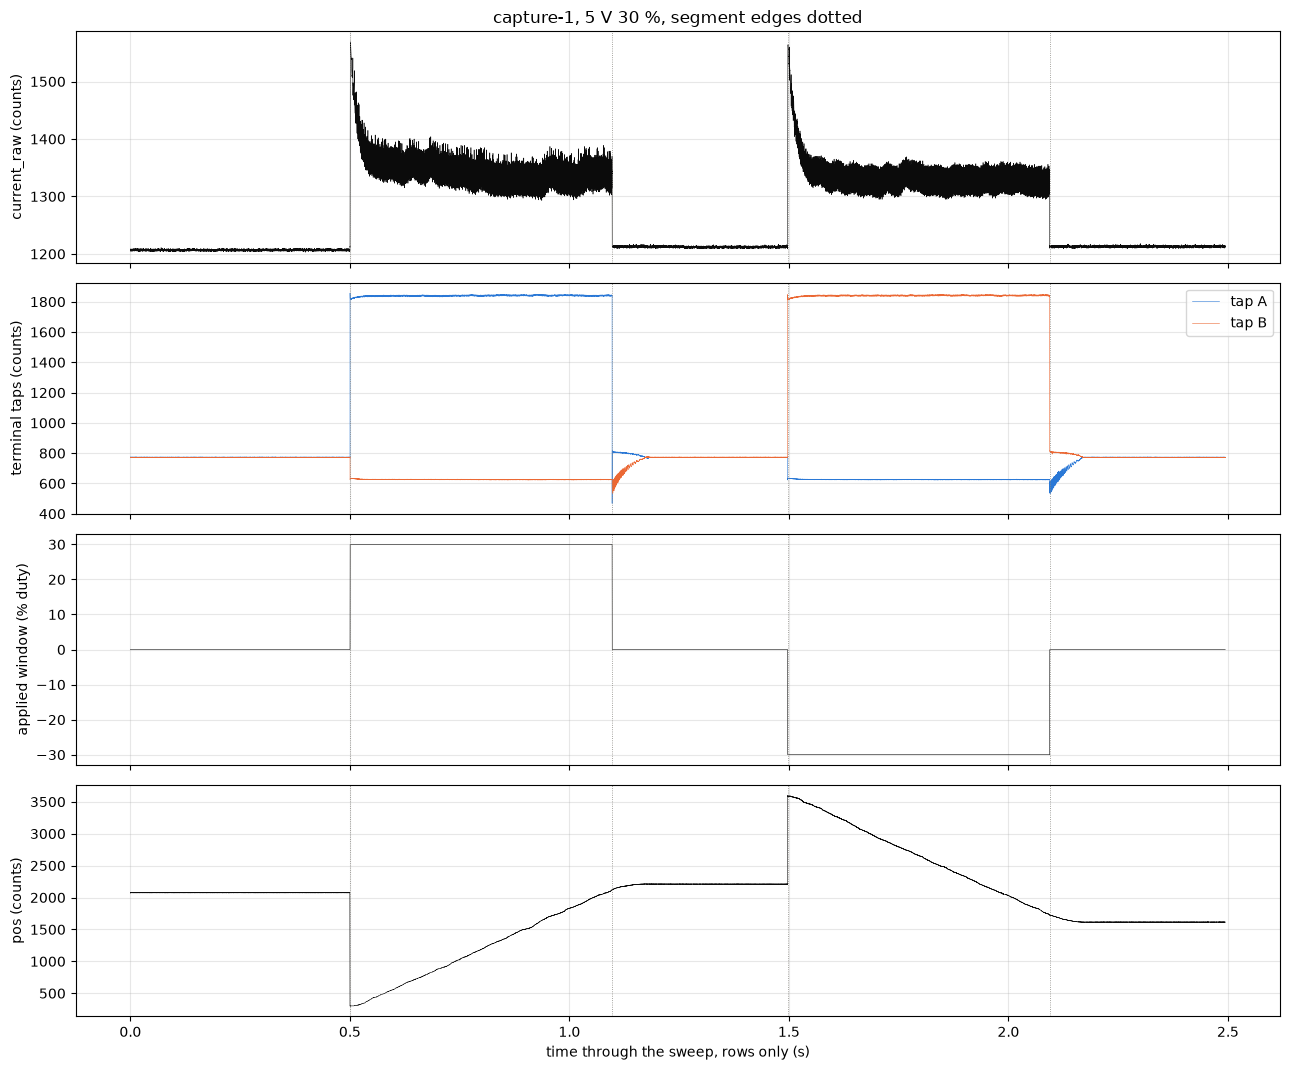

In [15]:
def overview(df, board, title):
    # a cycle's raw channels against its rows, segment edges dotted
    duty_pct = df["duty_counts"] / board.pwm_arr * 100
    channels = [
        ("current_raw (counts)", [(df["current_raw"], INK)]),
        ("terminal taps (counts)", [(df["vmotor_a"], BLUE, "tap A"),
                                    (df["vmotor_b"], ORANGE, "tap B")]),
        ("applied window (% duty)", [(duty_pct, INK)]),
        ("pos (counts)", [(df["pos"], INK)]),
    ]
    fig, ax = figures.sweep_overview(df, FS, channels, title=title)
    figures.finish(fig)


overview(SPIN_EX[0], SPIN_EX[2], "capture-1, 5 V 30 %, segment edges dotted")

The baseline, the spin and coast in direction +1, then in direction -1. Each spin opens on a current peak that falls as the rotor gathers speed, and the pot climbs or falls across the travel. In each coast the current drops to the open bridge's zero and the driven tap falls with the rotor. The rows between segments, the seek back to the guard, are not recorded, so the streams sit end to end.

The low cycle at 5 V 8 %. The thing to see is the kick lifting the rotor to speed and the hold carrying it at a slow, steady pace.

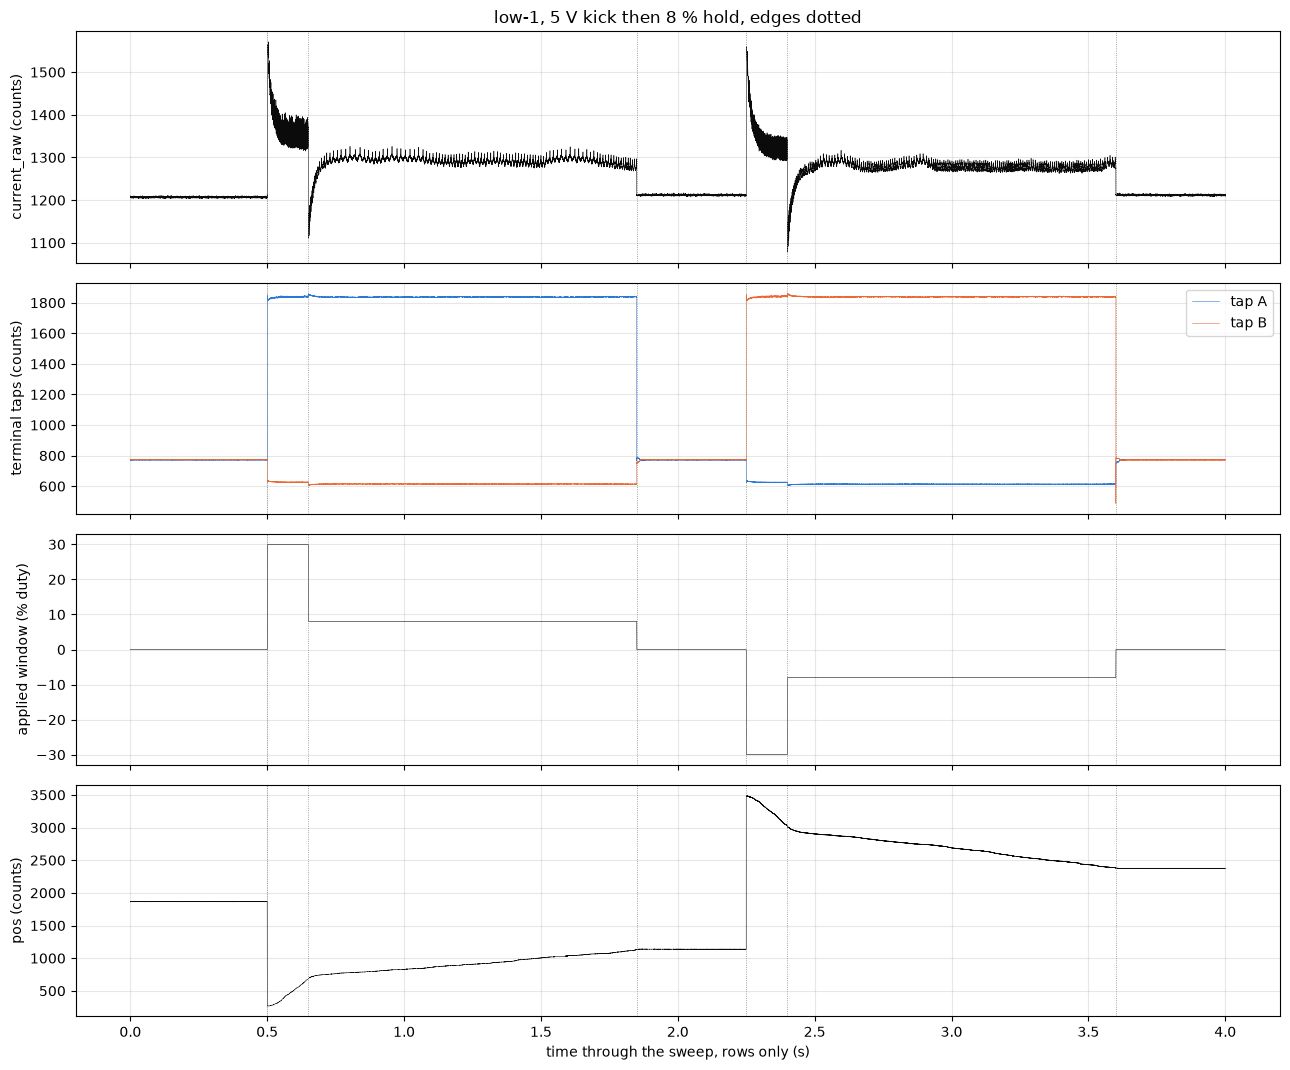

In [16]:
overview(LOW_EX[0], LOW_EX[2], "low-1, 5 V kick then 8 % hold, edges dotted")

The kick at 30 % draws a short peak and spins the rotor up. The hold at 8 % draws a small current with the slow ripple of a turning motor on it, and the pot moves at a steady slope. The coast then shows the EMF of a rotor that was still turning when the bridge opened.

## Method

### The chain

Every number goes through the chain the earlier stages built. The board is identified from each sweep's sense block and checked. The current is the crest sample over the sweep's own torque-off zero with current-scale's in-drive offset taken out, $I_\mathrm{crest}$ ("I crest"). The terminal volts at the crest, $V_\mathrm{on}$ ("V on"), are the tap difference through terminal-chain, signed by the direction so drive reads positive. The rail is the probe before the sweep through terminal-chain's rest line. The duty fraction $D$ is the applied window in ticks over the 1200 tick half period.

### Three constructions of the applied volts

The volts the motor sees, averaged over the PWM period, are not read directly. They are formed from $V_\mathrm{on}$ and the duty, three ways, on every spin.

- A, as bemf-coast and no-load-current formed them, $V_A = D\,V_\mathrm{on}$.
- B, with stage 1's two board terms. The taps' ON and OFF edges lag the commanded window by $\ell_\mathrm{on}$ and $\ell_\mathrm{off}$ ("ell on", "ell off") ticks, so the motor sees an on-share $s = (2h - \ell_\mathrm{on} + \ell_\mathrm{off}) / P$, with $h$ the half-window in ticks and $P$ the 2400 tick period. Between the on-windows the bridge brakes through the low-side loop $R_\mathrm{brk}$ ("R brake"), which drops $(1 - s)\,R_\mathrm{brk}\,I$. So $V_B = s\,V_\mathrm{on} - (1 - s)\,R_\mathrm{brk}\,I_\mathrm{crest}$.
- C, B with the type's spinning crest term taken off the current, $I_C = I_\mathrm{crest} - G_\mathrm{spin}\,(1 - D)\,V_\mathrm{on}$, $G_\mathrm{spin}$ ("G spin") being mg90-b's 3.35 mS. This one is a comparison.

The crest term is a reading term. The crest sample reads above the period's mean current by an amount that grows with the window volts, and stage 2 measured it on the bare type motor. Beside construction A's current, a fourth current is carried, the crest over the coast tail's awake zero instead of stage 1's in-drive offset. The awake zero is the current channel's reading with the bridge enabled, its outputs open and the rotor at rest, which every coast gives in its last 100 ms.

In [17]:
def edge_lags(rail):
    # (ON, OFF) lags in ticks on the line between sample-timing's rails,
    # and the lowest and highest ON - OFF difference their bounds allow
    f = (rail - LAG_RAILS[0]) / (LAG_RAILS[1] - LAG_RAILS[0])

    def at(pair):
        return pair[0] + f * (pair[1] - pair[0])

    on, off = at(LAG_ON), at(LAG_OFF)
    lo = at(LAG_ON_LO) - at(LAG_OFF_HI)
    hi = at(LAG_ON_HI) - at(LAG_OFF_LO)
    return on, off, lo, hi


def share_of(half_ticks, rail, period):
    # the on-share under construction B, and at the lags' two bounds
    on, off, lo, hi = edge_lags(rail)
    h = np.asarray(half_ticks, float)
    return ((2 * h - on + off) / period, (2 * h - hi) / period,
            (2 * h - lo) / period)

In [18]:
def constructions(D, share, v_on, i_a, share_lo, share_hi):
    # the applied volts under A, B and C, the current under C; D the duty
    # fraction, share B's on-share, v_on the crest volts, i_a the crest
    # current with the in-drive offset out
    out = {"v_a": D * v_on,
           "v_b": share * v_on - (1 - share) * R_BRK * i_a}
    i_c = i_a - G_SPIN_TYPE_S * (1 - D) * v_on   # the type's term out
    out["i_c"] = i_c
    out["v_c"] = share * v_on - (1 - share) * R_BRK * i_c
    # construction B at the edge lags' two bounds
    out["v_b_lo"] = share_lo * v_on - (1 - share_lo) * R_BRK * i_a
    out["v_b_hi"] = share_hi * v_on - (1 - share_hi) * R_BRK * i_a
    return out


for rail in (3.7, 5.0, 7.4):
    s, s_lo, s_hi = share_of(360.0, rail, 2400)   # a 30 % window
    print(f"{rail} V at 30 %: on-share {s:.4f} ({s_lo:.4f} to {s_hi:.4f})")

3.7 V at 30 %: on-share 0.2900 (0.2808 to 0.3017)
5.0 V at 30 %: on-share 0.2896 (0.2800 to 0.3008)
7.4 V at 30 %: on-share 0.2888 (0.2783 to 0.2992)


### The spin window and the settle

A spin is read over the last 100 ms of its held duty, half the held rows at most and 20 ms at least, since the runway cut the top rungs to 53 to 157 ms. The window of the same length before it gives the settle, the window's speed over the previous window's less one. A spin whose speed still rises across its window is a run-up, not a steady state, and is said so wherever its numbers appear.

In [19]:
def spin_window(sp, board):
    # the held duty's last window and the window before it
    ticks = sp["duty_counts"].abs()
    half = float(ticks.iloc[len(sp) // 2:].median())   # the held window
    held = sp[ticks == half]            # the start's other rows left out
    n_held = len(held)
    n = int(min(SPIN_WINDOW_MS * FS / 1e3, n_held // 2))   # half at most
    n = max(n, int(SPIN_WINDOW_MIN_MS * FS / 1e3))         # 20 ms at least
    n = min(n, n_held)
    win = held.iloc[-n:]                # the last window of the held duty
    prev = held.iloc[-2 * n:-n] if n_held >= 2 * n else None
    row = {"half_ticks": half, "duty_pct": 100 * half / board.pwm_arr,
           "held_rows": n_held, "spin_ms": len(sp) / FS * 1e3,
           "held_ms": n_held / FS * 1e3, "window_ms": n / FS * 1e3,
           "window_valid_share": float(win["window_valid"].mean())}
    return win, prev, row

### The dropout rows

A dropout row is a row where the brush path opens for a moment and the crest current falls to near the zero. `tel.dropout_rows` marks a row whose current over the zero is under a quarter of the window's, bemf-coast's quarter rule, and the rate is the rows marked per second of window.

The window's currents, volts, constructions and dropouts.

In [20]:
def spin_volts_amps(win, d, zero_i, half, board, rail, awake):
    # crest current, crest volts, the constructions and the dropouts
    raw = win["current_raw"].to_numpy(float)
    i_over = raw - zero_i               # counts over the torque-off zero
    i_a = (i_over - I_DRIVE_OFFSET) * A_PER_COUNT    # construction A's
    i_awake = (i_over - awake) * A_PER_COUNT         # over the awake zero
    taps = ((win["vmotor_a"] - win["vmotor_b"]) * d).to_numpy(float)
    v_on = SCALES.volts(taps, TAP_OFFSET)   # crest volts, drive positive
    row = {"i_crest_a": float(i_a.mean()),
           "i_crest_sd_ma": float(i_a.std() * 1e3),
           "i_crest_awake_a": float(i_awake.mean()),
           "v_on_v": float(v_on.mean())}
    trough = win.get("current_trough")  # no OFF window at 100 %
    if trough is not None and trough.notna().any():
        row["trough_over_zero_counts"] = float(
            win["current_trough"].mean() - zero_i)
    D = half / board.pwm_arr            # the duty fraction
    share, s_lo, s_hi = share_of(half, rail, 2 * board.pwm_arr)
    c = constructions(D, share, row["v_on_v"], row["i_crest_a"], s_lo,
                      s_hi)
    row.update(share=share, v_a_v=c["v_a"], v_b_v=c["v_b"],
               v_c_v=c["v_c"], i_c_a=c["i_c"], v_b_lo_v=c["v_b_lo"],
               v_b_hi_v=c["v_b_hi"])
    drop = tel.dropout_rows(i_over)     # the quarter rule
    row["dropout_rows"] = int(drop.sum())
    row["dropouts_per_s"] = float(drop.sum() / (len(win) / FS))
    return row

### The ripple tach and the pot

A brushed motor with $N_r$ ("N r") commutation events per revolution, 3 slots times 2 brushes here, puts a ripple at $N_r$ times its revolutions per second on its current. The ripple tach counts the whole cycles of that ripple in the window's current, band-passed around a seed, and gives the speed with no constant from any model. The seed is the coast's early line, bemf-coast's spin route. The same count over the previous window gives the settle, and over the last 20 ms before the cut the tach's speed nearest the cut. The pot's line over the window, through the nominal pot slope and the train, is the outside check. The pot reads through the gears, so it is never a reference for the back-EMF.

In [21]:
def spin_speed(win, prev, d, zero_i, f_seed):
    # the ripple tach over the window, the window before, and the last
    # 20 ms before the cut, seeded by the coast; the pot beside them
    row = {}
    raw = win["current_raw"].to_numpy(float)
    if np.isfinite(f_seed):
        f_cnt, ncyc = ripple.count_cycles(raw - raw.mean(), f_seed)
        row["spin_rev_s"], row["spin_cycles"] = f_cnt / N_R, ncyc
        if prev is not None:
            xp = prev["current_raw"].to_numpy(float)
            fp, _ = ripple.count_cycles(xp - xp.mean(), f_seed)
            row["spin_prev_rev_s"] = fp / N_R
            ip = (xp - zero_i - I_DRIVE_OFFSET) * A_PER_COUNT
            row["i_prev_a"] = float(ip.mean())
        x20 = raw[-int(0.02 * FS):]     # the tach nearest the cut
        f20, _ = ripple.count_cycles(x20 - x20.mean(), f_seed)
        row["spin_rev_s_last20"] = f20 / N_R
    speed, _, _ = pot_speed(win["pos"].to_numpy(float))
    row["pot_rev_s"] = speed * d        # signed so drive reads positive
    return row

### The coast and its gate

The coast is bemf-coast's reduction, unchanged. The cut is the first row with the bridge open. The EMF is the tap difference from the cut, signed by the direction, less the sweep's torque-off tap difference, the rest zero, through terminal-chain. The coast turned if the EMF 0.1 to 1 ms past the cut is over 0.05 V. Rows where the brush path opens are bridged with a line. The ripple is seeded by the strongest line of the first 10 ms, and `ripple.read_window` takes the whole ripple cycles nearest 10 ms from 1 ms past the cut. Over those rows

$$K_e = \frac{\overline{e}}{\omega} = \frac{\overline{e} \, N_r}{2\pi \, f_r},$$

with $\overline{e}$ ("e bar") the window's mean EMF and $f_r$ ("f r") its counted ripple frequency, both over the same rows, so the rotor's deceleration inside the window cancels. $E_0$ ("E naught"), the EMF at the cut, is a line through the one-ripple boxcar of the window's EMF, projected back to the cut.

Two other zeros are read beside the rest zero, bemf-coast's bracket on it. With no zero the EMF is the raw tap difference. With the tail zero it is the tap difference less the median over the coast's last 100 ms, the open bridge with the rotor at rest.

New here is a gate. On a geared rotor the coast is short, and at the lowest rungs the rotor loses a third or more of its speed inside the 10 ms window. The band-pass is 35 % either side of the seed, so the ripple's line sweeps out of it and the count fails or lands anywhere. The gate is the window's own numbers. The speed lost across the window, $-\dot{E}\,T_w / \overline{e}$ with $\dot{E}$ ("E dot") the line's slope at the cut and $T_w$ ("T w") the window's length, is at most 0.35, and the window holds at least 4 whole cycles. No $K_e$ number is used before the gate.

In [22]:
def e0_line(emf, start, f_seed, target_ms=10, order=1):
    # bemf-coast's E0: a line through the one-ripple boxcar of the
    # bridged EMF over the whole-cycle window nearest target_ms from
    # `start`, projected to the cut
    f, i0, i1, n = ripple.read_window(emf, start, f_seed,
                                      target_ms=target_ms)
    if not np.isfinite(f) or n == 0:    # no window: the read failed
        return dict(e_cut=np.nan, dedt=np.nan, e_win=np.nan, i0=start,
                    i1=start, f=np.nan, n=0)
    nbox = max(int(round(FS / f)), 1)   # rows in one ripple cycle
    smooth = np.convolve(emf, np.ones(nbox) / nbox, mode="same")
    t = np.arange(len(emf)) / FS        # s from the cut
    p = np.polyfit(t[i0:i1], smooth[i0:i1], order)
    return dict(e_cut=float(np.polyval(p, 0.0)),
                dedt=float(np.polyval(np.polyder(p), 0.0)),
                e_win=float(emf[i0:i1].mean()), i0=i0, i1=i1, f=f, n=n)


def coast_emf(co, d, zero_e):
    # the coast's EMF from the cut, its tail zero, whether it turned
    cut = coast.cut_row(co)
    row = {"cut_row": cut}
    if cut is None:
        return row, None
    emf_read = coast.emf_from_cut(co, d, cut, zero_e,
                                  v_per_count=V_PER_COUNT)
    row["e_first_v"] = float(coast.early_emf(emf_read))  # 0.1 to 1 ms
    row["turned"] = bool(row["e_first_v"] >= coast.TURN_V)
    taps = ((co["vmotor_a"] - co["vmotor_b"]) * d).to_numpy(float)
    # the open bridge's tap zero, read in the tail with the rotor at rest
    row["tail_tap_zero_counts"] = float(np.median(taps[-TAIL_ROWS:])
                                        - zero_e)
    return row, emf_read

In [23]:
def coast_ke(emf_read, zero_e, tail_zero):
    # bemf-coast's window on a turned coast: Ke under three zeros, E0
    bad = coast.open_rows(emf_read)     # rows the brush path opened
    emf = coast.bridge(emf_read, bad)   # bridged with a line
    stop = coast.stop_row(emf)
    f0 = coast.seed_freq(emf)           # the first 10 ms's line
    m = e0_line(emf, coast.COAST_FROM_ROWS, f0)
    row = {"open_rows": int(bad.sum()), "f_seed": f0,
           "stop_ms": np.nan if stop is None else stop / FS * 1e3,
           "e_cut_v": m["e_cut"], "dedt_v_s": m["dedt"],
           "e_win_v": m["e_win"], "coast_cycles": m["n"],
           "win_i0": m["i0"], "win_i1": m["i1"]}
    if not np.isfinite(m["f"]):
        return row, emf
    w = 2 * np.pi * m["f"] / N_R        # rad/s over the window
    row["coast_rev_s"] = m["f"] / N_R
    row["ke_v_s_per_rad"] = m["e_win"] / w
    row["ke_mv_per_rev_s"] = row["ke_v_s_per_rad"] * 2 * np.pi * 1e3
    row["ke_unbridged_mv_per_rev_s"] = (
        emf_read[m["i0"]:m["i1"]].mean() / w * 2 * np.pi * 1e3)
    # bemf-coast's bracket on the zero: none, and the coast's own tail
    row["ke_nozero_mv_per_rev_s"] = (
        (m["e_win"] + zero_e * V_PER_COUNT) / w * 2 * np.pi * 1e3)
    row["ke_tailzero_mv_per_rev_s"] = (
        (m["e_win"] - tail_zero * V_PER_COUNT) / w * 2 * np.pi * 1e3)
    row["e0_over_ewin"] = m["e_cut"] / m["e_win"]
    row["rev_s_cut_from_window"] = row["coast_rev_s"] * row["e0_over_ewin"]
    return row, emf

$K_e$ is also read in 5 ms windows of whole cycles walked end to end down each turned coast, each seeded by the last, until the speed falls under 30 rev/s or the rotor stops, no-load-current's walk.

In [24]:
def ke_walk(emf, f_seed, stop, tag, ms=5, floor_rev_s=30.0):
    # Ke in windows of whole cycles end to end down the coast
    found = ripple.walk(emf, coast.COAST_FROM_ROWS, f_seed, ms, floor_rev_s,
                        stop if stop is not None else len(emf),
                        per_rev=N_R, snap=True)
    rows = []
    for i0, i1, f, n in found:
        i0, i1 = int(i0), int(i1)
        if i1 <= i0:
            continue
        w = 2 * np.pi * f / N_R         # rad/s over the window
        e = float(emf[i0:i1].mean())
        rows.append({**tag, "t_ms": (i0 + i1) / 2 / FS * 1e3,
                     "rev_s": f / N_R, "emf_v": e,
                     "ke_mv_per_rev_s": e / w * 2 * np.pi * 1e3,
                     "cycles": n})
    return rows

### Reading every cycle

One cycle through all of the above, one row per direction. The awake zero step is the coast tail's mean current over the sweep's torque-off zero, in counts.

In [25]:
def reduce_sweep(info):
    # every spin and coast pair of one cycle, one row per direction
    df, meta, board = load(LADDER / info["set"] / info["folder"])
    zero_i, zero_e = tel.rest_zeros(df)     # the torque-off zeros
    rail = float(SCALES.rail_v(info["vbus_raw"]))   # the probe before
    base = {"set": info["set"], "k": int(info["k"]),
            "volts_set": float(info["volts_set"]), "rail_v": rail,
            "zero_i": float(zero_i), "zero_e": float(zero_e),
            "ntc_c": float(board.ntc_c_beta(float(info["ntc_raw"]))),
            "t_start": float(info["t_start"])}
    rows, walks = [], []
    for d, sp, co in coast.pairs(df):
        crow, emf_read = coast_emf(co, d, zero_e)
        cur = co["current_raw"].to_numpy(float)
        awake = float(np.mean(cur[-TAIL_ROWS:]) - zero_i)   # awake step
        emf = None
        if crow.get("turned"):
            krow, emf = coast_ke(emf_read, zero_e,
                                 crow["tail_tap_zero_counts"])
            crow.update(krow)
        f_seed = crow.get("f_seed", np.nan)
        win, prev, srow = spin_window(sp, board)
        srow.update(spin_volts_amps(win, d, zero_i, srow["half_ticks"],
                                    board, rail, awake))
        srow.update(spin_speed(win, prev, d, zero_i, f_seed))
        rows.append({**base, "dir": d, "awake_step_counts": awake,
                     **srow, **crow})
        if emf is not None and np.isfinite(f_seed):
            stop_ms = crow["stop_ms"]
            stop = None if not np.isfinite(stop_ms) else int(
                stop_ms * FS / 1e3)
            tag = {k: base[k] for k in ("set", "k", "volts_set")}
            walks += ke_walk(emf, f_seed, stop, {
                **tag, "dir": d, "duty_pct": srow["duty_pct"]})
    return rows, walks

In [26]:
spin_rows, walk_rows = [], []
for name in SETS:
    for _, info in TABLES[name].iterrows():
        rows, walks = reduce_sweep(info.to_dict())
        spin_rows += rows
        walk_rows += walks
SPINS = pd.DataFrame(spin_rows).sort_values(
    ["set", "k", "dir"], ascending=[True, True, False]).reset_index(
        drop=True)
WALK = pd.DataFrame(walk_rows)
n_cycles = SPINS.groupby("set")["k"].nunique().sum()
print(f"{len(SPINS)} spins and coasts from {n_cycles} cycles, "
      f"{int(SPINS['turned'].sum())} turned, {len(WALK)} walk windows")

132 spins and coasts from 66 cycles, 132 turned, 957 walk windows


The gate's two numbers, the settle, and the acceleration share. The acceleration share is the drive tach's slope across the two windows over the coast's deceleration at the cut, both in rad/s per second. From it comes a settled-equivalent current, $I / (1 + a_d / a_c)$, with $a_d$ ("a d") the drive's acceleration and $a_c$ ("a c") the coast's deceleration. Under drive $K_t\,(I - I_\mathrm{drag}) = J\,a_d$, and in the coast $K_t\,I_\mathrm{drag} = J\,a_c$ at the same speed, with $K_t$ ("K t") the torque constant, $I_\mathrm{drag}$ ("I drag") the current the drag alone draws and $J$ the inertia, so $J$ never enters. It assumes the drag at a speed is the same under drive and coast, so it is a candidate, and it is carried for the friction read only. The voltage balance holds with the actual current.

In [27]:
SPINS["win_ms"] = (SPINS["win_i1"] - SPINS["win_i0"]) / FS * 1e3
# the share of the window's speed lost across it, from the line's slope
SPINS["decel_frac_win"] = (-SPINS["dedt_v_s"] * SPINS["win_ms"] / 1e3
                           / SPINS["e_win_v"])
SPINS["ke_gate"] = ((SPINS["decel_frac_win"] <= DECEL_FRAC_MAX)
                    & (SPINS["coast_cycles"] >= MIN_CYCLES))
# the spin route: E0 over the tach's last 20 ms, mV per rev/s
SPINS["ke_spin_route"] = SPINS["e_cut_v"] / SPINS["spin_rev_s_last20"] * 1e3
SPINS["settle_speed_pct"] = (SPINS["spin_rev_s"] / SPINS["spin_prev_rev_s"]
                             - 1) * 100
SPINS["alpha_drive"] = ((SPINS["spin_rev_s"] - SPINS["spin_prev_rev_s"])
                        * 2 * np.pi / (SPINS["window_ms"] / 1e3))
SPINS["alpha_coast"] = -SPINS["dedt_v_s"] / (
    SPINS["ke_mv_per_rev_s"] * 1e-3 / (2 * np.pi))
SPINS["accel_share"] = SPINS["alpha_drive"] / SPINS["alpha_coast"]
SPINS["i_settled_a"] = SPINS["i_crest_a"] / (1 + SPINS["accel_share"])
GATED = SPINS[SPINS["ke_gate"]]         # the coasts that pass the gate
failed = SPINS[~SPINS["ke_gate"]]
print(f"{len(GATED)} of {len(SPINS)} coasts pass the gate; the "
      f"{len(failed)} that fail, by rung:")
print(failed.groupby(["set", "volts_set", "duty_pct"]).agg(
    coasts=("k", "size"), rev_s=("coast_rev_s", "mean"),
    lost=("decel_frac_win", "mean"), cycles=("coast_cycles", "mean"))
    .round(2).to_string())
print(f"gated coasts: window speeds {GATED['coast_rev_s'].min():.0f} to "
      f"{GATED['coast_rev_s'].max():.0f} rev/s, stop "
      f"{GATED['stop_ms'].min():.0f} to {GATED['stop_ms'].max():.0f} ms")

108 of 132 coasts pass the gate; the 24 that fail, by rung:
                               coasts   rev_s  lost  cycles
set        volts_set duty_pct                              
capture-1  3.7       15.0           6   10.73  1.05     2.5
                     20.0           6   25.06  0.07     2.5
           5.0       15.0           6   27.10  1.74     3.0
                     20.0           5   59.33  0.32     3.4
ref-open-1 5.0       30.0           1  109.44  0.36     7.0
gated coasts: window speeds 60 to 476 rev/s, stop 42 to 193 ms


One gated coast and one that fails, the bridged EMF from the cut with its one-ripple boxcar, the window shaded and the band-passed crossings marked. The thing to see is how much of its speed the 3.7 V 15 % rotor has lost by the window's end.

In [28]:
def coast_trace(name, volts, duty, direction=1):
    # one coast's bridged EMF, its window and the crossings inside it
    df, _, _ = load(pick(name, volts, duty))
    zero_i, zero_e = tel.rest_zeros(df)
    co = [c for d, _, c in coast.pairs(df) if d == direction][0]
    crow, emf_read = coast_emf(co, direction, zero_e)
    krow, emf = coast_ke(emf_read, zero_e, crow["tail_tap_zero_counts"])
    i0, i1 = krow["win_i0"], krow["win_i1"]
    f = krow["coast_rev_s"] * N_R if "coast_rev_s" in krow else np.nan
    tc = []
    if np.isfinite(f):                  # the crossings over the window
        span = emf[coast.COAST_FROM_ROWS:i1 + int(FS / f)]
        tc = ripple.crossings(span, f) + coast.COAST_FROM_ROWS
        tc = tc[(tc >= i0) & (tc <= i1)]
    return emf, i0, i1, f, np.asarray(tc), krow

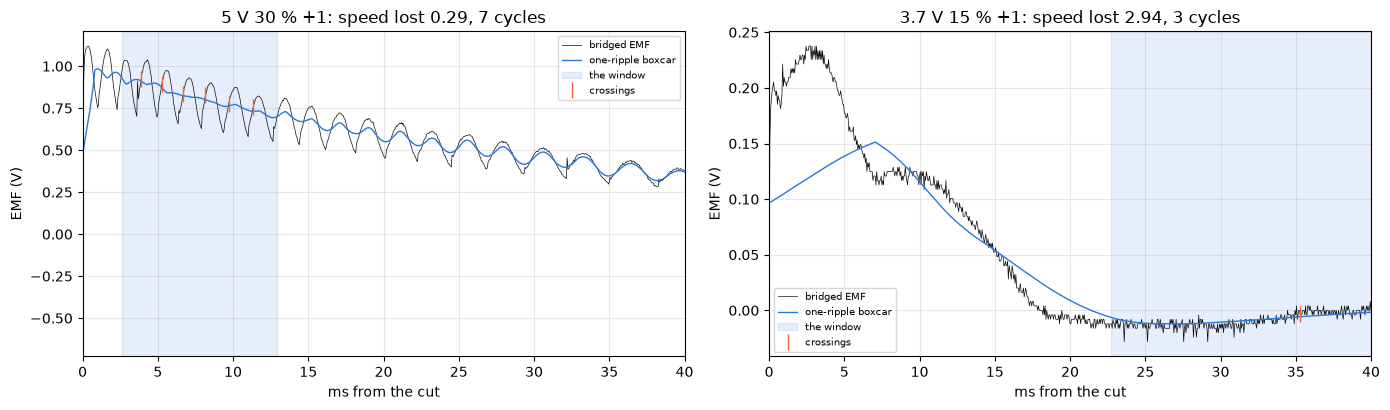

In [29]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
for a, (volts, duty) in zip(ax, ((5.0, 30), (3.7, 15))):
    emf, i0, i1, f, tc, krow = coast_trace("capture-1", volts, duty)
    ms = np.arange(len(emf)) / FS * 1e3
    a.plot(ms, emf, lw=0.5, color=INK, label="bridged EMF")
    if np.isfinite(f):
        box = np.convolve(emf, np.ones(int(round(FS / f))) / round(FS / f),
                          mode="same")
        a.plot(ms, box, lw=1.0, color=BLUE, label="one-ripple boxcar")
        a.axvspan(i0 / FS * 1e3, i1 / FS * 1e3, color=BLUE, alpha=0.12,
                  label="the window")
        a.plot(tc / FS * 1e3, np.interp(tc, np.arange(len(emf)), emf),
               "|", color=ORANGE, ms=12, label="crossings")
    lost = -krow["dedt_v_s"] * (i1 - i0) / FS / krow["e_win_v"]
    a.set_xlim(0, 40)
    a.legend(fontsize=7)
    figures.label(a, x="ms from the cut", y="EMF (V)",
                  title=f"{volts:g} V {duty} % +1: speed lost {lost:.2f}, "
                        f"{krow['coast_cycles']} cycles")
figures.finish(fig)

At 5 V 30 % the EMF falls by 0.29 of its speed across a window of seven whole cycles, and the crossings sit evenly on the ripple. At 3.7 V 15 % the EMF falls to zero within about 20 ms of the cut, and the window lands past the stop on the open bridge's noise, so its three cycles are not the motor's ripple and its speed lost reads 2.94. The gate keeps the first and drops the second.

### Reading a hold

Each low cycle holds a kick, a hold and a coast per direction. The kick's breakaway is the first row where the pot has left the kick's first driven row by more than 3 counts, timed from the drive's first row, with the peak of a 5-row boxcar of the current before it. The direction -1 stream opens with the shaft still moving from the seek, so the breakaway is read in direction +1 only and the counts the shaft moved before the drive are kept. The hold is read over its last 400 ms. Three detectors say whether it kept turning.

1. The pot's slope through the nominal pot slope and the train. 1 rev/s at the motor is about 9 counts over 400 ms against about 2 counts of noise.
2. The coast's EMF 0.1 to 1 ms past the cut, over the sag's $K_e$, one conversion of this motor's EMF to speed.
3. The ripple tach on the hold's current, seeded at $N_r$ times the pot's speed where that seed is over 7.5 Hz, the pot over 1.25 rev/s.

A hold kept turning when both the pot and the EMF read over 1 rev/s. The effective volts of a hold are the rail from the probe times the duty, the plan's and pot-table's definition. At six of the seventeen levels the window is under the board's sampling floors, so neither the crest current nor the tap volts are numbers there, and the tap-formed $D\,V_\mathrm{on}$ is kept only as a check where the window is valid. The hold is also read in 100 ms bins of the pot's speed.

In [30]:
KE_REV = KE_SAG * 1e-3                  # V per rev/s, the sag's Ke


def kick_read(kick, zero_i, board, d):
    # the kick: rows before the drive, the breakaway, its volts and speed
    pre = tel.drive_start(kick)         # rows before the drive starts
    kd = tel.drive_rows(kick)           # from the first driven row
    pos = kd["pos"].to_numpy(float)
    ik = ((kd["current_raw"].to_numpy(float) - zero_i - I_DRIVE_OFFSET)
          * A_PER_COUNT)
    moved = np.flatnonzero(np.abs(pos - pos[0]) > POT_MOVE_COUNTS)
    row = {"pre_drive_rows": int(pre), "entry_counts": float(
        kick["pos"].iloc[pre] - kick["pos"].iloc[0]) if pre > 0 else 0.0}
    if len(moved):
        m = int(moved[0])               # the first row past the seat
        box = (np.convolve(ik[:m + 1], np.ones(5) / 5, mode="same")
               if m >= 5 else ik[:m + 1])
        row["break_ms"], row["i_break_peak_a"] = m / FS * 1e3, float(
            box.max())
    else:
        row["break_ms"], row["i_break_peak_a"] = np.nan, float(ik.max())
    half = float(kd["duty_counts"].abs().median())
    taps = ((kd["vmotor_a"] - kd["vmotor_b"]) * d).to_numpy(float)
    row["kick_v_eff_v"] = float((half / board.pwm_arr) * SCALES.volts(
        taps[-1000:], TAP_OFFSET).mean())
    row["kick_end_pot_rev_s"] = pot_speed(pos[-1000:])[0] * d
    return row

In [31]:
def hold_read(hold, zero_i, board, rail, d, awake):
    # the hold's last 400 ms: effective volts, current, pot and ripple
    ticks = hold["duty_counts"].abs()
    half = float(ticks.iloc[-1])
    held = hold[ticks == half]          # the rows at the held duty
    D = half / board.pwm_arr
    tail = held.iloc[-HOLD_TAIL_ROWS:]
    taps = ((tail["vmotor_a"] - tail["vmotor_b"]) * d).to_numpy(float)
    v_on = SCALES.volts(taps, TAP_OFFSET)
    raw = tail["current_raw"].to_numpy(float)
    i_over = raw - zero_i
    speed = pot_speed(tail["pos"].to_numpy(float))[0]
    row = {"duty_pct": 100 * D, "hold_rows": len(held),
           "window_valid_share": float(held["window_valid"].mean()),
           "v_eff_cmd_v": D * rail,    # rail x duty, pot-table's axis
           "v_eff_tap_v": float(D * v_on.mean()),
           "i_hold_a": float(((i_over - I_DRIVE_OFFSET)
                              * A_PER_COUNT).mean()),
           "i_hold_awake_a": float(((i_over - awake)
                                    * A_PER_COUNT).mean()),
           "pot_rev_s": speed * d}
    seed = abs(speed) * N_R             # Hz, the ripple's seed
    x = raw - raw.mean()
    try:
        f_cnt, n = (ripple.count_cycles(x, seed) if seed > SEED_MIN_HZ
                    else (np.nan, 0))
    except Exception:
        f_cnt, n = np.nan, 0            # no count in this window
    row.update(ripple_rev_s=f_cnt / N_R, ripple_cycles=n)
    return row, held

In [32]:
def reduce_low(info):
    # one low cycle: kick, hold, coast and bins, one row per direction
    df, meta, board = load(LADDER / LOW / info["folder"])
    zero_i, zero_e = tel.rest_zeros(df)
    rail = float(SCALES.rail_v(info["vbus_raw"]))
    segs = {int(s): g for s, g in df.groupby("seg")}
    base = {"k": int(info["k"]), "volts_set": float(info["volts_set"]),
            "rail_v": rail, "t_start": float(info["t_start"])}
    rows, bins = [], []
    for first in (1, 4):                # kick, hold, coast, each way
        kick, hold, co = segs[first], segs[first + 1], segs[first + 2]
        d = int(kick["dir"].iloc[0])
        cur = co["current_raw"].to_numpy(float)
        awake = float(np.mean(cur[-TAIL_ROWS:]) - zero_i)
        hrow, held = hold_read(hold, zero_i, board, rail, d, awake)
        row = {**base, "dir": d, **kick_read(kick, zero_i, board, d),
               **hrow}
        cut = coast.cut_row(co)         # the EMF just past the cut
        emf_read = coast.emf_from_cut(co, d, cut, zero_e,
                                      v_per_count=V_PER_COUNT)
        row["e_first_rev_s"] = float(coast.early_emf(emf_read)) / KE_REV
        for j in range(0, len(held) - BIN_ROWS + 1, BIN_ROWS):
            chunk = held["pos"].to_numpy(float)[j:j + BIN_ROWS]
            bins.append({**base, "dir": d, "duty_pct": row["duty_pct"],
                         "v_eff_cmd_v": row["v_eff_cmd_v"],
                         "t_ms": (j + BIN_ROWS / 2) / FS * 1e3,
                         "rev_s": pot_speed(chunk)[0] * d})
        row["turning_pot"] = bool(abs(row["pot_rev_s"]) >= TURN_REV_S)
        row["turning_emf"] = bool(row["e_first_rev_s"] >= TURN_REV_S)
        row["kept_turning"] = row["turning_pot"] and row["turning_emf"]
        rows.append(row)
    return rows, bins

In [33]:
hold_rows, bin_rows = [], []
for _, info in TABLES[LOW].iterrows():
    rows, bins = reduce_low(info.to_dict())
    hold_rows += rows
    bin_rows += bins
# the order the logistic's bootstrap draws from: rail, duty down, +1 first
HOLDS = pd.DataFrame(hold_rows).sort_values(
    ["volts_set", "duty_pct", "dir", "k"],
    ascending=[True, False, False, True]).reset_index(drop=True)
HOLD_BINS = pd.DataFrame(bin_rows)
n_levels = HOLDS.groupby(["volts_set", "duty_pct"]).ngroups
print(f"{len(HOLDS)} holds at {n_levels} levels, "
      f"{int(HOLDS['kept_turning'].sum())} kept turning")

102 holds at 17 levels, 54 kept turning


### Error bars

A rung's number is the mean over its three cycles with their sd. A pooled number carries its sd and its standard error, the sd over the root of the count. A fitted coefficient carries the fit's standard error from its residuals. A difference between two blocks of three carries the two sds in quadrature over $\sqrt{3}$. The confidence words follow the series' rule. Candidate is one route or under 2 sigma, likely is two routes or 2 to 3 sigma, high is 3 sigma or more with an independent route. Nothing under 2 sigma is a finding.

## Ke from the coasts

Per rung and direction, the mean over three coasts under the rest zero with the no-zero and tail-zero reads beside it, the spin route ($E_0$ over the tach's last 20 ms), the window's cycles and length, and the speed lost across it.

In [34]:
KE_RUNG = SPINS.groupby(["set", "volts_set", "duty_pct", "dir"]).agg(
    n=("k", "size"), rev_s=("coast_rev_s", "mean"),
    ke=("ke_mv_per_rev_s", "mean"), ke_sd=("ke_mv_per_rev_s", "std"),
    ke_nozero=("ke_nozero_mv_per_rev_s", "mean"),
    ke_tail=("ke_tailzero_mv_per_rev_s", "mean"),
    ke_spin=("ke_spin_route", "mean"), cycles=("coast_cycles", "mean"),
    win_ms=("win_ms", "mean"), lost=("decel_frac_win", "mean"),
    stop_ms=("stop_ms", "mean"), gate=("ke_gate", "all")).reset_index()
ladder_rungs = KE_RUNG[KE_RUNG["set"].isin(["capture-1", "rail-1"])]
show(ladder_rungs.drop(columns=["set", "n"]), n=None)

,volts_set,duty_pct,dir,rev_s,ke,ke_sd,ke_nozero,ke_tail,ke_spin,cycles,win_ms,lost,stop_ms,gate
0,3.700,15.000,-1,12.939,0.744,1.121,0.348,0.744,0.010,2.000,32.783,1.147,25.450,False
1,3.700,15.000,1,9.262,-0.196,0.139,-0.676,-0.196,NaN,3.000,59.533,0.978,16.633,False
2,3.700,20.000,-1,7.871,-0.110,0.003,-0.622,-0.110,NaN,2.000,42.300,-0.666,18.017,False
3,3.700,20.000,1,36.524,7.318,0.040,7.207,7.318,7.001,3.000,13.650,0.557,36.033,False
4,3.700,30.000,-1,78.725,7.352,0.006,7.301,7.352,7.232,5.000,10.533,0.269,53.767,True
5,3.700,30.000,1,77.727,7.352,0.009,7.300,7.352,7.559,4.667,9.917,0.269,50.200,True
6,3.700,40.000,-1,120.027,7.302,0.065,7.280,7.314,7.323,7.000,9.650,0.203,73.567,True
7,3.700,40.000,1,118.581,7.293,0.044,7.272,7.306,7.444,7.000,9.817,0.220,63.550,True
8,3.700,60.000,-1,200.515,7.318,0.026,7.311,7.331,7.249,12.000,9.917,0.142,103.667,True
9,3.700,60.000,1,201.022,7.333,0.026,7.327,7.347,7.311,12.000,9.917,0.141,95.850,True


The pooled $K_e$ over the gated coasts, against the sag's and the type's, by zero, by direction and by rail.

In [35]:
ke = GATED["ke_mv_per_rev_s"]
KE_POOLED = ke.mean()                   # mV per rev/s, this motor's Ke
KE = KE_POOLED * 1e-3                   # V per rev/s, used from here on
print(f"Ke over {len(GATED)} of {len(SPINS)} coasts: {KE_POOLED:.4f} mV "
      f"per rev/s, sd {ke.std():.4f} ({ke.std() / KE_POOLED * 100:.2f} %), "
      f"se {ke.std() / np.sqrt(len(ke)):.4f}; "
      f"{KE_POOLED / (2 * np.pi):.4f} mV s/rad")
print(f"against the sag's {KE_SAG:.3f}: {(KE_POOLED / KE_SAG - 1) * 100:+.2f}"
      f" %; the type's {KE_TYPE['value']:.3f}: "
      f"{(KE_POOLED / KE_TYPE['value'] - 1) * 100:+.2f} %; mg90-c "
      f"{BC_SPREAD['ke_mv_per_rev_s']['value']:.3f}")
for col, name in (("ke_nozero_mv_per_rev_s", "no zero"),
                  ("ke_tailzero_mv_per_rev_s", "tail zero"),
                  ("ke_unbridged_mv_per_rev_s", "unbridged"),
                  ("ke_spin_route", "spin route")):
    print(f"  {name}: {GATED[col].mean():.4f} sd {GATED[col].std():.4f}")
for key, g in list(GATED.groupby("dir")) + list(GATED.groupby("volts_set")):
    print(f"  {key:+g}: {g['ke_mv_per_rev_s'].mean():.4f} sd "
          f"{g['ke_mv_per_rev_s'].std():.4f} (n {len(g)})")

Ke over 108 of 132 coasts: 7.2828 mV per rev/s, sd 0.0456 (0.63 %), se 0.0044; 1.1591 mV s/rad
against the sag's 7.327: -0.60 %; the type's 7.341: -0.79 %; mg90-c 7.316
  no zero: 7.2796 sd 0.0210
  tail zero: 7.3063 sd 0.0243
  unbridged: 7.2828 sd 0.0456
  spin route: 7.3100 sd 0.2007
  -1: 7.2800 sd 0.0456 (n 55)
  +1: 7.2858 sd 0.0459 (n 53)
  +3.7: 7.3218 sd 0.0300 (n 30)
  +5: 7.2593 sd 0.0382 (n 42)
  +7.4: 7.2779 sd 0.0438 (n 36)


$K_e$ = 7.283 mV per rev/s, sd 0.046 (0.63 %), se 0.004 (0.06 %), from 108 of 132 coasts, 1.159 mV s/rad. It sits 0.60 % under the sag's 7.327 and 0.79 % under the type's 7.341, which brackets 7.292 to 7.367, and 0.45 % under mg90-c's 7.316. The two directions read 7.286 and 7.280, 0.08 % apart and well under the sd, not a finding. Without the bridging of open rows the number is the same, since open rows inside a gated window are rare. The spin route reads 7.31 with a sd of 0.20, five times the coast's, because the tach's 20 ms count carries the spread. It is a check and not the number.

The rails read 7.322 at 3.7 V, 7.259 at 5 V and 7.278 at 7.4 V. Within a rung the sd is about 0.02, 0.3 %, the same as stage 2's window scatter. The gated rungs' means run from 7.22 to 7.35, 1.8 %, and the next two reads ask where that spread comes from.

### The zero and the speed trend

$K_e$ against the coast window's speed, under each of the three zeros.

In [36]:
TREND = {}
for col, name in (("ke_mv_per_rev_s", "rest"),
                  ("ke_nozero_mv_per_rev_s", "none"),
                  ("ke_tailzero_mv_per_rev_s", "tail")):
    fit = fit_line(GATED["coast_rev_s"], GATED[col])
    TREND[name] = fit
    pct = fit["slope"] * 100 / KE_POOLED * 100   # % per 100 rev/s
    print(f"{name} zero: {fit['slope'] * 100:+.4f} +/- "
          f"{fit['slope_se'] * 100:.4f} mV per rev/s per 100 rev/s, "
          f"{pct:+.3f} % ({fit['slope'] / fit['slope_se']:+.1f} sigma)")

rest zero: +0.0075 +/- 0.0037 mV per rev/s per 100 rev/s, +0.103 % (+2.0 sigma)
none zero: +0.0010 +/- 0.0017 mV per rev/s per 100 rev/s, +0.014 % (+0.6 sigma)
tail zero: -0.0093 +/- 0.0018 mV per rev/s per 100 rev/s, -0.128 % (-5.2 sigma)


At matched speed across rails. Every pair of gated ladder rungs in the same direction whose window speeds are within 15 %, the higher rail's $K_e$ over the lower's less one.

In [37]:
sp = KE_RUNG[KE_RUNG["gate"] & (KE_RUNG["set"] == "capture-1")]
pairs = []
for _, a in sp.iterrows():
    for _, b in sp.iterrows():
        if (a["volts_set"] < b["volts_set"] and a["dir"] == b["dir"]
                and abs(a["rev_s"] / b["rev_s"] - 1) < 0.15):
            pairs.append({
                "lo_rail": a["volts_set"], "hi_rail": b["volts_set"],
                "dir": a["dir"], "rev_s": (a["rev_s"] + b["rev_s"]) / 2,
                "split_pct": (b["ke"] / a["ke"] - 1) * 100,
                "split_tail_pct": (b["ke_tail"] / a["ke_tail"] - 1) * 100,
                "split_nozero_pct": (b["ke_nozero"] / a["ke_nozero"]
                                     - 1) * 100})
RAIL_PAIRS = pd.DataFrame(pairs)
for col, name in (("split_pct", "rest"), ("split_tail_pct", "tail"),
                  ("split_nozero_pct", "none")):
    print(f"{name} zero: {RAIL_PAIRS[col].mean():+.2f} % sd "
          f"{RAIL_PAIRS[col].std():.2f} over {len(RAIL_PAIRS)} pairs")

rest zero: -0.43 % sd 0.38 over 16 pairs
tail zero: -0.17 % sd 0.13 over 16 pairs
none zero: -0.17 % sd 0.13 over 16 pairs


Under the rest zero $K_e$ rises with speed at +0.103 +/- 0.050 % per 100 rev/s, 2.0 sigma, a candidate at most. Under no zero it is flat, +0.014 +/- 0.024. Under the tail zero it falls at -0.128 +/- 0.025, 5 sigma the other way. The three zeros differ by about a count of tap difference, 4 mV, which is 0.5 % of the EMF at 100 rev/s and 0.1 % at 450, so the slow rungs carry the zero's whole lever and the trend's sign follows the zero chosen. The rail split at matched speed moves the same way, -0.43 % sd 0.38 under the rest zero and -0.17 % sd 0.13 under the tail zero and under no zero, against the type's -0.22 % for 7.4 over 5 V.

So the structure by speed and by rail is mostly the zero's. The rest tap difference read with the bridge open before the sweep and the one read in the coast's tail differ by about a count, and that count moves the slow rungs. The headline stays on the rest zero, as bemf-coast chose. The no-zero and tail-zero reads, 7.280 and 7.306, are the open systematic, about 0.3 %. The type's speed trend of -0.26 % per 100 rev/s is not seen under the rest zero and appears only under the tail zero. A coast captured with a 1 s torque-off tail and the rest baseline at the same rail, the tap difference compared row for row, would settle which zero the coast should take.

### Ke down the coast

$K_e$ by 50 rev/s band from the 5 ms windows walked down the gated coasts.

In [38]:
walk = WALK.merge(SPINS[["set", "k", "dir", "ke_gate"]],
                  on=["set", "k", "dir"])
walk = walk[walk["ke_gate"]].copy()     # gated coasts only
walk["band"] = (walk["rev_s"] // 50 * 50).astype(int)
WALK_BANDS = walk.groupby("band").agg(
    n=("ke_mv_per_rev_s", "size"), ke=("ke_mv_per_rev_s", "mean"),
    sd=("ke_mv_per_rev_s", "std"), t_ms=("t_ms", "mean")).reset_index()
show(WALK_BANDS, n=None)
first = walk.sort_values("t_ms").groupby(["set", "k", "dir"]).head(1)
print(f"first 5 ms window: {first['ke_mv_per_rev_s'].mean():.4f} sd "
      f"{first['ke_mv_per_rev_s'].std():.4f}; the 10 ms window "
      f"{KE_POOLED:.4f}")

,band,n,ke,sd,t_ms
0,0,29,7.237,0.152,83.161
1,50,223,7.300,0.067,58.264
2,100,226,7.287,0.047,47.711
3,150,148,7.329,0.025,46.470
4,200,101,7.315,0.023,39.192
5,250,96,7.296,0.018,27.646
6,300,43,7.297,0.021,30.165
7,350,38,7.293,0.024,19.865
8,400,24,7.286,0.018,12.152
9,450,12,7.286,0.018,5.417


first 5 ms window: 7.2797 sd 0.0467; the 10 ms window 7.2828


$K_e$ per coast against the window's speed, colored by rail, filled for direction +1 and open for -1, the coasts that fail the gate as gray crosses held to the plot's range, and $K_e$ down the coast by band with its sd. The thing to see is that the gated coasts sit in one band at every speed, and that the walk is flat from 150 rev/s up.

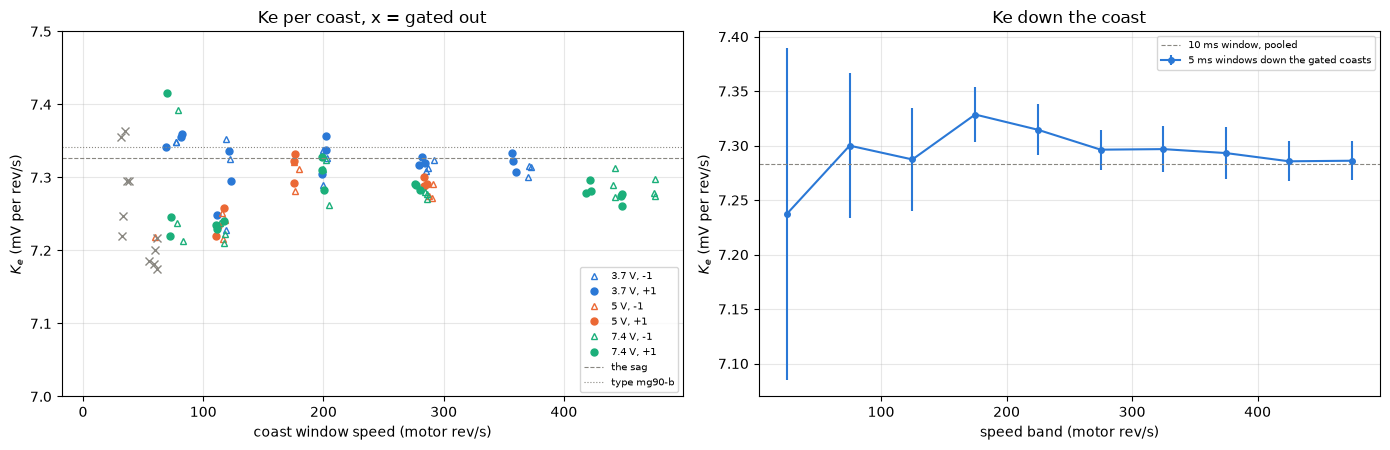

In [39]:
RAIL_COLOR = {3.7: BLUE, 5.0: ORANGE, 7.4: GREEN}
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
ladder = SPINS[SPINS["set"].isin(["capture-1", "rail-1"])]
for (v, d), g in ladder.groupby(["volts_set", "dir"]):
    style = figures.direction_style(d, RAIL_COLOR[v])
    ok, out = g[g["ke_gate"]], g[~g["ke_gate"]]
    ax[0].plot(ok["coast_rev_s"], ok["ke_mv_per_rev_s"], ms=5,
               label=f"{v:g} V, {d:+d}", **style)
    ax[0].plot(out["coast_rev_s"], out["ke_mv_per_rev_s"].clip(6.8, 7.6),
               ls="none", marker="x", ms=6, color=MUTED)
ax[0].axhline(KE_SAG, color=MUTED, ls="--", lw=0.8, label="the sag")
ax[0].axhline(KE_TYPE["value"], color=MUTED, ls=":", lw=0.8,
              label=f"type {TYPE_KEY}")
ax[0].set_ylim(7.0, 7.5)
figures.label(ax[0], x="coast window speed (motor rev/s)",
              y=r"$K_e$ (mV per rev/s)", title="Ke per coast, x = gated out")
ax[1].errorbar(WALK_BANDS["band"] + 25, WALK_BANDS["ke"],
               yerr=WALK_BANDS["sd"], fmt="o-", ms=4, color=BLUE,
               label="5 ms windows down the gated coasts")
ax[1].axhline(KE_POOLED, color=MUTED, ls="--", lw=0.8,
              label="10 ms window, pooled")
figures.label(ax[1], x="speed band (motor rev/s)",
              y=r"$K_e$ (mV per rev/s)", title="Ke down the coast")
for a in ax:
    a.legend(fontsize=7)
figures.finish(fig)

The 24 coasts that fail the gate are every coast at 3.7 V 15 and 20 % and 5 V 15 %, five of the six at 5 V 20 %, which read 58 to 61 rev/s on 3.3 to 3.5 cycles, and one ref-open-1 coast at 5 V 30 % that lost 0.36 of its speed across its window, just over the 0.35 gate. Every coast under about 60 rev/s fails. That is the coast route's validity envelope on this geared rotor, about 70 rev/s and up. The sag's 30 % coasts at 170 to 250 rev/s were all inside it. Down the coast $K_e$ is flat within +/-0.3 % from 150 to 500 rev/s, 7.29 to 7.33 by band. Under 150 rev/s the sd triples and the mean is set by the zero. The first 5 ms window's mean agrees with the 10 ms window's to 0.04 %, so the window's length is not a lever once the gate holds.

## The EMF at the cut over the tach

$E_0$ over $K_e$ times the drive tach's speed over the last 20 ms before the cut, the 10 ms window's speed over that tach, and the cut speed the window's line extrapolates to over the tach. A construction that leaves nothing out reads 1 for the first and the third.

In [40]:
SPINS["e0_over_tach"] = SPINS["e_cut_v"] / (
    KE_POOLED * 1e-3 * SPINS["spin_rev_s_last20"])
SPINS["win_speed_over_tach"] = (SPINS["coast_rev_s"]
                                / SPINS["spin_rev_s_last20"])
SPINS["cut_speed_over_tach"] = (SPINS["rev_s_cut_from_window"]
                                / SPINS["spin_rev_s_last20"])
SPINS["ripple_over_pot"] = SPINS["spin_rev_s"] / SPINS["pot_rev_s"].abs()
GATED = SPINS[SPINS["ke_gate"]]         # again, with the new columns
CUT = GATED.groupby(["volts_set", "duty_pct", "dir"]).agg(
    n=("k", "size"), tach=("spin_rev_s_last20", "mean"),
    e0_over_tach=("e0_over_tach", "mean"),
    win_over_tach=("win_speed_over_tach", "mean"),
    cut_over_tach=("cut_speed_over_tach", "mean")).reset_index()
show(CUT, n=None)
for col in ("e0_over_tach", "win_speed_over_tach", "cut_speed_over_tach"):
    print(f"{col}: {GATED[col].mean():.4f} sd {GATED[col].std():.4f}")
print(f"ripple over pot, every spin: {SPINS['ripple_over_pot'].mean():.3f} "
      f"sd {SPINS['ripple_over_pot'].std():.3f}")

,volts_set,duty_pct,dir,n,tach,e0_over_tach,win_over_tach,cut_over_tach
0,3.700,30.000,-1,3,98.204,0.993,0.802,0.984
1,3.700,30.000,1,3,94.394,1.038,0.822,1.028
2,3.700,40.000,-1,3,138.870,1.006,0.864,1.003
3,3.700,40.000,1,3,136.092,1.022,0.871,1.021
4,3.700,60.000,-1,3,223.868,0.995,0.896,0.991
5,3.700,60.000,1,3,221.720,1.004,0.907,0.997
6,3.700,80.000,-1,3,310.445,1.004,0.927,0.999
7,3.700,80.000,1,3,302.286,1.011,0.932,1.006
8,3.700,100.000,-1,3,394.242,1.008,0.941,1.004
9,3.700,100.000,1,3,381.189,1.014,0.940,1.009


e0_over_tach: 1.0037 sd 0.0276
win_speed_over_tach: 0.8890 sd 0.0547
cut_speed_over_tach: 1.0037 sd 0.0265
ripple over pot, every spin: 1.007 sd 0.091


$E_0 / (K_e\,\omega_\mathrm{tach})$ = 1.0037, sd 0.028, over the gated spins, 0.95 to 1.08 by rung, the 1.08 being the one gated coast at 5 V 20 %. The 7.4 V 60 and 67 % rungs read 1.03 to 1.07, where the tach's last 20 ms hold 2 to 3 cycles of a rotor still speeding up. High confidence that neither the coast's $E_0$ nor the drive tach carries a bias over 1 %.

The 10 ms window's speed sits at 0.889, sd 0.055, of the tach at the cut, against the sag's 0.906, because the rotor loses up to 35 % of its speed across the window, the `lost` column of the per-rung table, and the window's mean speed sits under the speed at the cut. On this rotor the window's speed is never the speed at the cut. The cut speed extrapolated through the window's line recovers 1.0037, sd 0.027, of the tach. $K_e$ itself is immune, since its EMF and its count come from the same rows, which the walk confirms. The ripple tach over the pot's slope reads 1.007, sd 0.091, the pot's noise and local slope setting the spread.

## The steady speed and current per rung

The speed the back-EMF line gives, $(V - R\,I_\mathrm{crest}) / K_e$, under constructions A, B and C, over the tach's speed less one. The steady numbers per rung follow, mean over three cycles, the tach's speed, the pot's, the crest current, the awake-zero current, the settled-equivalent current, the applied volts under A and B, the settle and the acceleration share.

In [41]:
for c in ("a", "b", "c"):
    i_col = "i_c_a" if c == "c" else "i_crest_a"
    SPINS[f"bemf_speed_{c}"] = (SPINS[f"v_{c}_v"]
                                - R_LOCKED * SPINS[i_col]) / KE
    SPINS[f"bemf_err_{c}_pct"] = (SPINS[f"bemf_speed_{c}"]
                                  / SPINS["spin_rev_s"] - 1) * 100


def ma(s):
    # amps to milliamps, the mean of a column
    return 1e3 * s.mean()


STEADY = SPINS.groupby(["set", "volts_set", "duty_pct", "dir"]).agg(
    window_ms=("window_ms", "mean"), speed=("spin_rev_s", "mean"),
    speed_sd=("spin_rev_s", "std"),
    pot=("pot_rev_s", lambda s: s.abs().mean()),
    i_ma=("i_crest_a", ma), i_sd_ma=("i_crest_a", lambda s: 1e3 * s.std()),
    i_awake_ma=("i_crest_awake_a", ma), i_settled_ma=("i_settled_a", ma),
    v_a=("v_a_v", "mean"), v_b=("v_b_v", "mean"),
    settle_pct=("settle_speed_pct", "mean"),
    accel_share=("accel_share", "mean"),
    dropouts=("dropouts_per_s", "mean"),
    bemf_err_a=("bemf_err_a_pct", "mean"),
    bemf_err_b=("bemf_err_b_pct", "mean")).reset_index()
show(STEADY[STEADY["set"].isin(["capture-1", "rail-1"])].drop(
    columns=["set"]), n=None)

,volts_set,duty_pct,dir,window_ms,speed,speed_sd,pot,i_ma,i_sd_ma,i_awake_ma,i_settled_ma,v_a,v_b,settle_pct,accel_share,dropouts,bemf_err_a,bemf_err_b
0,3.700,15.000,-1,100.000,36.018,2.127,34.831,66.209,3.855,68.402,96.813,0.544,0.491,28.046,-0.223,0.000,0.835,-19.576
1,3.700,15.000,1,100.000,32.534,2.742,34.624,72.601,4.665,74.837,114.818,0.544,0.489,8.133,-0.266,0.000,0.121,-23.225
2,3.700,20.000,-1,100.000,29.462,1.325,51.021,76.209,2.083,78.285,97.915,0.723,0.668,-1.759,-0.188,0.000,87.583,62.053
3,3.700,20.000,1,100.000,58.315,0.301,58.475,69.990,0.335,72.356,69.332,0.724,0.671,2.661,0.010,0.000,1.011,-11.529
4,3.700,30.000,-1,100.000,95.737,2.456,86.706,86.872,4.030,89.503,86.757,1.081,1.026,0.466,0.002,0.000,2.449,-5.383
5,3.700,30.000,1,100.000,93.786,1.691,85.871,88.792,1.528,91.864,90.646,1.081,1.026,-4.226,-0.020,0.000,3.406,-4.646
6,3.700,40.000,-1,100.000,137.854,0.568,129.018,94.371,0.526,97.330,94.655,1.437,1.383,-0.587,-0.003,0.000,3.445,-1.856
7,3.700,40.000,1,100.000,137.523,0.271,141.113,94.247,0.458,97.098,94.615,1.437,1.384,-0.689,-0.004,0.000,3.763,-1.549
8,3.700,60.000,-1,100.000,223.025,0.707,215.757,107.655,1.478,110.305,104.319,2.147,2.098,4.282,0.032,0.000,4.221,1.201
9,3.700,60.000,1,100.000,217.421,2.329,221.326,114.772,4.152,117.087,109.700,2.145,2.096,6.463,0.046,0.000,4.915,1.764


In [42]:
LADDER_SETS = ["capture-1", "rail-1"]
CAP = SPINS[SPINS["set"].isin(LADDER_SETS) & SPINS["ke_gate"]]
SETTLED = CAP[CAP["settle_speed_pct"].abs() < SETTLE_PCT]
n_settled = SETTLED.groupby(["volts_set", "duty_pct", "dir"]).ngroups
n_rungs = CAP.groupby(["volts_set", "duty_pct", "dir"]).ngroups
print(f"{n_settled} of {n_rungs} gated rung-directions hold a spin settled "
      f"within {SETTLE_PCT} %, of the ladder's 36")
gated_rungs = CAP.groupby(["volts_set", "duty_pct", "dir"]).agg(
    settle_pct=("settle_speed_pct", "mean"),
    accel_share=("accel_share", "mean")).reset_index()
run_ups = gated_rungs[gated_rungs["settle_pct"] > 10]
print("run-ups, over +10 %: " + ", ".join(
    f"{r.volts_set:g} V {r.duty_pct:.0f} % {r.dir:+d} "
    f"({r.settle_pct:+.0f} %, share {r.accel_share:.2f})"
    for r in run_ups.itertuples()))
SPEED_ON_V = {}
for (v, d), g in SETTLED.groupby(["volts_set", "dir"]):
    if len(g) >= 4:                     # a line needs a few spins
        fit = fit_line(g["v_a_v"], g["spin_rev_s"])
        SPEED_ON_V[f"{v:g} V {d:+d}"] = fit
        print(f"{v:g} V {d:+d}: {fit['slope']:.1f} +/- {fit['slope_se']:.1f}"
              f" rev/s per V of D x V_on, intercept {fit['intercept']:+.1f}, "
              f"rms {fit['rms']:.2f} (n {fit['n']}); 1/Ke {1 / KE:.1f}")

12 of 29 gated rung-directions hold a spin settled within 2.5 %, of the ladder's 36
run-ups, over +10 %: 3.7 V 80 % -1 (+16 %, share 0.16), 3.7 V 80 % +1 (+15 %, share 0.14), 3.7 V 100 % -1 (+19 %, share 0.30), 3.7 V 100 % +1 (+15 %, share 0.23), 5 V 60 % -1 (+17 %, share 0.17), 5 V 60 % +1 (+14 %, share 0.14), 7.4 V 40 % -1 (+16 %, share 0.15), 7.4 V 40 % +1 (+15 %, share 0.14), 7.4 V 60 % -1 (+14 %, share 0.37), 7.4 V 60 % +1 (+13 %, share 0.31), 7.4 V 67 % +1 (+14 %, share 0.43)
3.7 V -1: 114.5 +/- 1.1 rev/s per V of D x V_on, intercept -26.7, rms 0.34 (n 5); 1/Ke 137.3
3.7 V +1: 118.2 +/- 0.8 rev/s per V of D x V_on, intercept -32.3, rms 0.17 (n 4); 1/Ke 137.3
5 V -1: 119.6 +/- 0.7 rev/s per V of D x V_on, intercept -35.2, rms 0.51 (n 7); 1/Ke 137.3
7.4 V -1: 114.8 +/- 0.6 rev/s per V of D x V_on, intercept -29.2, rms 0.23 (n 6); 1/Ke 137.3
7.4 V +1: 114.2 +/- 3.2 rev/s per V of D x V_on, intercept -31.4, rms 0.98 (n 5); 1/Ke 137.3


In [43]:
pair = CAP.pivot_table(index=["volts_set", "duty_pct"], columns="dir",
                      values=["spin_rev_s", "i_crest_a"])   # gated only
pair = pair.dropna()                    # rungs read in both directions
more_i = (pair[("i_crest_a", 1)] - pair[("i_crest_a", -1)]) * 1e3   # mA
slower = (1 - pair[("spin_rev_s", 1)] / pair[("spin_rev_s", -1)]) * 100
print(f"direction +1 over -1 at {len(pair)} rungs: current {more_i.min():+.1f}"
      f" to {more_i.max():+.1f} mA, speed {slower.min():.1f} to "
      f"{slower.max():.1f} % slower")

direction +1 over -1 at 14 rungs: current -0.1 to +20.5 mA, speed 0.2 to 3.8 % slower


The settle against the speed per rung. The thing to see is which rungs reach a steady speed inside the runway and which are still speeding up.

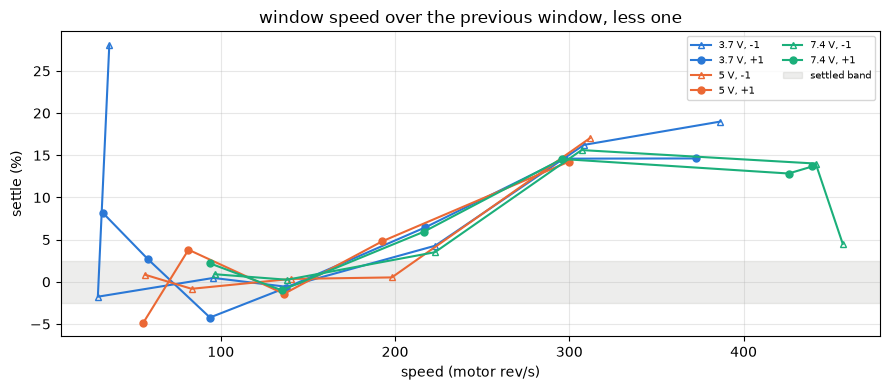

In [44]:
fig, ax = plt.subplots(figsize=(9, 4))
for (v, d), g in STEADY[STEADY["set"].isin(LADDER_SETS)].groupby(
        ["volts_set", "dir"]):
    style = {**figures.direction_style(d, RAIL_COLOR[v]), "ls": "-"}
    ax.plot(g["speed"], g["settle_pct"], ms=5, label=f"{v:g} V, {d:+d}",
            **style)
ax.axhspan(-SETTLE_PCT, SETTLE_PCT, color=MUTED, alpha=0.15,
           label="settled band")
ax.legend(fontsize=7, ncol=2)
figures.label(ax, x="speed (motor rev/s)",
              y="settle (%)",
              title="window speed over the previous window, less one")
figures.finish(fig)

The runway cut the spins to 1200 ms at 15 % and down to 53 ms at 7.4 V 67 %. The long spins at 15 to 40 % mostly settle within 2.5 %, with 3.7 V 30 % in direction +1 at -4.2 % the exception among them. The 200 to 300 ms spins, 3.7 V 60 %, 7.4 V 30 % and 5 V 40 % in direction +1, read +3.5 to +6.5 %. The top rungs, 5 V 60 %, 7.4 V 40 and 60 %, 3.7 V 80 and 100 % and 7.4 V 67 % in direction +1, read +13 to +19 % and are run-ups, not steady states. 12 of the ladder's 36 rung-directions hold a spin settled within 2.5 %. The acceleration share is 0.14 to 0.43 on the top rungs, and the settled-equivalent current takes their crest down by about a quarter, 220 to 161 mA at 7.4 V 60 % in direction -1. That correction belongs to the friction read only.

At the 14 rungs read in both directions, direction +1 draws -0.1 to +20.5 mA more than -1 and runs 0.2 to 3.8 % slower, as the type's +1 runs slower. Speed on $V_A$ over the settled spins reads 114 to 120 rev/s per volt with intercepts of -27 to -35 rev/s and an rms of 0.2 to 1.0 rev/s per rail and direction. $1/K_e$ would be 137 rev/s per volt, and the shortfall is $R\,I$ and the brush drop.

### The awake zero on three rails

The coast tail's awake step over the rest zero by rail, the slow-decay trough over the rest zero at duties of 30 % and under, and the step's line on the rail.

In [45]:
AWAKE = SPINS.groupby("volts_set")["awake_step_counts"].agg(["mean", "std"])
TROUGH = SPINS[SPINS["duty_pct"] <= 30].groupby("volts_set")[
    "trough_over_zero_counts"].mean()
AWAKE_FIT = fit_line(SPINS["rail_v"], SPINS["awake_step_counts"])
for v, r in AWAKE.iterrows():
    print(f"{v:g} V: awake step {r['mean']:.2f} sd {r['std']:.2f} counts, "
          f"trough {TROUGH[v]:.2f} counts")
print(f"awake step on the rail: {AWAKE_FIT['slope']:.3f} +/- "
      f"{AWAKE_FIT['slope_se']:.3f} counts/V, intercept "
      f"{AWAKE_FIT['intercept']:.2f}; at 5 V "
      f"{AWAKE_FIT['slope'] * 5 + AWAKE_FIT['intercept']:.2f}, at 7.2 V "
      f"{AWAKE_FIT['slope'] * 7.2 + AWAKE_FIT['intercept']:.2f}")
print(f"stage 1 in-drive offset {I_DRIVE_OFFSET:.2f} counts; the sag's "
      f"awake step {AWAKE_STEP_SAG:.2f} on 6.0 to 8.4 V")

3.7 V: awake step 2.34 sd 0.58 counts, trough 3.17 counts
5 V: awake step 5.89 sd 0.49 counts, trough 6.62 counts
7.4 V: awake step 9.24 sd 0.58 counts, trough 10.22 counts
awake step on the rail: 1.811 +/- 0.047 counts/V, intercept -3.80; at 5 V 5.26, at 7.2 V 9.24
stage 1 in-drive offset 5.26 counts; the sag's awake step 9.20 on 6.0 to 8.4 V


The awake step is 2.34 sd 0.58 counts at 3.7 V, 5.89 sd 0.49 at 5 V and 9.24 sd 0.58 at 7.4 V, a line of 1.811 +/- 0.047 counts per volt with an intercept of -3.80, high confidence. The slow-decay trough at 30 % and under sits 0.8 to 1.0 counts over the tail. The sag's 9.20 counts, flat over 6.0 to 8.4 V, sits on this line's 7.2 V value, and stage 1's in-drive offset of 5.26 counts is its 5 V value. So construction A's current reads 2.6 mA high at 3.7 V and 3.5 mA low at 7.4 V against the awake zero. That is the stage 2 takeaway's step that grows with the rail, measured here on this servo on three rails.

### The current against the speed, for friction

Per rung over the spins with a valid tach, the gated coasts over 50 rev/s, the crest current, the settled-equivalent and the awake-zero current, with the type's bare drag curve on 5 V. The friction notebook reads this table.

In [46]:
TACH_OK = SPINS["ke_gate"] & (SPINS["spin_rev_s"] > 50)
tach = SPINS[SPINS["set"].isin(LADDER_SETS) & TACH_OK].copy()
tach["settled"] = tach["settle_speed_pct"].abs() < SETTLE_PCT
FRICTION = tach.groupby(["volts_set", "duty_pct", "dir"]).agg(
    rev_s=("spin_rev_s", "mean"), i_ma=("i_crest_a", ma),
    i_settled_ma=("i_settled_a", ma), i_awake_ma=("i_crest_awake_a", ma),
    accel_share=("accel_share", "mean"), settled=("settled", "all"),
    i_sd=("i_crest_a", lambda s: 1e3 * s.std())).reset_index()
a5, b5 = DRAG_5V["a_a"]["value"], DRAG_5V["b_a"]["value"]
FRICTION["type_i0_5v_ma"] = (a5 + b5 * np.log(FRICTION["rev_s"] / 100.0)
                             ) * 1e3   # the type's bare crest reading
FRICTION["over_type_ma"] = FRICTION["i_ma"] - FRICTION["type_i0_5v_ma"]
settled_rungs = FRICTION[FRICTION["settled"]]["over_type_ma"]
print(f"crest over the type's 5 V drag, settled rungs: "
      f"{settled_rungs.min():.0f} to {settled_rungs.max():.0f} mA; every "
      f"rung {FRICTION['over_type_ma'].min():.0f} to "
      f"{FRICTION['over_type_ma'].max():.0f}")
at137 = FRICTION[FRICTION["settled"] & (FRICTION["rev_s"] > 130)
                 & (FRICTION["rev_s"] < 145)]
CREST_ON_RAIL = fit_line(at137["volts_set"], at137["i_ma"])
AWAKE_ON_RAIL = fit_line(at137["volts_set"], at137["i_awake_ma"])
print(f"at {at137['rev_s'].mean():.0f} rev/s over {len(at137)} settled rungs: "
      f"crest {CREST_ON_RAIL['slope']:+.2f} +/- "
      f"{CREST_ON_RAIL['slope_se']:.2f} mA/V of rail, awake-zero current "
      f"{AWAKE_ON_RAIL['slope']:+.2f} +/- {AWAKE_ON_RAIL['slope_se']:.2f}")
print(at137[["volts_set", "dir", "rev_s", "i_ma", "i_awake_ma"]].round(1)
      .to_string(index=False))

crest over the type's 5 V drag, settled rungs: 14 to 34 mA; every rung 13 to 199
at 137 rev/s over 6 settled rungs: crest +4.45 +/- 0.79 mA/V of rail, awake-zero current +2.81 +/- 0.72
 volts_set  dir  rev_s  i_ma  i_awake_ma
       3.7   -1  137.9  94.4        97.3
       3.7    1  137.5  94.2        97.1
       5.0   -1  140.1 100.8       100.2
       5.0    1  136.3 105.4       104.9
       7.4   -1  138.0 108.7       105.2
       7.4    1  134.9 113.9       110.6


The steady speed against the applied volts, A filled or open by direction and B as crosses, the crest current and the settled-equivalent current against the speed with the type's bare 5 V curve, and the back-EMF speed's error under A and B. The thing to see is that at a fixed speed the crest current rises with the rail, and that neither construction closes the back-EMF speed at every rung.

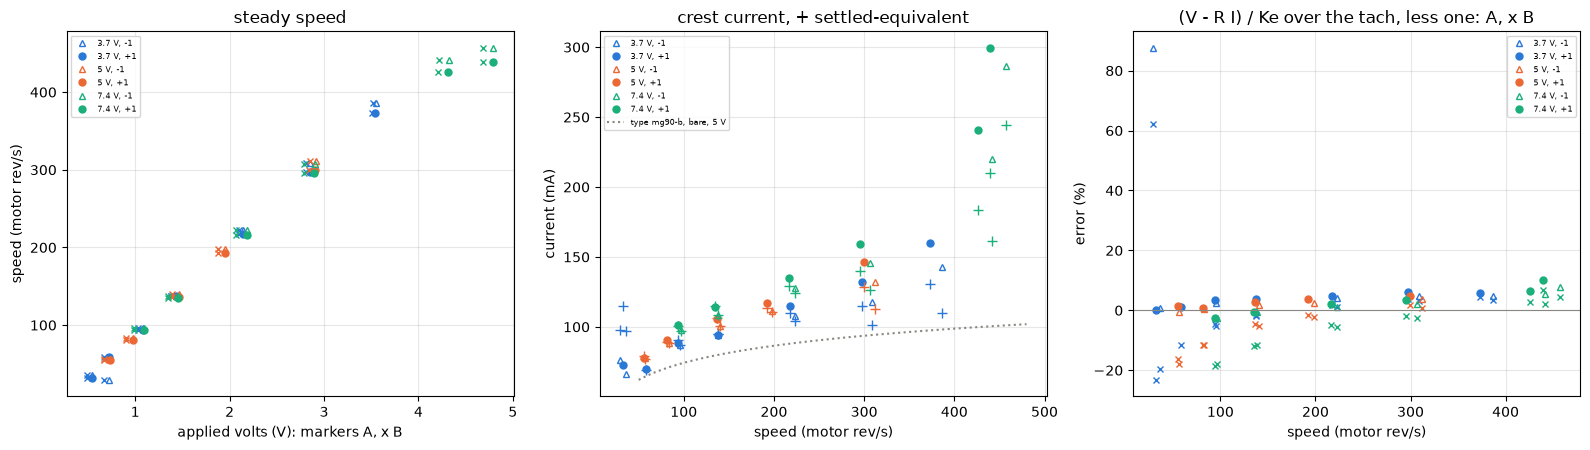

In [47]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
steady = STEADY[STEADY["set"].isin(LADDER_SETS)]
for (v, d), h in steady.groupby(["volts_set", "dir"]):
    style = figures.direction_style(d, RAIL_COLOR[v])
    ax[0].plot(h["v_a"], h["speed"], ms=5, label=f"{v:g} V, {d:+d}",
               **style)
    ax[0].plot(h["v_b"], h["speed"], ls="none", marker="x", ms=5,
               color=RAIL_COLOR[v])
    ax[1].plot(h["speed"], h["i_ma"], ms=5, label=f"{v:g} V, {d:+d}",
               **style)
    ax[1].plot(h["speed"], h["i_settled_ma"], ls="none", marker="+",
               ms=7, color=RAIL_COLOR[v])
    ax[2].plot(h["speed"], h["bemf_err_a"], ms=5, label=f"{v:g} V, {d:+d}",
               **style)
    ax[2].plot(h["speed"], h["bemf_err_b"], ls="none", marker="x", ms=5,
               color=RAIL_COLOR[v])
w = np.linspace(50, 480, 50)
ax[1].plot(w, (a5 + b5 * np.log(w / 100)) * 1e3, ls=":", color=MUTED,
           label=f"type {TYPE_KEY}, bare, 5 V")
ax[2].axhline(0, color=MUTED, lw=0.8)
figures.label(ax[0], x="applied volts (V): markers A, x B",
              y="speed (motor rev/s)", title="steady speed")
figures.label(ax[1], x="speed (motor rev/s)", y="current (mA)",
              title="crest current, + settled-equivalent")
figures.label(ax[2], x="speed (motor rev/s)", y="error (%)",
              title="(V - R I) / Ke over the tach, less one: A, x B")
for a in ax:
    a.legend(fontsize=6)
figures.finish(fig)

At 137 rev/s the crest current over the six settled rungs at 3.7 V 40 %, 5 V 30 % and 7.4 V 20 % reads 94, 101 to 105 and 109 to 114 mA, a rise of +4.45 +/- 0.79 mA per volt of rail, 5.6 sigma. High confidence that the crest reading carries a rail term at a fixed speed. The awake-zero current narrows it to +2.8 +/- 0.7 mA per volt. Against the type's bare 5 V drag curve the crest sits 14 to 34 mA higher at every settled rung, the train's drag in Super Lube plus the servo's rail term together.

## The brackets

The 5 V 30 % reference rung through sitting 1, the servo's first hour, and sitting 6, two days later after the locked sittings, with capture-1's own 5 V 30 % rung in between.

In [48]:
is_ref = SPINS["set"].str.startswith("ref")
in_ladder = ((SPINS["set"] == "capture-1") & (SPINS["volts_set"] == 5.0)
             & (SPINS["duty_pct"].round() == 30))
ref = SPINS[is_ref | in_ladder].copy()
ref["block"] = np.where(ref["set"] == "capture-1", "capture-1 5 V 30 %",
                        ref["set"])
ORDER = ["ref-open-1", "capture-1 5 V 30 %", "ref-close-1", "ref-open-6",
         "ref-close-6"]
DRIFT = ref.groupby(["block", "dir"]).agg(
    t=("t_start", "mean"), speed=("spin_rev_s", "mean"),
    speed_sd=("spin_rev_s", "std"), i_ma=("i_crest_a", ma),
    i_sd=("i_crest_a", lambda s: 1e3 * s.std()),
    ke=("ke_mv_per_rev_s", "mean"), ke_sd=("ke_mv_per_rev_s", "std"),
    dropouts=("dropouts_per_s", "mean"), ntc=("ntc_c", "mean")
).reset_index()
DRIFT["min_from_open1"] = (DRIFT["t"] - DRIFT["t"].min()) / 60
DRIFT["rank"] = DRIFT["block"].map(ORDER.index)
DRIFT = DRIFT.sort_values(["rank", "dir"], ascending=[True, False])
show(DRIFT.drop(columns=["t", "rank"]), n=None)

,block,dir,speed,speed_sd,i_ma,i_sd,ke,ke_sd,dropouts,ntc,min_from_open1
7,ref-open-1,1,136.090,1.173,106.816,2.232,7.241,0.052,0.000,26.007,0.000
6,ref-open-1,-1,140.065,0.610,101.479,1.453,7.239,0.053,0.000,26.007,0.000
1,capture-1 5 V 30 %,1,136.324,0.293,105.411,0.238,7.237,0.019,0.000,25.749,34.158
0,capture-1 5 V 30 %,-1,140.136,0.396,100.835,0.354,7.236,0.019,0.000,25.749,34.158
3,ref-close-1,1,138.254,0.514,99.604,0.848,7.251,0.049,0.000,25.110,229.125
2,ref-close-1,-1,141.611,0.721,96.770,1.379,7.258,0.045,0.000,25.110,229.125
9,ref-open-6,1,140.929,0.671,98.007,0.970,7.249,0.026,0.000,26.495,2598.744
8,ref-open-6,-1,143.075,0.464,96.201,0.704,7.240,0.029,0.000,26.495,2598.744
5,ref-close-6,1,139.789,0.436,99.196,0.422,7.261,0.040,0.000,26.621,2603.781
4,ref-close-6,-1,143.024,0.485,95.851,0.550,7.252,0.036,0.000,26.621,2603.781


In [49]:
def diff(a, b, col, sd, pct=True):
    # b over a: (change, se), the two blocks' sds in quadrature over root 3
    se = np.hypot(a[sd], b[sd]) / np.sqrt(3)
    if pct:
        return (b[col] / a[col] - 1) * 100, se / a[col] * 100
    return b[col] - a[col], se


BLOCK = DRIFT.set_index(["block", "dir"])
BRACKET = {}
for d in (1, -1):
    o1, c1 = BLOCK.loc[("ref-open-1", d)], BLOCK.loc[("ref-close-1", d)]
    o6, c6 = BLOCK.loc[("ref-open-6", d)], BLOCK.loc[("ref-close-6", d)]
    BRACKET[d] = {
        "speed_1": diff(o1, c1, "speed", "speed_sd"),
        "current_1": diff(o1, c1, "i_ma", "i_sd", pct=False),
        "speed_6_over_1": diff(c1, o6, "speed", "speed_sd"),
        "current_6_over_1": diff(c1, o6, "i_ma", "i_sd", pct=False),
        "speed_6": diff(o6, c6, "speed", "speed_sd"),
        "ke_1": diff(o1, c1, "ke", "ke_sd")}
    for key, (val, se) in BRACKET[d].items():
        print(f"{d:+d} {key}: {val:+.2f} +/- {se:.2f} "
              f"({val / se:+.1f} sigma)")

+1 speed_1: +1.59 +/- 0.54 (+2.9 sigma)
+1 current_1: -7.21 +/- 1.38 (-5.2 sigma)
+1 speed_6_over_1: +1.93 +/- 0.35 (+5.5 sigma)
+1 current_6_over_1: -1.60 +/- 0.74 (-2.1 sigma)
+1 speed_6: -0.81 +/- 0.33 (-2.5 sigma)
+1 ke_1: +0.15 +/- 0.57 (+0.3 sigma)
-1 speed_1: +1.10 +/- 0.39 (+2.8 sigma)
-1 current_1: -4.71 +/- 1.16 (-4.1 sigma)
-1 speed_6_over_1: +1.03 +/- 0.35 (+3.0 sigma)
-1 current_6_over_1: -0.57 +/- 0.89 (-0.6 sigma)
-1 speed_6: -0.04 +/- 0.27 (-0.1 sigma)
-1 ke_1: +0.26 +/- 0.55 (+0.5 sigma)


The blocks' times, and the run-in bound on the crest's rail slope. The bracket's fall in current over its span, scaled to capture-1's span, against the rise of the crest current from 3.7 V 40 % to 7.4 V 20 % at 137 rev/s.

In [50]:
t0 = TABLES["ref-open-1"]["t_start"].min()   # the bracket's first cycle
SPAN = {name: ((TABLES[name]["t_start"].min() - t0) / 60,
               (TABLES[name]["t_end"].max() - t0) / 60)
        for name in ("capture-1", "low-1", "rail-1", "ref-close-1")}
for name, (start, end) in SPAN.items():
    print(f"{name}: {start:.1f} to {end:.1f} min after ref-open-1 opened")
bracket_min = BLOCK.loc[("ref-close-1", 1), "min_from_open1"]
capture_min = SPAN["capture-1"][1] - SPAN["capture-1"][0]
rung = at137.set_index(["volts_set", "dir"])["i_ma"]
for d in (1, -1):
    fall = -BRACKET[d]["current_1"][0]  # mA over the bracket's span
    bound = fall * capture_min / bracket_min
    rise = rung[(7.4, d)] - rung[(3.7, d)]
    print(f"{d:+d}: bracket fell {fall:.1f} mA over {bracket_min:.0f} min; "
          f"over capture-1's {capture_min:.0f} min at most {bound:.2f} mA "
          f"of the {rise:.1f} mA rise, {bound / rise * 100:.0f} %")

capture-1: 8.4 to 63.9 min after ref-open-1 opened
low-1: 64.2 to 132.3 min after ref-open-1 opened
rail-1: 171.2 to 182.7 min after ref-open-1 opened
ref-close-1: 229.0 to 232.6 min after ref-open-1 opened
+1: bracket fell 7.2 mA over 229 min; over capture-1's 55 min at most 1.74 mA of the 19.7 mA rise, 9 %
-1: bracket fell 4.7 mA over 229 min; over capture-1's 55 min at most 1.14 mA of the 14.3 mA rise, 8 %


The five blocks' speed and crest current with their sds, by direction. The thing to see is the first hour's rise in speed and fall in current, and how little moved within sitting 6.

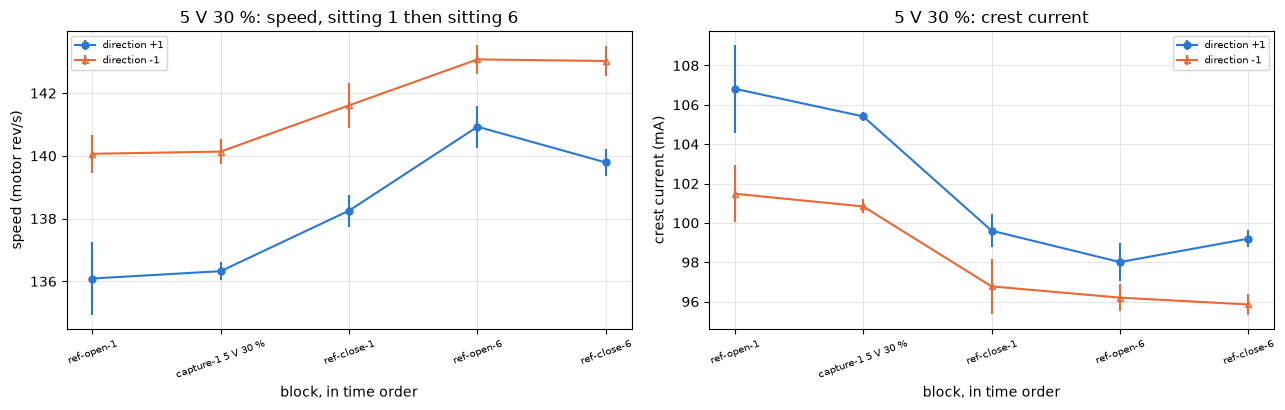

In [51]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for d, color in ((1, BLUE), (-1, ORANGE)):
    h = DRIFT[DRIFT["dir"] == d]
    style = {**figures.direction_style(d, color), "ls": "-"}
    x = np.arange(len(h))
    ax[0].errorbar(x, h["speed"], yerr=h["speed_sd"], ms=5,
                   label=f"direction {d:+d}", **style)
    ax[1].errorbar(x, h["i_ma"], yerr=h["i_sd"], ms=5,
                   label=f"direction {d:+d}", **style)
for a in ax:
    a.set_xticks(range(len(ORDER)))
    a.set_xticklabels(ORDER, rotation=20, fontsize=7)
    a.legend(fontsize=7)
figures.label(ax[0], x="block, in time order", y="speed (motor rev/s)",
              title="5 V 30 %: speed, sitting 1 then sitting 6")
figures.label(ax[1], x="block, in time order", y="crest current (mA)",
              title="5 V 30 %: crest current")
figures.finish(fig)

Open to close of sitting 1, 229 minutes apart, the speed rose +1.59 +/- 0.54 % in direction +1 and +1.10 +/- 0.39 % in -1, 2.9 and 2.8 sigma, and the crest current fell -7.2 +/- 1.4 mA and -4.7 +/- 1.2 mA, 5.2 and 4.1 sigma. High confidence the servo ran in through its first hour, less drag at the same rung, with the current the sharper instrument. Sitting 6's open sits +1.9 % and +1.0 % over sitting 1's close in speed and -1.6 and -0.6 mA in current, and sitting 6's own open to close moved -0.8 % and 0.0 % in speed. Likely the run-in went on between the sittings at a slower rate, and sitting 6 is stable to the bracket's resolution, about 0.45 % of speed within a block. $K_e$ moved +0.15 +/- 0.57 % and +0.26 +/- 0.55 % open to close, under 1 sigma, not a finding. The board NTC fell 0.9 C through sitting 1.

capture-1's rungs ran 8 to 64 minutes after ref-open-1 opened, 3.7 V first and 7.4 V last. The order and the drift line up, so a part of the crest's +4.45 mA per volt rail slope could be run-in. Scaled to capture-1's 55 minutes, the bracket's fall of 7.2 and 4.7 mA over 229 minutes allows at most 1.7 and 1.1 mA of the 19.7 and 14.3 mA the crest rose from 3.7 V 40 % to 7.4 V 20 %, about a tenth, if the run-in ran at an even rate.

## The dropouts

Every gated ladder spin with dropout rows, and the rate.

In [52]:
drops = CAP[CAP["dropouts_per_s"] > 0]
print(f"{len(drops)} of {len(CAP)} gated spins carry dropouts, at most "
      f"{CAP['dropouts_per_s'].max():.0f} per s:")
for r in drops.itertuples():
    print(f"  {r.volts_set:g} V {r.duty_pct:.0f} % {r.dir:+d} cycle {r.k}: "
          f"{r.dropouts_per_s:.0f} per s at {r.spin_rev_s:.0f} rev/s")
print(f"reference rungs: {DRIFT['dropouts'].max():.0f} per s at most")

5 of 85 gated spins carry dropouts, at most 76 per s:
  7.4 V 60 % +1 cycle 43: 28 per s at 427 rev/s
  7.4 V 60 % +1 cycle 44: 56 per s at 427 rev/s
  7.4 V 67 % +1 cycle 6: 38 per s at 438 rev/s
  7.4 V 67 % +1 cycle 7: 76 per s at 441 rev/s
  7.4 V 67 % +1 cycle 8: 38 per s at 439 rev/s
reference rungs: 0 per s at most


The brush-drop residual, used here for the dropout coefficient and in the next section for the table, is

$$X = V - K_e\,\omega - R\,I$$

per spin in mV, with $\omega$ the tach's speed over the window, this notebook's $K_e$, the locked $R$, and $V$ and $I$ under each construction. Identification's dropout term fits $X = S(\mathrm{rung}) + k_d\,r_d$, one level per rung and $k_d$ ("k d") the coefficient on the dropout rate $r_d$.

In [53]:
XS = SPINS[SPINS["set"].isin(LADDER_SETS) & SPINS["ke_gate"]].copy()
FORMS = {"A": XS["v_a_v"] - KE * XS["spin_rev_s"]
         - R_LOCKED * XS["i_crest_a"],
         "B": XS["v_b_v"] - KE * XS["spin_rev_s"]
         - R_LOCKED * XS["i_crest_a"],
         "C": XS["v_c_v"] - KE * XS["spin_rev_s"] - R_LOCKED * XS["i_c_a"]}
for name, x in FORMS.items():
    XS[f"x_{name}_mv"] = x * 1e3


def dropout_term(T, x):
    # identification.dropout_term, mirrored: X = S(rung) + k_d x rate
    level = pd.DataFrame({"v": T["volts_set"], "d": T["duty_pct"].round()})
    keys = pd.factorize(level.apply(tuple, axis=1))[0]   # one per rung
    rate = T["dropouts_per_s"].to_numpy(float)
    n, nk = len(T), int(keys.max()) + 1
    design = np.zeros((n, nk + 1))
    design[np.arange(n), keys] = 1.0
    design[:, -1] = rate
    y = np.asarray(x, float)
    beta = np.linalg.lstsq(design, y, rcond=None)[0]
    res = y - design @ beta
    dof = n - (nk + 1)
    cov = np.linalg.pinv(design.T @ design) * (res @ res / max(dof, 1))
    return float(beta[-1]), float(np.sqrt(cov[-1, -1])), int(dof)


K_D = {name: dropout_term(XS, XS[f"x_{name}_mv"]) for name in FORMS}
for name, (k_d, se, dof) in K_D.items():
    print(f"{name}: k_d {k_d:+.3f} +/- {se:.3f} mV per dropout/s (dof {dof})")

A: k_d +0.806 +/- 0.125 mV per dropout/s (dof 69)
B: k_d +0.781 +/- 0.121 mV per dropout/s (dof 69)
C: k_d +0.781 +/- 0.121 mV per dropout/s (dof 69)


In [54]:
for pair in (TYPE_KEY, "mg90-c"):
    kd = results.read("2-motor", "identification",
                      pair=pair)["v_b_mv"]["k_d_mv_per_dropout_s"]
    print(f"{pair} identification k_d {kd['value']:.2f} ({kd['lo']:.2f} to "
          f"{kd['hi']:.2f}), reference {kd['reference']['value']:.2f}")

mg90-b identification k_d 0.51 (0.42 to 0.80), reference 0.52
mg90-c identification k_d 0.54 (0.28 to 0.58), reference 0.44


Only two rungs drop out, 7.4 V 60 % and 67 % in direction +1, five spins at 28 to 76 rows per second. Direction -1 never dropped out, nor did any rung under 420 rev/s or any reference rung. The fit gives $k_d$ = +0.81 +/- 0.13 mV per dropout per second under A and +0.78 +/- 0.12 under B, 6 sigma formally. It is read from five spins, one direction and two rungs, and the +1 over -1 split at those rungs is also the brush drop's direction term, so $k_d$ is a candidate at best. Stage 2's identification values above are the ones to carry until a sitting drops out in both directions.

## The brush drop

### As read

$X$ per rung and direction under A, B and C, the rung means with the dropout term above taken out at the five spins that carry dropouts, as identification's fit does.

In [55]:
def rung_means(name):
    # X's rung means per direction, the dropout term out
    k_d = max(K_D[name][0], 0.0)
    x = XS[f"x_{name}_mv"] - k_d * XS["dropouts_per_s"]
    frame = pd.DataFrame({"volts_set": XS["volts_set"],
                          "duty": XS["duty_pct"].round(), "dir": XS["dir"],
                          "rev_s": XS["spin_rev_s"], "x": x})
    rm = frame.groupby(["volts_set", "duty", "dir"]).agg(
        rev_s=("rev_s", "mean"), x=("x", "mean"), sd=("x", "std"),
        n=("x", "size")).reset_index()
    rm["x_se"] = rm["sd"] / np.sqrt(rm["n"])
    return rm


AS_READ = {name: rung_means(name) for name in FORMS}
table = AS_READ["A"][["volts_set", "duty", "dir", "rev_s"]].copy()
for name, rm in AS_READ.items():
    table[f"x_{name}_mv"] = rm["x"].to_numpy()
    table[f"sd_{name}"] = rm["sd"].to_numpy()
show(table.sort_values(["volts_set", "duty", "dir"]), n=None)

,volts_set,duty,dir,rev_s,x_A_mv,sd_A,x_B_mv,sd_B,x_C_mv,sd_C
0,3.700,30.000,-1,95.737,17.067,0.106,-37.501,0.786,-0.066,0.814
1,3.700,30.000,1,93.786,23.196,5.211,-31.783,4.915,5.653,4.890
2,3.700,40.000,-1,137.854,34.580,1.824,-18.641,1.777,13.131,1.763
3,3.700,40.000,1,137.523,37.690,1.451,-15.513,1.496,16.263,1.501
4,3.700,60.000,-1,223.025,68.555,1.305,19.512,1.472,40.326,1.472
5,3.700,60.000,1,217.421,77.831,1.417,27.936,1.887,48.735,1.896
6,3.700,80.000,-1,308.393,110.904,1.696,67.794,1.564,78.026,1.560
7,3.700,80.000,1,297.151,128.817,4.189,84.892,4.132,95.106,4.131
8,3.700,100.000,-1,386.508,133.451,6.310,97.539,6.320,97.539,6.320
9,3.700,100.000,1,372.656,153.638,2.699,117.746,2.715,117.746,2.715


The split at a matched speed, the 7.4 V rung less the 3.7 V rung of about the same speed, under each construction, and $X$'s slope on the speed within a rail under A.

In [56]:
MATCHED = ((30, 15), (40, 20), (60, 30), (80, 40))   # 3.7 V vs 7.4 V
rows = []
for duty_lo, duty_hi in MATCHED:
    for d in (1, -1):
        row = {"rungs": f"3.7 V {duty_lo} % / 7.4 V {duty_hi} %", "dir": d}
        for name, rm in AS_READ.items():
            lo = rm[(rm["volts_set"] == 3.7) & (rm["duty"] == duty_lo)
                    & (rm["dir"] == d)].iloc[0]
            hi = rm[(rm["volts_set"] == 7.4) & (rm["duty"] == duty_hi)
                    & (rm["dir"] == d)].iloc[0]
            row["rev_s"] = (lo["rev_s"] + hi["rev_s"]) / 2
            row[f"split_{name}_mv"] = hi["x"] - lo["x"]
        rows.append(row)
show(pd.DataFrame(rows), n=None)
for top in (320, 500):                  # without and with the top rungs
    slopes = [fit_line(h["rev_s"], h["x"])["slope"] for _, h in
              AS_READ["A"][AS_READ["A"]["rev_s"] < top].groupby(
                  ["volts_set", "dir"])]
    print(f"X under A on speed within a rail, rungs under {top} rev/s: "
          f"{min(slopes):.2f} to {max(slopes):.2f} mV per rev/s, "
          f"{min(slopes) / KE_POOLED * 100:.0f} to "
          f"{max(slopes) / KE_POOLED * 100:.0f} % of Ke")

,rungs,dir,rev_s,split_A_mv,split_B_mv,split_C_mv
0,3.7 V 30 % / 7.4 V 15 %,1,93.896,-41.231,-94.597,-39.027
1,3.7 V 30 % / 7.4 V 15 %,-1,96.096,-35.933,-88.671,-33.097
2,3.7 V 40 % / 7.4 V 20 %,1,136.207,-44.068,-100.573,-45.259
3,3.7 V 40 % / 7.4 V 20 %,-1,137.948,-41.731,-96.927,-41.613
4,3.7 V 60 % / 7.4 V 30 %,1,216.917,-44.620,-105.356,-50.660
5,3.7 V 60 % / 7.4 V 30 %,-1,222.962,-51.348,-111.407,-56.704
6,3.7 V 80 % / 7.4 V 40 %,1,296.452,-57.073,-123.915,-70.038
7,3.7 V 80 % / 7.4 V 40 %,-1,307.715,-60.126,-125.363,-71.428


X under A on speed within a rail, rungs under 320 rev/s: 0.33 to 0.52 mV per rev/s, 5 to 7 % of Ke
X under A on speed within a rail, rungs under 500 rev/s: 0.37 to 0.77 mV per rev/s, 5 to 11 % of Ke


Identification's speed-table rule makes a table per direction from these rung means. It interpolates to the knots, sets the knots at and under 150 rev/s to the mean of the rungs under 160 rev/s if the rails agree there within 2 standard errors and to zero if not, and clips at zero. Its extrapolation past the last rung would manufacture 1 to 2 V at 650 rev/s from run-up rungs here, so no knot past the top rung is kept.

In [57]:
def speed_table(rm):
    # identification.fit_vb's table, mirrored, with no knot past the top
    low = rm[rm["rev_s"] < LOW_SPEED]
    by = low.groupby("volts_set").agg(
        x=("x", "mean"),
        se=("x_se", lambda s: np.sqrt((s ** 2).sum()) / len(s)))
    split = abs(by["x"].iloc[0] - by["x"].iloc[-1]) / np.hypot(
        by["se"].iloc[0], by["se"].iloc[-1])
    floor = 0.0 if split > 2 else float(low["x"].mean())
    out = {"floor_mv": floor, "floor_split_se": split}
    for d, h in rm.groupby("dir"):
        s = h.sort_values("rev_s")
        xs, ys = s["rev_s"].to_numpy(), s["x"].to_numpy()
        tab = np.interp(KNOTS_ID, xs, ys)
        beyond = KNOTS_ID > xs[-1]      # the last segment, extended
        tab[beyond] = ys[-1] + (ys[-1] - ys[-2]) / (xs[-1] - xs[-2]) * (
            KNOTS_ID[beyond] - xs[-1])
        tab[KNOTS_ID <= 150] = floor
        tab = np.maximum(tab, 0.0)
        tab[KNOTS_ID > xs[-1] + 25] = np.nan     # past the top rung
        out[int(d)] = tab
    return out


ID_TABLES = {name: speed_table(rm) for name, rm in AS_READ.items()}
for name, tab in ID_TABLES.items():
    print(f"{name}: floor {tab['floor_mv']:.1f} mV, rails apart "
          f"{tab['floor_split_se']:.1f} se; +1 " + " ".join(
              f"{v:.0f}" for v in tab[1][:7]) + " mV at 150 to 450 rev/s")

A: floor 0.0 mV, rails apart 44.9 se; +1 0 46 75 106 139 166 373 mV at 150 to 450 rev/s
B: floor 0.0 mV, rails apart 107.2 se; +1 0 0 0 37 93 92 263 mV at 150 to 450 rev/s
C: floor 0.0 mV, rails apart 44.9 se; +1 0 15 39 66 101 113 291 mV at 150 to 450 rev/s


$X$ as read against the speed under A, B and C, by rail and direction with the rung's sd, and identification's table per direction. The thing to see is that at a matched speed the three rails stand apart under every construction, and that the floor rule then sets the low knots to zero.

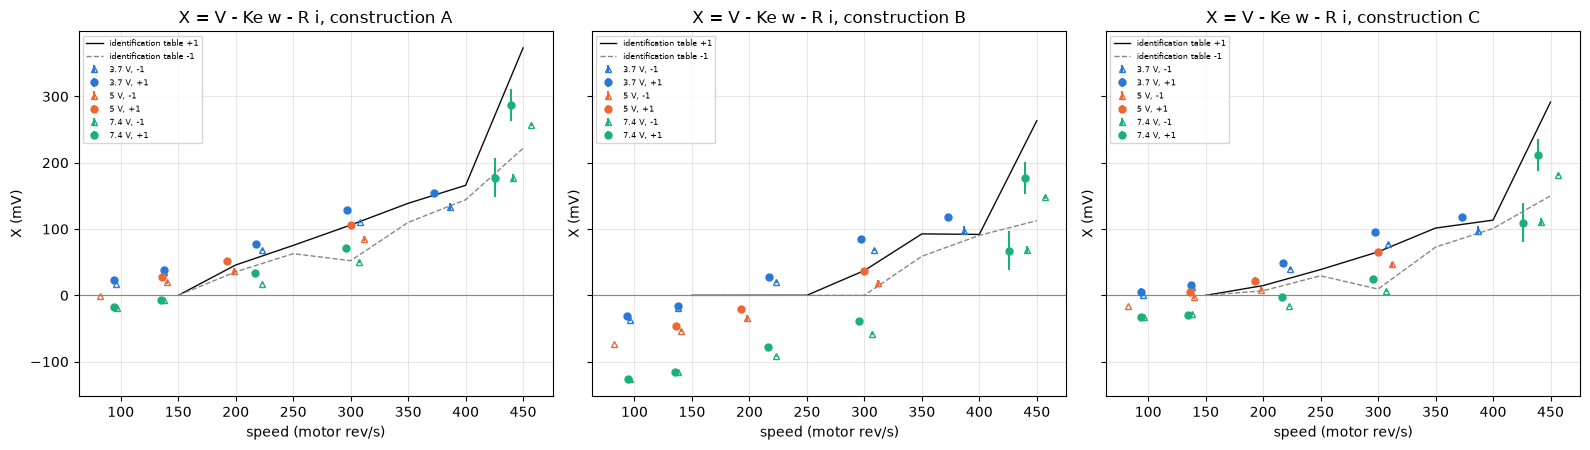

In [58]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.6), sharey=True)
for a, name in zip(ax, ("A", "B", "C")):
    for (v, d), h in AS_READ[name].groupby(["volts_set", "dir"]):
        style = {**figures.direction_style(d, RAIL_COLOR[v]), "ls": "none"}
        a.errorbar(h["rev_s"], h["x"], yerr=h["sd"], ms=5,
                   label=f"{v:g} V, {d:+d}", **style)
    for d, c in ((1, INK), (-1, MUTED)):
        a.plot(KNOTS_ID, ID_TABLES[name][d], ls="-" if d == 1 else "--",
               color=c, lw=1, label=f"identification table {d:+d}")
    a.axhline(0, color=MUTED, lw=0.8)
    figures.label(a, x="speed (motor rev/s)", y="X (mV)",
                  title=f"X = V - Ke w - R i, construction {name}")
    a.legend(fontsize=6)
figures.finish(fig)

Three things show before any term is fitted. At a matched speed $X$ falls with the rail under every construction. Under A it reads +17 to +38 mV at 94 to 138 rev/s on 3.7 V and -19 to -6 mV on 7.4 V, a split of -36 to -44 mV there, growing to -57 to -60 mV at 300 rev/s. Under B the split is -89 to -95 mV at 95 rev/s and grows to -124 to -125 at 300, and under C it is -33 to -39 mV growing to -70 to -71. A brush drop is never negative, so a negative $X$ says the construction leaves out something that reads the current high or the volts low at the higher rail. Within a rail $X$ rises with speed at 0.33 to 0.52 mV per rev/s as read up to 320 rev/s, 5 to 7 % of $K_e$, and at 0.37 to 0.77 with the top rungs in. At 3.7 V 100 %, where nothing switches and A, B and C agree, $X$ is +134 and +154 mV at 373 to 387 rev/s and 143 to 160 mA, inside the stage 2 takeaway's 100 to 300 mV at speed.

### The rail term

Over the settled spins with a valid tach, 82 to 223 rev/s on three rails, $X = c_0 + c_\mathrm{dir}\,[d = +1] + c_w\,\omega - g\,L$, with $L$ the lever of a crest over-read. Under A the lever is $R\,V_\mathrm{on}$, a crest term $g$ per volt of the window volts. Under B it is $R\,(1 - D)\,V_\mathrm{on}$, the crest term's form in the resistance notebook. The alternative is a constant crest offset, lever $R$ times one amp. $c_0$ is $X$ at zero speed, $c_w$ its speed slope and $c_\mathrm{dir}$ direction +1 over -1.

In [59]:
XT = SPINS[SPINS["set"].isin(LADDER_SETS) & TACH_OK].copy()
XT["settled"] = XT["settle_speed_pct"].abs() < SETTLE_PCT
base = KE * XT["spin_rev_s"]
XT["x_a"] = (XT["v_a_v"] - base - R_LOCKED * XT["i_crest_a"]) * 1e3
XT["x_b"] = (XT["v_b_v"] - base - R_LOCKED * XT["i_crest_a"]) * 1e3
XT["x_b_awake"] = (XT["v_b_v"] - base
                   - R_LOCKED * XT["i_crest_awake_a"]) * 1e3
XT["lever_a"] = R_LOCKED * XT["v_on_v"] * 1e3          # mV per S
XT["lever_b"] = (R_LOCKED * (1 - XT["duty_pct"] / 100)
                 * XT["v_on_v"] * 1e3)                 # mV per S
XT["lever_i"] = R_LOCKED * 1e3                          # mV per A
XT["dirpos"] = (XT["dir"] == 1).astype(float)


def fit_term(T, xcol, lever):
    # X = c0 + c_dir [dir +1] + c_w w + g x lever, se from the residual
    design = np.column_stack([np.ones(len(T)), T["dirpos"].to_numpy(),
                              T["spin_rev_s"].to_numpy(),
                              T[lever].to_numpy()])
    y = T[xcol].to_numpy()
    beta = np.linalg.lstsq(design, y, rcond=None)[0]
    res = y - design @ beta
    dof = len(y) - design.shape[1]
    cov = np.linalg.pinv(design.T @ design) * (res @ res / max(dof, 1))
    out = {"n": len(y), "rms_mv": float(np.sqrt((res ** 2).mean()))}
    for i, nm in enumerate(["c0_mv", "c_dir_mv", "c_w_mv_per_rev_s", "g"]):
        out[nm], out[nm + "_se"] = float(beta[i]), float(np.sqrt(cov[i, i]))
    return out

In [60]:
SETTLED_T = XT[XT["settled"]]
TERMS = {}
for xcol, lever, label in (("x_a", "lever_a", "A, g V_on"),
                           ("x_a", "lever_i", "A, constant"),
                           ("x_b", "lever_b", "B, g (1-D) V_on"),
                           ("x_b", "lever_a", "B, g V_on"),
                           ("x_b", "lever_i", "B, constant"),
                           ("x_b_awake", "lever_b",
                            "B awake zero, g (1-D) V_on")):
    TERMS[label] = fit_term(SETTLED_T, xcol, lever)
rows = []
for label, f in TERMS.items():
    scale = 1e3                         # S to mS, or A to mA
    rows.append({"fit": label, "n": f["n"], "g": -f["g"] * scale,
                 "g_se": f["g_se"] * scale, "c0_mv": f["c0_mv"],
                 "c_w": f["c_w_mv_per_rev_s"],
                 "c_w_se": f["c_w_mv_per_rev_s_se"],
                 "c_dir_mv": f["c_dir_mv"], "c_dir_se": f["c_dir_mv_se"],
                 "rms_mv": f["rms_mv"]})
show(pd.DataFrame(rows), n=None)
print("g in mS for a per-volt term, in mA for a constant offset")

,fit,n,g,g_se,c0_mv,c_w,c_w_se,c_dir_mv,c_dir_se,rms_mv
0,"A, g V_on",30,2.577,0.091,27.092,0.325,0.020,4.648,1.189,2.944
1,"A, constant",30,10.739,3.653,-0.000,0.433,0.111,4.125,6.740,16.688
2,"B, g (1-D) V_on",30,6.138,0.095,20.711,0.109,0.022,3.166,1.245,3.083
3,"B, g V_on",30,6.097,0.097,26.646,0.330,0.021,3.731,1.267,3.137
4,"B, constant",30,34.285,8.534,-0.000,0.586,0.259,2.493,15.748,38.992
5,"B awake zero, g (1-D) V_on",30,4.541,0.113,-15.258,0.198,0.026,2.565,1.480,3.663


g in mS for a per-volt term, in mA for a constant offset


A per-volt crest term fits the settled spins to 3 mV rms under either construction, 2.58 +/- 0.09 mS of $V_\mathrm{on}$ under A and 6.14 +/- 0.10 mS of $(1 - D)\,V_\mathrm{on}$ under B. A constant crest offset leaves 17 mV rms under A and 39 mV under B. The three rails separate the two forms, and the per-volt form wins by 6 to 13 times in residual, high confidence. With the awake-zero current under B the term is 4.54 mS.

The term's size depends on the construction. The board terms lower the applied volts more at the higher rail. The edge lags alone take 1.00 % of the period at 3.7 V and 1.12 % at 7.4 V, and the crest term then has to make that up. Against the resistance notebook's numbers, quoted below, this ladder under B asks for about twice the term the sag slope asked for, and under A for 0.8 of it.

In [61]:
b_term = -TERMS["B, g (1-D) V_on"]["g"] * 1e3        # mS
a_term = -TERMS["A, g V_on"]["g"] * 1e3
RATIO_B = (b_term / (G_SAG_SLOPE_S * 1e3),
           b_term / G_SAG["hi"], b_term / G_SAG["lo"])
print(f"resistance notebook, quoted: the sag slope asks {G_SAG['value']:.2f}"
      f" mS ({G_SAG['lo']:.2f} to {G_SAG['hi']:.2f}) under B; the user's "
      f"pass under the board terms R {R_STOP_EDGE_BRAKE:.4f} ohm, V0 "
      f"{V0_STOP_EDGE_BRAKE:+.4f} V")
print(f"this ladder under B over the sag slope's term: {RATIO_B[0]:.2f} "
      f"({RATIO_B[1]:.2f} to {RATIO_B[2]:.2f}); under A "
      f"{a_term / G_SAG['value']:.2f}")
print(f"type {TYPE_KEY}: spinning G {G_SPIN_TYPE_S * 1e3:.2f} mS, locked "
      f"{G_LOCKED_TYPE_MS:.2f} mS")
on3, off3, _, _ = edge_lags(3.7)
on7, off7, _, _ = edge_lags(7.4)
print(f"edge lags' share of the period, ON - OFF: 3.7 V "
      f"{(on3 - off3) / 2400 * 100:.2f} %, 7.4 V "
      f"{(on7 - off7) / 2400 * 100:.2f} %")

resistance notebook, quoted: the sag slope asks 3.22 mS (2.73 to 3.71) under B; the user's pass under the board terms R 4.2647 ohm, V0 -0.0705 V
this ladder under B over the sag slope's term: 1.91 (1.66 to 2.25); under A 0.80
type mg90-b: spinning G 3.35 mS, locked 2.49 mS
edge lags' share of the period, ON - OFF: 3.7 V 1.00 %, 7.4 V 1.12 %


### The tables with the rail term out

$X$ with the fitted term out, per rung and direction over every spin with a valid tach, interpolated to the knots 150 to 500 rev/s per direction. No knot past the top rung is kept, and the 400 and 450 rev/s knots rest on run-up spins, 450 on the two rungs with dropouts.

In [62]:
RAIL_FREE = {}
for xcol, lever, tag in (("x_a", "lever_a", "A - g V_on"),
                         ("x_b", "lever_b", "B - g (1-D) V_on"),
                         ("x_a", "lever_i", "A - const i"),
                         ("x_b", "lever_i", "B - const i")):
    g = fit_term(SETTLED_T, xcol, lever)["g"]
    term_out = XT.assign(xr=XT[xcol] - g * XT[lever])
    rm = term_out.groupby(["volts_set", "duty_pct", "dir"]).agg(
        rev_s=("spin_rev_s", "mean"), x=("xr", "mean"), sd=("xr", "std"),
        n=("k", "size"), settled=("settled", "all")).reset_index()
    tab = {}
    for d, h in rm.groupby("dir"):
        s = h.sort_values("rev_s")
        t = np.interp(KNOTS, s["rev_s"], s["x"])
        t[KNOTS > s["rev_s"].max() + 25] = np.nan   # past the top rung
        tab[d] = t
    RAIL_FREE[tag] = (rm, tab, g)
type_at = {d: np.array([VB_TYPE[d][f"{k:.0f} rev/s"]["value"]
                        for k in KNOTS]) for d in ("+1", "-1")}
knot_table = pd.DataFrame({"knot_rev_s": KNOTS})
for tag in ("A - g V_on", "B - g (1-D) V_on"):
    for d in (1, -1):
        knot_table[f"{tag} {d:+d}"] = RAIL_FREE[tag][1][d]
for d in ("+1", "-1"):
    knot_table[f"type {d}"] = type_at[d]
show(knot_table, n=None)

,knot_rev_s,A - g V_on +1,A - g V_on -1,B - g (1-D) V_on +1,B - g (1-D) V_on -1,type +1,type -1
0,150.000,82.985,75.482,43.557,36.446,0.000,0.000
1,200.000,106.762,90.433,54.570,41.271,12.487,4.408
2,250.000,130.762,114.576,68.534,56.109,13.521,5.805
3,300.000,158.767,127.773,87.572,55.245,19.474,12.396
4,350.000,181.740,155.546,108.337,83.501,25.763,20.922
5,400.000,236.533,192.533,141.553,108.822,32.314,28.344
6,450.000,405.699,299.719,277.890,179.705,38.864,35.766
7,500.000,NaN,NaN,NaN,NaN,52.515,43.188


In [63]:
at300 = knot_table[knot_table["knot_rev_s"] == 300].iloc[0]
for tag in ("A - g V_on", "B - g (1-D) V_on"):
    for d in ("+1", "-1"):
        print(f"{tag} {d} at 300 rev/s: {at300[f'{tag} {d}']:.1f} mV, "
              f"{at300[f'{tag} {d}'] / at300[f'type {d}']:.1f} x the "
              f"type's {at300[f'type {d}']:.1f}")
for tag in ("A - g V_on", "B - g (1-D) V_on"):
    rm = RAIL_FREE[tag][0]
    low = rm[rm["rev_s"] < LOW_SPEED]["x"]
    print(f"{tag}: rungs under {LOW_SPEED:.0f} rev/s {low.min():.0f} to "
          f"{low.max():.0f} mV; within-rung sd on settled rungs "
          f"{rm[rm['settled']]['sd'].min():.0f} to "
          f"{rm[rm['settled']]['sd'].max():.0f} mV")

A - g V_on +1 at 300 rev/s: 158.8 mV, 8.2 x the type's 19.5
A - g V_on -1 at 300 rev/s: 127.8 mV, 10.3 x the type's 12.4
B - g (1-D) V_on +1 at 300 rev/s: 87.6 mV, 4.5 x the type's 19.5
B - g (1-D) V_on -1 at 300 rev/s: 55.2 mV, 4.5 x the type's 12.4
A - g V_on: rungs under 160 rev/s 53 to 81 mV; within-rung sd on settled rungs 1 to 4 mV
B - g (1-D) V_on: rungs under 160 rev/s 28 to 43 mV; within-rung sd on settled rungs 1 to 4 mV


$X$ with the rail term out under A and under B, by rail and direction, open markers for unsettled rungs, with the knot tables and the type's direction +1 table, and the crest and settled-equivalent current against the speed with the type's bare drag curve. The thing to see is how far above the type's table both constructions sit, and how much the construction moves the slope.

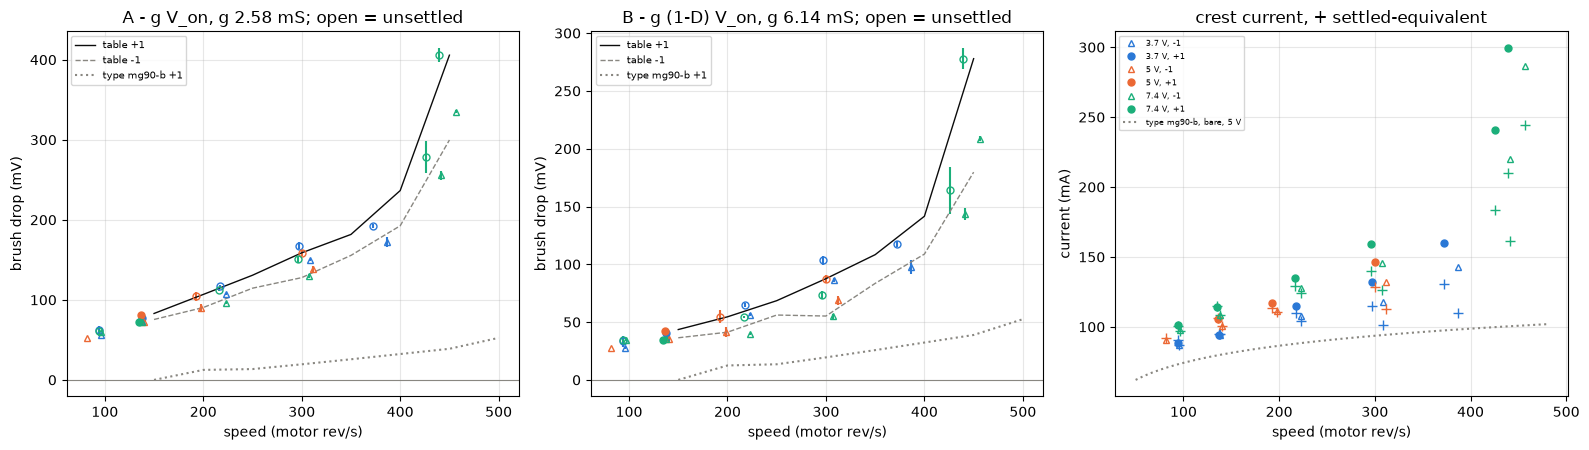

In [64]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
for a, tag in zip(ax, ("A - g V_on", "B - g (1-D) V_on")):
    rm, tab, g = RAIL_FREE[tag]
    for (v, d), h in rm.groupby(["volts_set", "dir"]):
        style = {**figures.direction_style(d, RAIL_COLOR[v]), "ls": "none"}
        for keep, fill in ((h["settled"], {}), (~h["settled"],
                                                {"mfc": "none"})):
            a.errorbar(h[keep]["rev_s"], h[keep]["x"], yerr=h[keep]["sd"],
                       ms=5, **{**style, **fill})
    for d, c in ((1, INK), (-1, MUTED)):
        a.plot(KNOTS, tab[d], ls="-" if d == 1 else "--", color=c, lw=1,
               label=f"table {d:+d}")
    a.plot(KNOTS, type_at["+1"], ls=":", color=MUTED,
           label=f"type {TYPE_KEY} +1")
    a.axhline(0, color=MUTED, lw=0.8)
    a.legend(fontsize=7)
    figures.label(a, x="speed (motor rev/s)", y="brush drop (mV)",
                  title=f"{tag}, g {-g * 1e3:.2f} mS; open = unsettled")
for (v, d), h in FRICTION.groupby(["volts_set", "dir"]):
    style = figures.direction_style(d, RAIL_COLOR[v])
    ax[2].plot(h["rev_s"], h["i_ma"], ms=5, label=f"{v:g} V, {d:+d}",
               **style)
    ax[2].plot(h["rev_s"], h["i_settled_ma"], ls="none", marker="+", ms=7,
               color=RAIL_COLOR[v])
ax[2].plot(w, (a5 + b5 * np.log(w / 100)) * 1e3, ls=":", color=MUTED,
           label=f"type {TYPE_KEY}, bare, 5 V")
ax[2].legend(fontsize=6)
figures.label(ax[2], x="speed (motor rev/s)", y="current (mA)",
              title="crest current, + settled-equivalent")
figures.finish(fig)

### What the brush drop stands on

Under A, with 2.58 mS of $V_\mathrm{on}$ out, the table reads 83 and 76 mV at 150 rev/s rising to 237 and 193 mV at 400 rev/s, direction +1 and -1, close to a line of 27 + 0.33 $\omega$ mV. Under B, with 6.14 mS of $(1 - D)\,V_\mathrm{on}$ out, it reads 44 and 36 mV rising to 142 and 109 mV, close to 21 + 0.11 $\omega$ mV up to 300 rev/s and steeper above. Within a settled rung the sd is 1 to 4 mV, and at 7.4 V 60 and 67 % in direction +1, the dropout spins, 24 to 30 mV. The rungs under 160 rev/s read 53 to 81 mV under A and 28 to 43 mV under B with the term out, where identification's rule set the type's floor to zero. The rails agree there because the fit made them agree.

At 300 rev/s the table is 4.5 to 10.3 times the type's, the type reading 19.5 and 12.4 mV. Two live causes explain the size, and the data does not pick between them. The brushes are a fresh pair with their own film, and stage 2 saw 100 to 300 mV at speed across its sittings. The construction of the applied volts moves the table by a factor of two between A and B.

Between the two constructions, $X$ at 100 rev/s moves -55 mV at 3.7 V and -108 mV at 7.4 V from A to B. The fitted crest term doubles, and the brush drop's speed slope falls from 0.325 to 0.109 mV per rev/s, 4.5 % and 1.5 % of $K_e$, with a rail-flat floor of 27 and 21 mV. The direction term is 3 to 5 mV either way, 2.5 to 3.9 sigma, likely, with +1 the higher drop as on the type. Neither construction is settled. A's 2.6 mS is near the type's locked $G$, 2.49 mS, but leaves a brush drop proportional to speed at 4.5 % of $K_e$, which would mean a $K_e$ under drive 4.5 % over the coast's where stage 2's spin route saw 0.2 %. B's 6.1 mS is twice any crest term measured so far, but leaves a speed slope of 1.5 % of $K_e$, closer to a brush drop.

The resistance notebook read the same question on the locked laps and the stop chains. With both board terms the sag laps' flat rail slope asked for a crest term of 3.22 mS (2.73 to 3.71) of $(1 - D)\,V_\mathrm{on}$, the user's pass under the board terms read 4.265 ohm and $V_0$ -0.071 V, and its leading reading was the two board terms plus a crest term of about the type's spinning size, with the edge lags smaller on the motor as the alive alternative. This ladder's term under B is 1.91 times that, 1.66 to 2.25 over its bounds, which is open discrepancy 1 below. The resistance notebook's chains on three rails, captured after this sitting, confirm the crest term and kill the as-read construction and B without a term. Along their valley the term is 3.0 to 4.0 mS at edge lags of 11 to 19 ticks, under stage 1's 25, so this ladder's 6.14 mS under B with stage 1's lags is to be formed again with the smaller lags before the two are compared, and the brush table to read is B's with that term out.

The standings.

- Construction A, the commanded duty times the window volts. Leading, low to moderate, that the as-read crest current carries a per-volt term of 2.5 to 6 mS whose size is tied to the construction of the applied volts. Under A the term is 2.58 mS and the table is the larger, 83 to 237 mV over 150 to 400 rev/s.
- Construction B, with stage 1's edge-lag and brake-interval terms. Alive, that B's two board terms are smaller on a spinning motor than on the RL dummy, the edge lags' bounds reaching -4 ticks, or that they pair with a crest term twice the type's. Under B the term is 6.14 mS and the table 36 to 142 mV.

The kill test is a meter in series on this servo at 15 to 40 % on one rail, stage 2's meter route, or the resistance notebook's locked laps at 24 and 36 % on 3.7 and 7.4 V, since a locked rotor has no brush drop and no speed term. Confidence in the table as a brush drop is low under A and moderate under B, both only up to 350 rev/s, since every spin above that is a run-up. The firmware form $V_b(\omega, d)$ absorbs either, but a table read under A would hand the estimator a 4.5 % speed-proportional term that the coast's $K_e$ says is not EMF.

## The low holds

Per level, the holds that kept turning of six, the effective volts as rail times duty and as $D\,V_\mathrm{on}$, the window's valid share, the pot's and the EMF's speed, the crest current and the ripple tach.

In [65]:
LEVELS = HOLDS.groupby(["volts_set", "duty_pct"]).agg(
    v_eff=("v_eff_cmd_v", "mean"), v_tap=("v_eff_tap_v", "mean"),
    valid=("window_valid_share", "mean"), n=("kept_turning", "size"),
    n_turn=("kept_turning", "sum"),
    pot=("pot_rev_s", lambda s: s.abs().mean()),
    emf=("e_first_rev_s", "mean"), i_ma=("i_hold_a", ma),
    ripple=("ripple_rev_s", "mean")).reset_index().sort_values(
        ["volts_set", "duty_pct"], ascending=[True, False])
show(LEVELS, n=None)
agree = HOLDS[HOLDS["kept_turning"]]
print(f"turning holds with a ripple count: "
      f"{int(agree['ripple_rev_s'].notna().sum())} of {len(agree)}; "
      f"stopped holds with one: "
      f"{int(HOLDS[~HOLDS['kept_turning']]['ripple_rev_s'].ge(1).sum())}")
valid = LEVELS[LEVELS["valid"] > 0.99]
print(f"{len(valid)} of {len(LEVELS)} levels with valid windows; there D x "
      f"V_on over rail x duty {(valid['v_tap'] / valid['v_eff']).min():.3f}"
      f" to {(valid['v_tap'] / valid['v_eff']).max():.3f}")

,volts_set,duty_pct,v_eff,v_tap,valid,n,n_turn,pot,emf,i_ma,ripple
5,3.700,16.000,0.590,0.580,1.000,6,6,39.356,37.058,65.918,41.092
4,3.700,14.000,0.516,0.508,1.000,6,6,32.844,34.946,61.303,34.057
3,3.700,11.000,0.406,0.400,1.000,6,6,22.988,25.569,53.881,23.393
2,3.700,8.000,0.295,0.290,1.000,6,1,2.357,1.282,64.961,12.842
1,3.700,7.000,0.258,0.254,1.000,6,0,0.019,-1.140,58.786,NaN
0,3.700,5.000,0.184,0.089,0.000,6,0,0.003,-0.570,42.997,NaN
11,5.000,12.000,0.599,0.590,1.000,6,6,40.937,42.772,68.808,41.996
10,5.000,10.000,0.498,0.492,1.000,6,6,30.242,30.657,63.761,31.659
9,5.000,8.000,0.399,0.394,1.000,6,6,19.964,22.012,60.003,20.356
8,5.000,6.000,0.300,0.272,1.000,6,0,0.005,-0.656,71.594,NaN


turning holds with a ripple count: 54 of 54; stopped holds with one: 0
11 of 17 levels with valid windows; there D x V_on over rail x duty 0.906 to 0.988


A stopped hold reads the pot flat to 0.02 rev/s and the EMF at -0.2 to -1.2 rev/s, which is the open bridge's tap zero, 1 to 2 counts, the same offset the $K_e$ zero met. Where the window is valid a stopped hold draws $V_\mathrm{eff}$ over 4.2 to 4.4 ohm, 58.8 mA at 0.258 V and 71.6 mA at 0.300 V, the locked $R$ plus a small $V_0$. Every hold that kept turning by the pot and the EMF also gave a ripple count, and no stopped hold gave one.

### The floor per rail and pooled

Per rail, the bracket between the highest level that never turned and the lowest that always turned, the mixed levels, and the line of the pot's speed on the effective volts over the turning holds.

In [66]:
floor_rows = []
for v, g in HOLDS.groupby("volts_set"):
    per = g.groupby("duty_pct").agg(v_eff=("v_eff_cmd_v", "mean"),
                                    n=("kept_turning", "size"),
                                    n_turn=("kept_turning", "sum"))
    mixed = per[(per["n_turn"] > 0) & (per["n_turn"] < per["n"])]
    turned = g[g["kept_turning"]]
    fit = fit_line(turned["v_eff_cmd_v"], turned["pot_rev_s"].abs())
    floor_rows.append({
        "volts_set": v, "holds": len(g), "turned": len(turned),
        "floor_lo_v": per[per["n_turn"] == 0]["v_eff"].max(),
        "floor_hi_v": per[per["n_turn"] == per["n"]]["v_eff"].min(),
        "mixed_levels": ";".join(f"{r.v_eff:.3f}V {int(r.n_turn)}/"
                                 f"{int(r.n)}" for r in mixed.itertuples()),
        "slope_rev_s_per_v": fit["slope"],
        "zero_v": -fit["intercept"] / fit["slope"]})
FLOOR = pd.DataFrame(floor_rows)
show(FLOOR, n=None)

,volts_set,holds,turned,floor_lo_v,floor_hi_v,mixed_levels,slope_rev_s_per_v,zero_v
0,3.700,36,19,0.258,0.406,0.295V 1/6,87.398,0.141
1,5.000,36,18,0.300,0.399,,104.863,0.209
2,7.400,30,17,0.296,0.517,0.369V 5/6,108.460,0.220


Pooled over the three rails, a logistic in the effective volts through every hold, its 50 % point the floor, and a bootstrap of 300 resamples of the 102 holds for its spread. The bootstrap is seeded, so the band repeats.

In [67]:
x_v = HOLDS["v_eff_cmd_v"].to_numpy()
y_turn = HOLDS["kept_turning"].to_numpy(float)


def nll(p, x=x_v, y=y_turn):
    # the logistic's negative log likelihood, midpoint p[0], scale p[1]
    z = (x - p[0]) / max(p[1], 1e-3)
    pr = np.clip(1 / (1 + np.exp(-z)), 1e-6, 1 - 1e-6)
    return -(y * np.log(pr) + (1 - y) * np.log(1 - pr)).sum()


LOGISTIC = minimize(nll, [0.33, 0.02], method="Nelder-Mead").x
rng = np.random.default_rng(0)
mids = []
for _ in range(300):
    idx = rng.integers(0, len(x_v), len(x_v))
    mids.append(minimize(nll, LOGISTIC, args=(x_v[idx], y_turn[idx]),
                         method="Nelder-Mead").x[0])
MIDS = np.array(mids)
per = HOLDS.groupby(["volts_set", "duty_pct"]).agg(
    v=("v_eff_cmd_v", "mean"), n=("kept_turning", "size"),
    t=("kept_turning", "sum")).reset_index()
NEVER_V = per[per["t"] == 0]["v"].max()        # highest that never turned
ALWAYS_V = per[per["t"] == per["n"]]["v"].min()   # lowest always turned
FLOOR_V = float(np.clip(LOGISTIC[0], NEVER_V, ALWAYS_V))
print(f"floor {FLOOR_V:.3f} V effective ({NEVER_V:.3f} to {ALWAYS_V:.3f}); "
      f"logistic scale {LOGISTIC[1]:.4f} V, bootstrap 68 % "
      f"{np.percentile(MIDS, 16):.3f} to {np.percentile(MIDS, 84):.3f}")
print(f"pot-table's crawl duty on 5 V: round(100 x {FLOOR_V:.3f} / 5.0) = "
      f"{round(100 * FLOOR_V / 5.0)} %")

floor 0.340 V effective (0.300 to 0.399); logistic scale 0.0146 V, bootstrap 68 % 0.322 to 0.363
pot-table's crawl duty on 5 V: round(100 x 0.340 / 5.0) = 7 %


The three rails' brackets are 0.258 to 0.406 V on 3.7 V, with 0.295 V mixed at 1 of 6, 0.300 to 0.399 V on 5 V, and 0.296 to 0.517 V on 7.4 V, with 0.369 V mixed at 5 of 6. They overlap on 0.300 to 0.399 V, and the two mixed levels sit inside it, so the floor is rail-independent within the levels' spacing of about 0.1 V, likely. A finer rail dependence is under the resolution. The logistic puts the floor at 0.340 V effective, with a bootstrap band of 0.322 to 0.363 V and a scale of 0.015 V. The result key `floor_v_effective` carries 0.340 V with the never and always levels, 0.300 and 0.399 V, as its bounds. pot-table's plan then computes 7 % as its crawl duty on 5 V, which this data brackets as the mixed region, 6 % stopped 6 of 6 and 8 % turned 6 of 6 at 20 rev/s.

### The speed at the floor

The pot's speed over the turning holds at 0.37 to 0.41 V effective, the pooled speed line on the effective volts, and its zero.

In [68]:
turned = HOLDS[HOLDS["kept_turning"]]
at_floor = turned[turned["v_eff_cmd_v"] < 0.42]["pot_rev_s"].abs()
POOLED = fit_line(turned["v_eff_cmd_v"], turned["pot_rev_s"].abs())
emf_line = fit_line(turned["v_eff_cmd_v"], turned["e_first_rev_s"])
print(f"lowest turning levels: {at_floor.mean():.1f} sd {at_floor.std():.1f}"
      f" rev/s ({at_floor.min():.1f} to {at_floor.max():.1f}) over "
      f"{len(at_floor)} holds")
print(f"pooled pot speed on V_eff: {POOLED['slope']:.1f} +/- "
      f"{POOLED['slope_se']:.1f} rev/s per V, zero at "
      f"{-POOLED['intercept'] / POOLED['slope']:.3f} V, rms "
      f"{POOLED['rms']:.2f} rev/s; the EMF's zero at "
      f"{-emf_line['intercept'] / emf_line['slope']:.3f} V")
crawl_deg = np.array([2.0, 5.0])        # deg/s at the horn
print(f"a crawl of 2 to 5 deg/s at the horn is "
      f"{crawl_deg[0] * GEAR / 360:.1f} to {crawl_deg[1] * GEAR / 360:.1f} "
      f"motor rev/s; the floor's speed {at_floor.min():.0f} to "
      f"{at_floor.max():.0f} rev/s is {at_floor.min() * 360 / GEAR:.0f} to "
      f"{at_floor.max() * 360 / GEAR:.0f} deg/s at the horn")

lowest turning levels: 19.6 sd 4.0 rev/s (12.0 to 25.2) over 18 holds
pooled pot speed on V_eff: 99.6 +/- 3.2 rev/s per V, zero at 0.191 V, rms 2.01 rev/s; the EMF's zero at 0.165 V
a crawl of 2 to 5 deg/s at the horn is 1.7 to 4.3 motor rev/s; the floor's speed 12 to 25 rev/s is 14 to 29 deg/s at the horn


The floor speed is not small. The holds that kept turning at the lowest levels, 0.37 to 0.41 V effective, ran at 12 to 25 rev/s at the motor, 19.6 sd 4.0 rev/s, and under about 10 rev/s the rotor stops rather than crawls. The one 3.7 V 8 % hold that kept turning ran at 13 to 14 rev/s by the pot and the ripple tach. The speed line through the turning holds, 99.6 +/- 3.2 rev/s per volt with an rms of 2.0 rev/s, reaches zero speed at 0.19 V, well under the floor. So the rotor stops at 0.30 to 0.37 V while still turning at 10 to 15 rev/s, a stick threshold about 0.15 V effective over the line's zero. High confidence in both from the per-level counts.

For the camera crawl this means a crawl of 2 to 5 deg/s at the horn, 1.7 to 4.3 motor rev/s, is under this train's sustaining speed in open loop at every duty in this data. The pot-table crawl at the floor will run at about 12 to 25 rev/s at the motor, 14 to 29 deg/s at the horn, or stall. It will not run at 2 to 5 deg/s.

### The crawl against the sag

The holds at 0.50 to 0.52 V effective, three levels on three rails, against the sag's crawl at 0.48 V on 6.0 to 8.4 V.

In [69]:
near = HOLDS[(HOLDS["v_eff_cmd_v"] > 0.45) & (HOLDS["v_eff_cmd_v"] < 0.55)]
pot = near["pot_rev_s"].abs()
print(f"{len(near)} holds: pot {pot.mean():.1f} sd {pot.std():.1f} rev/s, "
      f"EMF {near['e_first_rev_s'].mean():.1f} sd "
      f"{near['e_first_rev_s'].std():.1f}, crest "
      f"{near['i_hold_a'].mean() * 1e3:.1f} sd "
      f"{near['i_hold_a'].std() * 1e3:.1f} mA, awake-zero current "
      f"{near['i_hold_awake_a'].mean() * 1e3:.1f} mA")
for v, g in near.groupby("volts_set"):
    print(f"  {v:g} V: {g['i_hold_a'].mean() * 1e3:.1f} mA, ripple "
          f"{g['ripple_rev_s'].mean():.1f} rev/s")
print(f"the sag: {SAG['crawl_speed_rev_s']['value']:.1f} rev/s, "
      f"{SAG['crawl_current_ma']['value']:.1f} mA at "
      f"{SAG['crawl_v_eff_v']['value']:.3f} V")
gap = turned["e_first_rev_s"] - turned["pot_rev_s"].abs()
print(f"EMF speed less the pot's over the turning holds: {gap.mean():+.2f} "
      f"sd {gap.std():.2f} rev/s")

18 holds: pot 31.8 sd 2.0 rev/s, EMF 32.1 sd 4.5, crest 66.1 sd 5.6 mA, awake-zero current 65.6 mA
  3.7 V: 61.3 mA, ripple 34.1 rev/s
  5 V: 63.8 mA, ripple 31.7 rev/s
  7.4 V: 73.4 mA, ripple 33.4 rev/s
the sag: 31.4 rev/s, 71.2 mA at 0.484 V
EMF speed less the pot's over the turning holds: +0.44 sd 3.98 rev/s


At 0.50 to 0.52 V effective the 18 holds read 31.8 sd 2.0 rev/s by the pot, 32.1 sd 4.5 by the EMF and 31.7 to 34.1 by the ripple tach, at a crest current of 66.1 sd 5.6 mA. The sag read 31.4 sd 2.8 rev/s and 71.2 mA at 0.48 V on 6.0 to 8.4 V. The speed agrees within 0.4 rev/s, high confidence that the crawl speed at 0.5 V effective does not depend on the rail from 3.7 to 8.4 V. The current is 5 mA lower here, the crest's rail term again, 61, 64 and 73 mA on 3.7, 5 and 7.4 V. The coast EMF 0.1 to 1 ms past the cut agrees with the pot over the turning holds to +0.4 sd 4.0 rev/s, so at a crawl the first millisecond of coast EMF is a usable speed check.

### The breakaway

The kick in direction +1, from rest at the guard, and the rows before the drive in each direction.

In [70]:
fwd = HOLDS[HOLDS["dir"] == 1]
print(f"direction +1: breakaway {fwd['break_ms'].mean():.1f} sd "
      f"{fwd['break_ms'].std():.1f} ms after the drive's first row, peak "
      f"current before it {fwd['i_break_peak_a'].mean() * 1e3:.0f} sd "
      f"{fwd['i_break_peak_a'].std() * 1e3:.0f} mA, n "
      f"{int(fwd['break_ms'].notna().sum())}")
print(f"kick V_eff {HOLDS['kick_v_eff_v'].mean():.3f} sd "
      f"{HOLDS['kick_v_eff_v'].std():.3f} V, stall current "
      f"{HOLDS['kick_v_eff_v'].mean() / R_LOCKED * 1e3:.0f} mA")
for d, g in HOLDS.groupby("dir"):
    print(f"{d:+d}: rows before the drive {g['pre_drive_rows'].min()} to "
          f"{g['pre_drive_rows'].max()}, entry counts up to "
          f"{g['entry_counts'].abs().max():.0f}, kick ends at "
          f"{g['kick_end_pot_rev_s'].abs().mean():.0f} rev/s")

direction +1: breakaway 9.4 sd 1.4 ms after the drive's first row, peak current before it 313 sd 15 mA, n 51
kick V_eff 1.450 sd 0.013 V, stall current 344 mA
-1: rows before the drive 0 to 9, entry counts up to 20, kick ends at 152 rev/s
+1: rows before the drive 1 to 9, entry counts up to 3, kick ends at 130 rev/s


Every kick at 1.45 V effective moved the rotor. In direction +1 the pot left its seat by 3 counts 9.4 sd 1.4 ms after the drive's first row, at a current peak of 313 sd 15 mA. The winding's rise to the stall current, 1.45 / 4.22 = 0.34 A, completes in about 1 ms, so the rotor sat near the stall current for about 9 ms before the pot saw 3 counts, which through 308:1 is about 1.3 motor revolutions of play and spin-up. It is not the breakaway instant itself. The kick ends at 130 rev/s in +1 and 152 in -1. The -1 stream opens with the shaft still moving, so its entry counts are reported and not read as a breakaway.

No duty was swept from rest, so the breakaway duty is bounded, not measured. It is over 0.300 V effective, since a rotor stopped under a 0.300 V hold never restarted within a second, and at or under 1.45 V, since every kick moved. A ladder of 300 ms pulses from rest at 0.3 to 1.0 V effective in 0.1 V steps, both directions, from three starts, would measure it.

The holds' speed by the pot and the EMF against the effective volts with the 1 rev/s threshold, the hold current against the effective volts, and the pot's speed per 100 ms bin down the hold in direction +1 by level. The thing to see is the gap between the slowest turning hold and zero, and that a hold either settles at its speed within 300 ms or stops.

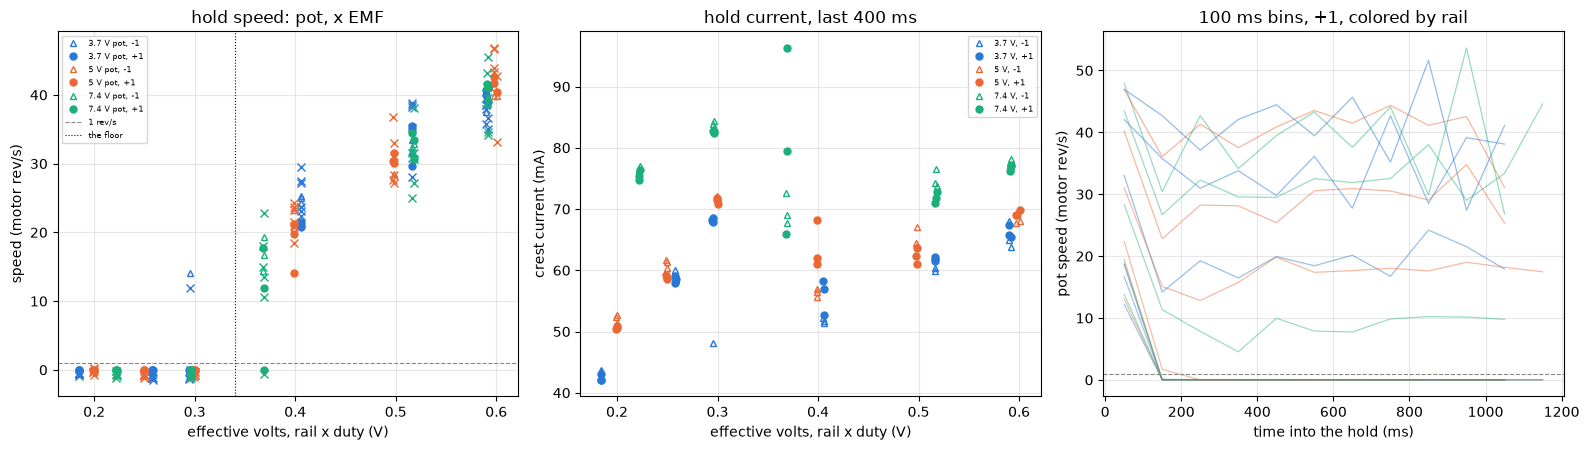

In [71]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.6))
for (v, d), h in HOLDS.groupby(["volts_set", "dir"]):
    style = figures.direction_style(d, RAIL_COLOR[v])
    ax[0].plot(h["v_eff_cmd_v"], h["pot_rev_s"].abs(), ms=5,
               label=f"{v:g} V pot, {d:+d}", **style)
    ax[0].plot(h["v_eff_cmd_v"], h["e_first_rev_s"], ls="none", marker="x",
               ms=6, color=RAIL_COLOR[v])
    ax[1].plot(h["v_eff_cmd_v"], h["i_hold_a"] * 1e3, ms=5,
               label=f"{v:g} V, {d:+d}", **style)
ax[0].axhline(TURN_REV_S, color=MUTED, ls="--", lw=0.8, label="1 rev/s")
ax[0].axvline(FLOOR_V, color=INK, ls=":", lw=0.8, label="the floor")
for (v, du), h in HOLD_BINS[HOLD_BINS["dir"] == 1].groupby(
        ["volts_set", "duty_pct"]):
    mean = h.groupby("t_ms")["rev_s"].mean()
    ax[2].plot(mean.index, mean.abs(), lw=0.9, color=RAIL_COLOR[v],
               alpha=0.4 + 0.1 * (du / 16))
ax[2].axhline(TURN_REV_S, color=MUTED, ls="--", lw=0.8)
figures.label(ax[0], x="effective volts, rail x duty (V)",
              y="speed (motor rev/s)", title="hold speed: pot, x EMF")
figures.label(ax[1], x="effective volts, rail x duty (V)",
              y="crest current (mA)", title="hold current, last 400 ms")
figures.label(ax[2], x="time into the hold (ms)",
              y="pot speed (motor rev/s)",
              title="100 ms bins, +1, colored by rail")
ax[0].legend(fontsize=6)
ax[1].legend(fontsize=6)
figures.finish(fig)

No hold that stopped restarted inside its 1.2 s, and no hold that was turning at 200 ms stopped later. The bins reach the hold's speed within the first 100 to 200 ms. The turning holds then scatter about their speed by the pot's bin noise, and the stopped holds sit at zero from the 150 ms bin on. The currents at the six invalid levels are not numbers, and the plot shows them only as what the samples read.

## The top rungs

The rail plan's 3.7 V 80 and 100 % and 7.4 V 67 %, three cycles each.

In [72]:
top = STEADY[STEADY["set"] == "rail-1"].merge(
    KE_RUNG[["set", "volts_set", "duty_pct", "dir", "ke"]],
    on=["set", "volts_set", "duty_pct", "dir"])
show(top[["volts_set", "duty_pct", "dir", "window_ms", "speed", "settle_pct",
          "accel_share", "i_ma", "v_a", "v_b", "dropouts", "ke"]], n=None)

,volts_set,duty_pct,dir,window_ms,speed,settle_pct,accel_share,i_ma,v_a,v_b,dropouts,ke
0,3.700,80.000,-1,78.400,308.393,16.233,0.163,117.858,2.854,2.811,0.000,7.315
1,3.700,80.000,1,78.433,297.151,14.601,0.143,131.782,2.849,2.805,0.000,7.322
2,3.700,100.000,-1,52.883,386.508,18.990,0.301,142.544,3.550,3.514,0.000,7.310
3,3.700,100.000,1,52.850,372.656,14.626,0.225,159.961,3.542,3.507,0.000,7.320
4,7.400,67.000,-1,26.450,456.915,4.502,0.173,286.262,4.793,4.683,0.000,7.283
5,7.400,67.000,1,26.417,439.388,13.674,0.428,299.483,4.791,4.680,50.505,7.270


All three are run-ups, settling +4.5 to +19 % across windows of 26 to 78 ms, the 7.4 V 67 % rung in direction -1 the lowest, with acceleration shares of 0.14 to 0.43, so they give no steady speed. They give $K_e$ inside the pooled band, the 100 % voltage balance with nothing switching, $X$ +134 and +154 mV at 373 to 387 rev/s, and the top of the brush table, the 7.4 V 67 % rung, where direction +1 dropped out at 38 to 76 rows per second. Their end-of-window speeds, 373 to 387 rev/s at 3.7 V 100 % and 439 to 457 at 7.4 V 67 % on 4.68 to 4.79 V applied, are the run-up notebook's cross-check.

## Results

The result file's quantities, $K_e$ and the coast first.

In [73]:
q = results.quantity
ke = GATED["ke_mv_per_rev_s"]
mean, sd = ke.mean(), ke.std()
OUT = {
    "ke_mv_per_rev_s": q(mean, mean - sd, mean + sd, "mV per rev/s, coast "
                         "route, rest tap zero, gated coasts, mean +/- sd"),
    "ke_v_s_per_rad": q(mean / (2 * np.pi) * 1e-3,
                        (mean - sd) / (2 * np.pi) * 1e-3,
                        (mean + sd) / (2 * np.pi) * 1e-3, "V s/rad"),
    "ke_se_pct": q(sd / np.sqrt(len(ke)) / mean * 100, unit="%"),
    "ke_sd_pct": q(sd / mean * 100, unit="%"),
    "ke_coasts_gated": q(len(GATED), unit="count"),
    "ke_coasts_total": q(len(SPINS), unit="count"),
    "ke_by_zero_mv_per_rev_s": {
        "rest, both directions alike": q(mean, unit="mV per rev/s"),
        "none": q(GATED["ke_nozero_mv_per_rev_s"].mean(),
                  unit="mV per rev/s"),
        "the coast's tail": q(GATED["ke_tailzero_mv_per_rev_s"].mean(),
                              unit="mV per rev/s")}}


def ke_by(col):
    # Ke mean +/- sd per value of `col` over the gated coasts
    return {g_key: q(g["ke_mv_per_rev_s"].mean(), g["ke_mv_per_rev_s"].mean()
                     - g["ke_mv_per_rev_s"].std(), g["ke_mv_per_rev_s"]
                     .mean() + g["ke_mv_per_rev_s"].std(), "mV per rev/s")
            for g_key, g in GATED.groupby(col)}


OUT["ke_by_direction_mv_per_rev_s"] = {
    f"{k:+d}": v for k, v in ke_by("dir").items()}
OUT["ke_by_level_mv_per_rev_s"] = {
    f"{k:g} V": v for k, v in ke_by("volts_set").items()}

In [74]:
for name, fit in TREND.items():
    OUT[f"ke_speed_trend_{name}_zero_pct_per_100_rev_s"] = results.pm(
        fit["slope"] * 100 / mean * 100, fit["slope_se"] * 100 / mean * 100,
        "% per 100 rev/s, se")
split, tail = RAIL_PAIRS["split_pct"], RAIL_PAIRS["split_tail_pct"]
OUT["ke_rail_split_matched_pct"] = q(
    split.mean(), split.mean() - split.std(), split.mean() + split.std(),
    "%, higher rail over lower less one at matched speed, rest zero; tail "
    "zero in ke_rail_split_tail_zero_pct")
OUT["ke_rail_split_tail_zero_pct"] = q(
    tail.mean(), tail.mean() - tail.std(), tail.mean() + tail.std(), "%")
OUT["ke_over_sag_pct"] = q((mean / KE_SAG - 1) * 100, unit="%")
OUT["ke_over_type_pct"] = q((mean / KE_TYPE["value"] - 1) * 100, unit="%")
OUT["ke_gate_decel_frac_max"] = q(
    DECEL_FRAC_MAX, unit="share of the window's speed lost across it")
for key, col, unit in (
        ("e0_over_ke_tach", "e0_over_tach", "ratio, E0 at the cut over Ke "
         "x the drive tach's last 20 ms, mean +/- sd"),
        ("coast_window_speed_over_tach", "win_speed_over_tach", "ratio, "
         "the 10 ms window's speed over the tach at the cut"),
        ("cut_speed_over_tach", "cut_speed_over_tach", "ratio, E0 over the"
         " window EMF times the window speed, over the tach")):
    x = GATED[col]
    OUT[key] = q(x.mean(), x.mean() - x.std(), x.mean() + x.std(), unit)
rp = SPINS["ripple_over_pot"]
OUT["ripple_over_pot"] = q(rp.mean(), rp.mean() - rp.std(),
                           rp.mean() + rp.std(), "ratio, drive tach over "
                           "the pot slope through the nominal pot slope "
                           "and the gear")
OUT["coast_stop_ms"] = results.median_range(GATED["stop_ms"], "ms")
OUT["ke_walk_by_band_mv_per_rev_s"] = {
    f"{int(r.band)}-{int(r.band) + 50} rev/s": q(
        r.ke, r.ke - r.sd, r.ke + r.sd, "mV per rev/s")
    for r in WALK_BANDS.itertuples() if r.band >= 50}

The rungs, the zero and the crest's rail term.

In [75]:
def rung_entry(g):
    # one rung-direction's steady numbers, mean +/- sd over its cycles
    m = results.mean_sd
    return {"speed_rev_s": m(g["spin_rev_s"], "rev/s"),
            "settle_pct": q(g["settle_speed_pct"].mean(), unit="%, window "
                            "over the previous window less one"),
            "i_crest_ma": m(g["i_crest_a"], "mA", 1e3),
            "i_settled_equiv_ma": m(g["i_settled_a"], "mA", 1e3),
            "i_crest_awake_zero_ma": m(g["i_crest_awake_a"], "mA", 1e3),
            "v_a_v": m(g["v_a_v"], "V"), "v_b_v": m(g["v_b_v"], "V"),
            "dropouts_per_s": m(g["dropouts_per_s"], "1/s"),
            "ke_mv_per_rev_s": m(g["ke_mv_per_rev_s"], "mV per rev/s")}


OUT["rungs"] = {f"{v:g} V {du:.0f} % {d:+d}": rung_entry(g)
                for (v, du, d), g in CAP.groupby(
                    ["volts_set", "duty_pct", "dir"])}
all_rungs = SPINS[SPINS["set"].isin(LADDER_SETS)].groupby(
    ["volts_set", "duty_pct", "dir"]).ngroups
OUT["rungs_settled_within_2p5pct"] = q(
    n_settled, unit=f"of {all_rungs} rung-directions")
OUT["speed_on_v_eff_settled"] = {
    key: {"slope": results.line_q(f, "slope", "rev/s per V of D x V_on"),
          "intercept": results.line_q(f, "intercept", "rev/s"),
          "rms": q(f["rms"], unit="rev/s")}
    for key, f in SPEED_ON_V.items()}
OUT["zero_awake_step_counts_by_level"] = {
    f"{v:g} V": q(r["mean"], r["mean"] - r["std"], r["mean"] + r["std"],
                  "counts over the rest zero, coast tail")
    for v, r in AWAKE.iterrows()}
OUT["zero_awake_step_per_v_counts"] = results.line_q(AWAKE_FIT, "slope",
                                                     "counts/V")
OUT["zero_awake_step_intercept_counts"] = results.line_q(
    AWAKE_FIT, "intercept", "counts")
OUT["trough_over_rest_zero_counts_by_level"] = {
    f"{v:g} V": q(x, unit="counts, slow-decay trough at duty <= 30 %")
    for v, x in TROUGH.items()}
OUT["crest_current_on_rail_at_137_rev_s_ma_per_v"] = results.line_q(
    CREST_ON_RAIL, "slope", "mA/V, settled rungs")

The brackets and the dropouts.

In [76]:
NAMES = {"speed_1": "bracket_speed_open_to_close_sitting1_pct",
         "current_1": "bracket_current_open_to_close_sitting1_ma",
         "speed_6_over_1": "bracket_speed_sitting6_over_sitting1_close_pct",
         "current_6_over_1":
             "bracket_current_sitting6_over_sitting1_close_ma",
         "speed_6": "bracket_speed_sitting6_open_to_close_pct",
         "ke_1": "bracket_ke_open_to_close_sitting1_pct"}
for d in (1, -1):
    for key, name in NAMES.items():
        val, se = BRACKET[d][key]
        unit = "mA, se" if name.endswith("_ma") else "%, se"
        OUT[f"{name}_{d:+d}"] = results.pm(val, se, unit)
REF_SPEED = 140                         # rev/s, the reference rung's speed
ref_sd = SPINS[SPINS["set"].str.startswith("ref")].groupby(
    ["set", "dir"])["spin_rev_s"].std().mean()
OUT["reference_rung_spin_sd_pct"] = q(
    ref_sd / REF_SPEED * 100, unit="%, speed sd within a bracket of 3 spins")
OUT["dropout_spins"] = q(len(drops), unit=f"of {len(CAP)} gated spins, all "
                         "7.4 V 60 and 67 % direction +1")
OUT["dropouts_per_s_max"] = q(CAP["dropouts_per_s"].max(), unit="1/s")
OUT["k_d_mv_per_dropout_s"] = {
    c: results.pm(K_D[c][0], K_D[c][1], "mV per dropout/s, se; 5 spins "
                  "carry dropouts, direction-confounded, a candidate only")
    for c in ("A", "B")}

The rail term and the brush drop, with the resistance notebook's numbers quoted.

In [77]:
for label, key in (("A, g V_on", "rail_term_a_g_ms"),
                   ("B, g (1-D) V_on", "rail_term_b_g_ms"),
                   ("B, g V_on", "rail_term_b_on_von_g_ms")):
    r = TERMS[label]
    OUT[key] = results.pm(-r["g"] * 1e3, r["g_se"] * 1e3, "mS, crest "
                          "over-read per volt of the lever that flattens X "
                          "across the rails; se")
    stem = key.replace("_g_ms", "")
    OUT[f"{stem}_rms_mv"] = q(r["rms_mv"], unit="mV, the fit's rms over "
                              "settled spins")
    OUT[f"{stem}_c0_mv"] = results.pm(r["c0_mv"], r["c0_mv_se"], "mV, X at "
                                      "zero speed with the term out")
    OUT[f"{stem}_c_w_mv_per_rev_s"] = results.pm(
        r["c_w_mv_per_rev_s"], r["c_w_mv_per_rev_s_se"],
        "mV per rev/s, X's speed slope with the term out")
    OUT[f"{stem}_c_dir_mv"] = results.pm(r["c_dir_mv"], r["c_dir_mv_se"],
                                         "mV, direction +1 over -1")
for label, key in (("A, constant", "rail_term_a_const_offset_ma"),
                   ("B, constant", "rail_term_b_const_offset_ma")):
    r = TERMS[label]
    OUT[key] = results.pm(-r["g"] * 1e3, r["g_se"] * 1e3, "mA, the constant"
                          " crest offset alternative; se")
    OUT[key.replace("_offset_ma", "_rms_mv")] = q(
        r["rms_mv"], unit="mV, its rms (the per-volt form's is "
        "rail_term_*_rms_mv)")

In [78]:
OUT["v_b_mv"] = {
    "knots": [float(k) for k in KNOTS],
    "tables": {tag: {f"{d:+d}": {
        f"{k:.0f} rev/s": q(x, unit="mV") if np.isfinite(x) else None
        for k, x in zip(KNOTS, RAIL_FREE[tag][1][d])} for d in (1, -1)}
        for tag in RAIL_FREE},
    "note": "X = V - Ke w - R i with the rail term out, rung means "
            "interpolated to the knots per direction; knots past the top "
            "rung are null; 400 and 450 rev/s rest on unsettled spins"}
OUT["v_b_type_mv_at_300_rev_s"] = {
    m: q(VB_TYPE[m]["300 rev/s"]["value"], unit="mV, mg90-b "
         "identification, comparison") for m in ("+1", "-1")}
OUT["r_locked_ohm_used"] = q(R_LOCKED, R_LOCKED_LO, R_LOCKED_HI, f"ohm, the"
                             f" resistance result's r_term at "
                             f"{R_LOCKED_AMPS:.3f} A, quoted")
OUT["r_stop_edge_brake_ohm_quoted"] = q(
    R_STOP_EDGE_BRAKE, unit="ohm, the resistance result's user's pass "
    "under the board terms, quoted")
OUT["v0_stop_edge_brake_v_quoted"] = q(V0_STOP_EDGE_BRAKE, unit="V, quoted")
OUT["sag_slope_g_needed_ms_quoted"] = q(
    G_SAG_SLOPE_S * 1e3, G_SAG["lo"] * 1e-3 * 1e3, G_SAG["hi"] * 1e-3 * 1e3,
    "mS, the resistance "
    "result's crest term under B, quoted; this ladder's rail_term_b_g_ms is"
    " the same quantity read here")
b_val = OUT["rail_term_b_g_ms"]["value"]
OUT["rail_term_b_over_sag_slope_g"] = q(
    b_val / (G_SAG_SLOPE_S * 1e3), b_val / (G_SAG["hi"] * 1e-3 * 1e3),
    b_val / (G_SAG["lo"] * 1e-3 * 1e3), "ratio")

The floor, the crawl and the kick.

In [79]:
OUT["floor_v_effective"] = q(
    FLOOR_V, float(NEVER_V), float(ALWAYS_V), "V effective (rail x duty) "
    "below which a kicked rotor stops turning within the 1.2 s hold; value "
    "the logistic 50 % point over 102 holds on three rails, bounds the "
    "highest level that never turned and the lowest that always turned, "
    "pooled over the rails")
OUT["floor_logistic_mid_v"] = q(
    LOGISTIC[0], float(np.percentile(MIDS, 16)),
    float(np.percentile(MIDS, 84)), "V, logistic 50 % point, bootstrap "
    "68 % band")
OUT["floor_logistic_width_v"] = q(LOGISTIC[1], unit="V, logistic scale")
OUT["floor_by_level"] = {
    f"{r.volts_set:g} V": {
        "never_turned_v": q(r.floor_lo_v, unit="V effective"),
        "always_turned_v": q(r.floor_hi_v, unit="V effective"),
        "mixed_levels": r.mixed_levels} for r in FLOOR.itertuples()}
OUT["floor_rail_independent_within_v"] = q(
    float(FLOOR["floor_hi_v"].max() - FLOOR["floor_lo_v"].min()),
    unit="V, the span of the three rails' brackets")
OUT["floor_speed_at_lowest_turning_level_rev_s"] = results.mean_sd(
    at_floor, "rev/s, pot slope, holds at 0.37 to 0.41 V effective that "
    "kept turning")
OUT["floor_pot_table_crawl_duty_pct"] = q(
    round(100 * OUT["floor_v_effective"]["value"] / 5.0), unit="%, round("
    "100 x floor_v_effective / 5.0), what pot-table/plan.py computes")
OUT["crawl_speed_on_v_eff_rev_s_per_v"] = results.line_q(
    POOLED, "slope", "rev/s per V effective, pooled turning holds, pot "
    "slope")
OUT["crawl_speed_zero_v"] = q(-POOLED["intercept"] / POOLED["slope"],
                              unit="V effective, the speed line's zero, "
                              "not the floor (hysteresis)")
OUT["crawl_speed_line_rms_rev_s"] = q(POOLED["rms"], unit="rev/s")

In [80]:
m = results.mean_sd
OUT["crawl_speed_rev_s"] = m(near["pot_rev_s"].abs(), "rev/s, holds at "
                             "0.50 to 0.52 V effective, pot slope; sag read"
                             " 31.4 at 0.48 V")
OUT["crawl_emf_speed_rev_s"] = m(near["e_first_rev_s"], "rev/s, the coast's"
                                 " EMF 0.1 to 1 ms past the cut over Ke")
OUT["crawl_current_ma"] = m(near["i_hold_a"], "mA, crest with the stage 1 "
                            "offset; sag read 71.2", 1e3)
OUT["crawl_current_awake_zero_ma"] = m(near["i_hold_awake_a"], "mA, crest "
                                       "over the coast tail's awake zero",
                                       1e3)
OUT["crawl_hold_n"] = q(len(HOLDS), unit="holds")
OUT["crawl_kept_turning_n"] = q(int(HOLDS["kept_turning"].sum()),
                                unit="holds")
OUT["crawl_emf_vs_pot_rev_s"] = m(gap, "rev/s, coast EMF speed less the "
                                  "pot's over the turning holds")
OUT["kick_breakaway_ms_fwd"] = m(fwd["break_ms"], "ms, first row 3 counts "
                                 "past the seat, direction +1 (the reverse "
                                 "stream opens with the shaft moving)")
OUT["kick_current_at_move_a"] = m(fwd["i_break_peak_a"], "A, the 5-row "
                                  "boxcar peak before the move")
OUT["kick_v_eff_v"] = m(HOLDS["kick_v_eff_v"], "V effective at the kick")
OUT["kick_end_speed_rev_s"] = {
    f"{d:+d}": m(g["kick_end_pot_rev_s"].abs(), "rev/s, pot over the "
                 "kick's last 50 ms") for d, g in HOLDS.groupby("dir")}
OUT["breakaway_v_effective_bounds"] = q(
    np.nan, float(NEVER_V), float(HOLDS["kick_v_eff_v"].mean()),
    "V effective: every kick at the hi bound moved; a rotor stopped under a"
    " hold at the lo bound never restarted; the duty was not swept from "
    "rest, no value")
n_valid = int((HOLDS.groupby(["volts_set", "duty_pct"])[
    "window_valid_share"].mean() > 0.99).sum())
OUT["low_hold_window_valid_levels"] = q(
    n_valid, unit="of 17 levels; the rest sit under the board's window "
    "floors, no current or tap number there")
print(len(OUT), "keys")

96 keys


### The result file

The notes that define every key. Report-only keys describe this sitting and set no firmware number. Candidate keys rest on one route or under 2 sigma. Construction-dependent keys change with the construction of the applied volts, A or B, and are open until the kill test in the brush drop section runs. The kill test ran as sitting 7, and the resistance notebook's rails section picks B with a per-volt crest term, so the B keys are the ones to carry and the A keys stay as the as-read record.

In [81]:
NOTES = (
    "stage 3 ladder of mg90-d on dev-v006-2A-D, horn free, DPS-150 over "
    "the feed diode, experiment image: ref-open-1, ref-close-1, ref-open-6 "
    "and ref-close-6 (three cycles of 30 % on 5 V at the open and close of "
    "sittings 1 and 6), capture-1 (15 to 60 % on 3.7, 5 and 7.4 V, three "
    "cycles a rung), rail-1 (3.7 V 80 and 100 %, 7.4 V 67 %) and low-1 (a "
    "150 ms kick at 1.45 V effective chained to a 1.2 s hold at 0.6 to 0.2 "
    "V effective, 17 levels, three cycles). A cycle is a spin from the near"
    " guard and a 400 ms coast with the bridge open, both directions, the "
    "spin window cut by the runway (53 ms at 7.4 V 67 %). Current through "
    "stage 1 current-scale over each sweep's torque-off zero with the "
    "in-drive offset out, the crest sample; volts through terminal-chain; "
    "the rail and board NTC from the manifest probe before each sweep (TEL "
    "rows carry neither). The spin window is the last 100 ms of the held "
    "duty, half the held rows at most, 20 ms at least; speed by the ripple "
    "tach (6 events per rev) seeded by the coast. Every number is mg90-d's "
    "own; mg90-b and mg90-c values are comparison only. "
    "ke_*: bemf-coast's coast route on the 108 of 132 coasts that pass the "
    "gate (speed lost across the 10 ms window <= ke_gate_decel_frac_max "
    "and >= 4 whole cycles; every coast under about 60 rev/s fails), rest "
    "tap zero, mean +/- sd; ke_se_pct and ke_sd_pct the pooled se and sd; "
    "ke_by_zero the open systematic (rest, none, the coast's tail zero); "
    "ke_by_direction and ke_by_level mean +/- sd, report only; "
    "ke_speed_trend_*_zero Ke's line on the window speed under each zero, "
    "se bounds, candidate (its sign follows the zero); ke_rail_split_* the "
    "higher rail over the lower less one over 24 rung pairs within 15 % in "
    "speed, mean +/- sd, report only; ke_over_sag_pct and ke_over_type_pct "
    "against the sag's 7.327 and mg90-b's 7.341; ke_walk_by_band 5 ms "
    "windows walked down the gated coasts by 50 rev/s band, mean +/- sd. "
    "e0_over_ke_tach E0 at the cut over this Ke times the drive tach's "
    "last 20 ms; coast_window_speed_over_tach the 10 ms window's speed "
    "over that tach; cut_speed_over_tach the window's line extrapolated to "
    "the cut, over the tach; ripple_over_pot the drive tach over the pot "
    "through its nominal slope, every spin; all mean +/- sd. coast_stop_ms "
    "the median and range of the gated coasts' time to the stop. "
)

In [82]:
NOTES += (
    "rungs: per rung and direction over the gated cycles of capture-1 and "
    "rail-1, mean +/- sd: speed by the tach, settle (window over the "
    "previous window less one; the top rungs are run-ups at +13 to +19 %), "
    "i_crest (construction A's current), i_settled_equiv (i / (1 + a_drive"
    " / a_coast), J-free, for the friction read only, candidate), "
    "i_crest_awake_zero (the crest over the coast tail's awake zero), v_a "
    "(D x V_on) and v_b (stage 1's edge lags interpolated on the rail and "
    "the brake interval through bridge-states' low-side loop), dropouts and"
    " Ke. rungs_settled_within_2p5pct the rung-directions holding a spin "
    "settled within 2.5 %; speed_on_v_eff_settled the tach speed's line on"
    " v_a per rail and direction over the settled spins, se bounds, report "
    "only. zero_awake_step_* the coast tail's last 100 ms over the "
    "torque-off zero, by rail mean +/- sd, its line on the rail, se bounds "
    "(high); trough_over_rest_zero_* the slow-decay trough at duty <= 30 %, "
    "report only. crest_current_on_rail_at_137_rev_s_ma_per_v the settled "
    "rungs' crest current at 130 to 145 rev/s on the rail, se bounds; a part"
    " may be run-in. bracket_*: the 5 V 30 % reference rung, "
    "close over open of sitting 1, sitting 6's open over sitting 1's close,"
    " and sitting 6's close over its open, in % of speed or mA of crest "
    "current, se bounds (the two blocks' sds in quadrature over root 3); "
    "bracket_ke_* under 1 sigma, not a finding; "
    "reference_rung_spin_sd_pct the speed sd within a bracket over 140 "
    "rev/s. dropout_spins and dropouts_per_s_max over the gated ladder "
    "spins, by the quarter rule; k_d_mv_per_dropout_s identification's "
    "dropout term on X under A and B, se bounds, candidate (five spins, one"
    " direction, confounded with the direction term). "
)

In [83]:
NOTES += (
    "rail_term_*: X = V - Ke w - R i (mV) over the 30 settled spins with a "
    "valid tach, fitted as c0 + c_dir [dir +1] + c_w w - g x lever, se "
    "bounds; rail_term_a_g_ms the crest over-read in mS of V_on under A, "
    "rail_term_b_g_ms in mS of (1 - D) V_on under B, rail_term_b_on_von "
    "the same with the V_on lever; *_rms_mv, *_c0_mv, *_c_w_mv_per_rev_s "
    "and *_c_dir_mv the fit's rms and other coefficients; "
    "rail_term_*_const_offset_ma the constant crest offset alternative with"
    " its rms, rejected (6 to 13 times the per-volt form's rms). Every "
    "rail_term_* key is construction-dependent. v_b_mv: the brush drop "
    "tables per direction at 150 to 500 rev/s, X with each fitted term out,"
    " rung means interpolated to the knots, null past the top rung, 400 and"
    " 450 rev/s on run-up spins; tables 'A - g V_on' and 'B - g (1-D) V_on'"
    " are the two constructions, construction-dependent, low confidence "
    "under A and moderate under B, up to 350 rev/s; the 'const i' tables "
    "are the rejected form, report only. v_b_type_mv_at_300_rev_s mg90-b's "
    "identification table, comparison. r_locked_ohm_used the resistance "
    "result's r_term at its current, the R in every X, quoted; "
    "r_stop_edge_brake_ohm_quoted, v0_stop_edge_brake_v_quoted and "
    "sag_slope_g_needed_ms_quoted the resistance result's user's pass "
    "under the board terms and the crest term its sag slope asked for, "
    "quoted; rail_term_b_over_sag_slope_g this ladder's construction B "
    "term over that one, bounds over the quoted term's bounds. "
)

In [84]:
NOTES += (
    "floor_v_effective: the effective volts, rail (manifest probe) x duty, "
    "under which a kicked rotor stops turning within the 1.2 s hold; value "
    "the logistic 50 % point over the 102 holds on three rails, lo the "
    "highest level where no hold turned, hi the lowest where every hold "
    "turned, pooled over the rails; one sitting, the servo's first two "
    "hours; a hold kept turning when both the pot slope over its last 400 "
    "ms and the coast EMF 0.1 to 1 ms past the cut (over the sag's Ke) read"
    " over 1 rev/s. pot-table/plan.py reads this key. floor_logistic_mid_v"
    " the same midpoint with a seeded 300-resample bootstrap's 68 % band, "
    "floor_logistic_width_v its scale; floor_by_level per rail the never "
    "and always levels and the mixed levels; "
    "floor_rail_independent_within_v the span of the three brackets; "
    "floor_speed_at_lowest_turning_level_rev_s the pot speed of the turning"
    " holds at 0.37 to 0.41 V, mean +/- sd; floor_pot_table_crawl_duty_pct"
    " what pot-table computes from the floor. crawl_speed_on_v_eff the pot "
    "speed's line on the effective volts over the turning holds, se bounds,"
    " crawl_speed_zero_v its zero (under the floor: the rotor stops while "
    "turning at 10 to 15 rev/s), crawl_speed_line_rms its rms. crawl_* "
    "speed and current over the 18 holds at 0.50 to 0.52 V effective, mean"
    " +/- sd; crawl_emf_vs_pot the coast EMF speed less the pot's over the "
    "turning holds. kick_*: direction +1 only (the -1 stream opens with the"
    " shaft moving), mean +/- sd; kick_end_speed_rev_s by direction. "
    "breakaway_v_effective_bounds no value, bounds only (no duty was swept "
    "from rest). low_hold_window_valid_levels the levels whose windows met "
    "the board's sampling floors; the rest carry no current or tap number."
)

The result file, then every key as written.

In [85]:
CAPTURE = ", ".join(str(results.rel(LADDER / name)) for name in SETS + [LOW])
path = results.write("3-servo", "ladder", CAPTURE, pair=PAIR, notes=NOTES,
                     **OUT)
written = results.read("3-servo", "ladder", pair=PAIR)
print("wrote", path, "with", len(OUT), "keys, capture", written["capture"])
flat = pd.DataFrame([{"key": k, **v} for k, v in written.items()
                     if isinstance(v, dict) and "value" in v])
show(flat, n=None)

wrote stages/3-servo/ladder/results/mg90-d__dev-v006-2A-D.json with 96 keys, capture telemetry/mg90-d__dev-v006-2A-D/ladder/ref-open-1, telemetry/mg90-d__dev-v006-2A-D/ladder/ref-close-1, telemetry/mg90-d__dev-v006-2A-D/ladder/capture-1, telemetry/mg90-d__dev-v006-2A-D/ladder/rail-1, telemetry/mg90-d__dev-v006-2A-D/ladder/ref-open-6, telemetry/mg90-d__dev-v006-2A-D/ladder/ref-close-6, telemetry/mg90-d__dev-v006-2A-D/ladder/low-1


,key,value,lo,hi,unit
0,ke_mv_per_rev_s,7.283,7.237,7.328,"mV per rev/s, coast route, rest tap zero, gate..."
1,ke_v_s_per_rad,0.001,0.001,0.001,V s/rad
2,ke_se_pct,0.060,NaN,NaN,%
3,ke_sd_pct,0.627,NaN,NaN,%
4,ke_coasts_gated,108.000,NaN,NaN,count
...,...,...,...,...,...
78,kick_breakaway_ms_fwd,9.361,7.994,10.727,"ms, first row 3 counts past the seat, directio..."
79,kick_current_at_move_a,0.313,0.298,0.329,"A, the 5-row boxcar peak before the move"
80,kick_v_eff_v,1.450,1.438,1.463,V effective at the kick
81,breakaway_v_effective_bounds,NaN,0.300,1.450,V effective: every kick at the hi bound moved;...


In [86]:
fv = written["floor_v_effective"]
print(f"floor_v_effective {fv['value']:.3f} ({fv['lo']:.3f} to "
      f"{fv['hi']:.3f}) {fv['unit'][:24]}...")
for key in ("rail_term_a_g_ms", "rail_term_b_g_ms"):
    r = written[key]
    print(f"{key}: {r['value']:.2f} ({r['lo']:.2f} to {r['hi']:.2f})")
tables = written["v_b_mv"]["tables"]
for tag in ("A - g V_on", "B - g (1-D) V_on"):
    print(f"{tag} at 300 rev/s: +1 "
          f"{tables[tag]['+1']['300 rev/s']['value']:.0f}, -1 "
          f"{tables[tag]['-1']['300 rev/s']['value']:.0f} mV")

floor_v_effective 0.340 (0.300 to 0.399) V effective (rail x duty...
rail_term_a_g_ms: 2.58 (2.49 to 2.67)
rail_term_b_g_ms: 6.14 (6.04 to 6.23)
A - g V_on at 300 rev/s: +1 159, -1 128 mV
B - g (1-D) V_on at 300 rev/s: +1 88, -1 55 mV


## Limitations

- One servo, one board, one sitting for the ladder and the holds, in the servo's first two hours on new brushes and fresh grease. The brackets show the run-in, +1.1 to +1.6 % in speed and -4.7 to -7.2 mA in current over sitting 1.
- The supply is the DPS-150, a stiff source trimmed at rest. The rail is the torque-off probe before each sweep, since the telemetry rows carry no `vbus_raw`.
- The coast route holds only from about 70 rev/s up on this geared rotor. Under that the rotor loses a third of its speed inside the window and the read fails.
- $K_e$'s zero is open to about a count of tap difference, 0.3 % of $K_e$.
- The runway cut the top rungs to 53 to 157 ms, so every spin over about 300 rev/s is a run-up and the brush drop above 350 rev/s rests on unsettled spins.
- No meter and no partial-duty locked lap ran on these rails, so the construction of the applied volts is not settled, and the brush table is given under A and B. The locked laps on three rails in the resistance notebook have since settled it for B with a crest term.
- Dropouts occurred in one direction at two rungs, so $k_d$ has almost no lever.
- At six of the seventeen low levels the window sits under the board's sampling floors, so the floor is read on rail times duty.
- The breakaway duty was not swept from rest, only bounded.
- The speeds through the pot rest on its nominal slope, 19.8 counts per degree, which pot-table grades.

## Open questions

1. The brush-drop residual at a matched speed falls with the rail under every construction, -50 mV from 3.7 to 7.4 V under A and -90 to -125 mV under B. Candidates are a per-volt crest over-read of 2.6 mS (A) or 6.1 mS (B) of the window volts, the type's reading term on this servo, leading, moderate on the form and low on the size, B's board terms smaller on a spinning motor than on the RL dummy, alive, and the run-in across the ladder's 55 minutes, bounded at about a tenth of the crest's rise from 3.7 to 7.4 V if it ran at an even rate. Under B the term is 1.91 times the 3.22 mS the resistance notebook's sag slope asked for. A meter in series on this servo at 15 to 40 % on one rail, or locked laps at 24 and 36 % on 3.7 and 7.4 V, separates them. The locked laps ran on three rails as sitting 7 and the resistance notebook reads them. The crest term is confirmed and B's board terms with smaller edge lags, 11 to 19 ticks, are the likely pairing, so the first candidate stands with its size tied to the lags.
2. With the rail term out, $X$ still rises with speed at 0.325 (A) or 0.109 (B) mV per rev/s, 4.5 or 1.5 % of $K_e$. Candidates are a brush drop that grows with speed, a $K_e$ under drive over the coast's, which stage 2's spin route puts within 0.2 %, and the construction's leftover, since the lever and the speed move together within a rail. The tests of 1 separate them, with a 3.7 V 100 % run-up, where nothing switches, read as $X$ against speed through the run-up.
3. The brush drop's size, 4.5 to 10.3 times the type's at 300 rev/s. Candidates are a fresh brush pair with its own film and the construction, A and B differing by two. The tests of 1 separate them, with the open and close brackets of later sittings for $X$'s drift at the reference rung.
4. $K_e$'s zero. The rest tap difference and the coast tail's differ by about a count and move the slow rungs by 0.4 %, the speed trend's sign and the rail split. Candidates are the tap bias settling after the seek, a tail signed by the direction, and the rest read before the sweep while the shaft rings down. A coast with a 1 s torque-off tail recorded beside the baseline at one rail, the tap difference compared row for row, separates them.
5. $K_e$ 0.6 % under the sag's and 0.8 % under the type's. Candidates are the zero, about 0.3 %, the sag's higher speeds, 170 to 250 rev/s, where this ladder reads 7.30 to 7.33, and motor spread, mg90-b and mg90-c differing by 0.3 %. The test of 4, and the sag's 30 % rungs on 6 to 8.4 V run back to back with the ladder's rungs in one sitting, separate them.
6. The reference rung ran in, +1.1 to +1.6 % in speed and -4.7 to -7.2 mA over sitting 1, and a further +1 to +2 % in speed by sitting 6. Candidates are the fresh grease spreading, the brushes bedding, with the dropouts at zero throughout, and the board warming, where the NTC fell 0.9 C through sitting 1, the wrong sign for a thermal $R$. The brackets of the next three sittings against time separate them.
7. The floor's speed. The rotor stops under about 10 rev/s rather than crawling, and the speed line's zero, 0.19 V, sits 0.15 V under the stick threshold of 0.30 to 0.37 V. Candidates are stick-slip in the train, the motor's cogging at 3 slots, and the pot's seat. The camera crawl at the floor -1 % to +4 % with 100 ms bins against the tag, and a duty ramped down 0.5 % per 200 ms during a turning hold to read the stopping speed directly, separate them.
8. $k_d$, +0.8 +/- 0.1 mV per dropout per second from five spins in one direction, confounded with the direction term. A sitting where both directions drop out separates it, and until then the type values stand.

The data does not settle which construction of the applied volts is the motor's, the brush drop above 350 rev/s, $k_d$, the breakaway duty, the floor finer than 0.1 V per rail, the coast $K_e$ under about 70 rev/s, $K_e$'s zero to better than a count, the steady current at the top rungs, how much of the crest's rail slope is run-in, or the horn speed of a 2 to 5 deg/s crawl, which open loop does not sustain here.

## Conclusion

mg90-d's motor reads $K_e$ = 7.283 mV per rev/s, sd 0.046, from the 108 of 132 coasts that pass the gate, 0.60 % under the sag's 7.327 and 0.79 % under the type's 7.341, likely a real 0.6 to 0.8 % with the zero, about 0.3 %, as the open systematic. It is flat down the coast within 0.3 % from 150 to 500 rev/s. The coast route holds from about 70 rev/s up on this geared rotor. The EMF at the cut agrees with the drive tach to 0.4 %, sd 2.8 %.

The sustaining floor is 0.340 V effective, 0.300 to 0.399 V, the same on the three rails within the levels' 0.1 V spacing. The rotor at the floor turns at 12 to 25 rev/s, and under about 10 rev/s it stops rather than crawls, so a camera crawl of a few degrees per second at the horn is out of reach in open loop. The crawl at 0.5 V effective runs at 31.8 rev/s whatever the rail, the same as the sag's.

The crest current carries a rail term at a fixed speed, +4.45 mA per volt at 137 rev/s, and the awake zero grows 1.81 counts per volt. With a per-volt crest term fitted out, the brush drop at 300 rev/s reads 159 and 128 mV by direction under construction A and 88 and 55 mV under B, against the type's 19.5 and 12.4. Which construction is the motor's is the open question this notebook hands to a meter or a locked lap at partial duty.

The servo ran in through its first hour, +1.6 and +1.1 % in speed open to close of sitting 1, with $K_e$ unmoved.